# 04 · Visual analytics: statistics you can see

A visualization-intensive pass over the cleaned grade table (one row per canonical grade; strength statistics use
measured grades only). Every chart answers a question and is followed by its takeaway.

| § | Technique | Charts |
|---|---|---|
| 1 | Five-number summary & descriptive statistics | annotated box plots, histogram + KDE grid, ridgeline, ECDF, violin + strip |
| 2 | Binning | equal-width vs equal-frequency, metallurgical carbon / alloy bands |
| 3 | Chi-square tests of independence | residual heatmaps, Cramér's V lollipop |
| 4 | Correlation & regression | clustermap, simple OLS with confidence/prediction bands, multiple OLS forest plot + diagnostics, hexbin joint plot, pair plot |
| 5 | PCA | scree + loadings, biplot |
| 6 | K-means | elbow + silhouette scan, silhouette blades, per-cluster small multiples, cluster fingerprints, cluster radar |
| 7 | Circular migration (chord) plots | raw class → cleaned outcome, named family → chemistry cluster |
| 8 | Ring, circular columns, treemap | two-level donut, radial bars, nested treemap |
| 9 | Radar charts | family composition, showcase alloys, 3-alloy overlay |
| 10 | Waterfall charts | cleaning flow, carbon-equivalent build-up, model prediction build-up |
| 11 | Parallel coordinates | family-group medians across eight properties |
| 12 | Exports | helper CSVs for Tableau, expected values for KNIME |

Statistics: `src/analysis/visual_stats.py`. Figures: `src/analysis/viz_suite.py` (matplotlib + seaborn, one dark theme).

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 80)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

from src.analysis import plotting as P
P.apply_theme()

def show(fig, name):
    path = P.save(fig, name)
    display(Image(filename=str(path)))

In [2]:
import seaborn as sns
from src.analysis.cleaning import load_clean_grades, load_pipeline_meta
from src.analysis.constants import CLEAN_LISTINGS_CSV, DATA_RAW
from src.analysis import visual_stats as V, viz_suite as VS
grades = load_clean_grades(); rare = load_pipeline_meta()["rare_elements"]
g = V.with_groups(grades)
m = g.dropna(subset=[V.TS])
print(f"{len(g)} grades, {len(m)} with measured tensile strength")

1389 grades, 1382 with measured tensile strength


## 1 · Five-number summary and descriptive statistics

,label,unit,n,min,Q1,median,Q3,max,IQR,lower_fence,upper_fence,n_outliers
variable,,,,,,,,,,,,
tensile_strength_mpa,Tensile strength,MPa,1382,140.000,510.000,610.000,720.000,"2,450.000",210.000,195.000,"1,035.000",75
liquidus_c,Liquidus,°C,1389,"1,160.000","1,430.000","1,450.000","1,460.000","1,830.000",30.000,"1,385.000","1,505.000",115
carbon_equivalent,Carbon equivalent,wt%,1389,0.000,0.580,2.527,4.762,9.563,4.182,-5.692,11.034,0
alloying_total,Alloying total,wt%,1389,0.032,2.550,11.800,31.600,70.700,29.050,-41.025,75.175,0
C,Carbon,wt%,1389,0.000,0.040,0.100,0.350,3.650,0.310,-0.425,0.815,130
Mn,Manganese,wt%,1389,0.000,0.500,0.750,1.000,18.000,0.500,-0.250,1.750,75
Cr,Chromium,wt%,1389,0.000,0.150,3.050,18.000,33.000,17.850,-26.625,44.775,0
Ni,Nickel,wt%,1389,0.000,0.000,0.350,8.000,48.000,8.000,-12.000,20.000,126
Mo,Molybdenum,wt%,1389,0.000,0.000,0.175,0.725,10.500,0.725,-1.088,1.812,223


,n,missing,mean,sd,cv_pct,skewness,kurtosis_excess,mode,range,share_zero
variable,,,,,,,,,,
tensile_strength_mpa,1382,7,651.643,242.454,37.207,2.890,13.684,580.000,"2,310.000",0.000
liquidus_c,1389,0,"1,447.156",51.208,3.539,1.459,22.554,"1,460.000",670.000,0.000
carbon_equivalent,1389,0,2.824,2.345,83.036,0.483,-1.071,0.530,9.563,0.006
alloying_total,1389,0,17.963,17.484,97.336,0.817,-0.375,2.450,70.668,0.000
C,1389,0,0.329,0.635,192.696,3.635,13.782,0.020,3.650,0.006
Mn,1389,0,1.031,1.502,145.656,5.769,40.396,1.000,18.000,0.014
Cr,1389,0,8.829,9.495,107.549,0.509,-1.338,0.000,33.000,0.194
Ni,1389,0,5.390,9.036,167.644,2.063,3.891,0.000,48.000,0.333
Mo,1389,0,0.825,1.558,188.711,2.746,8.372,0.000,10.500,0.397


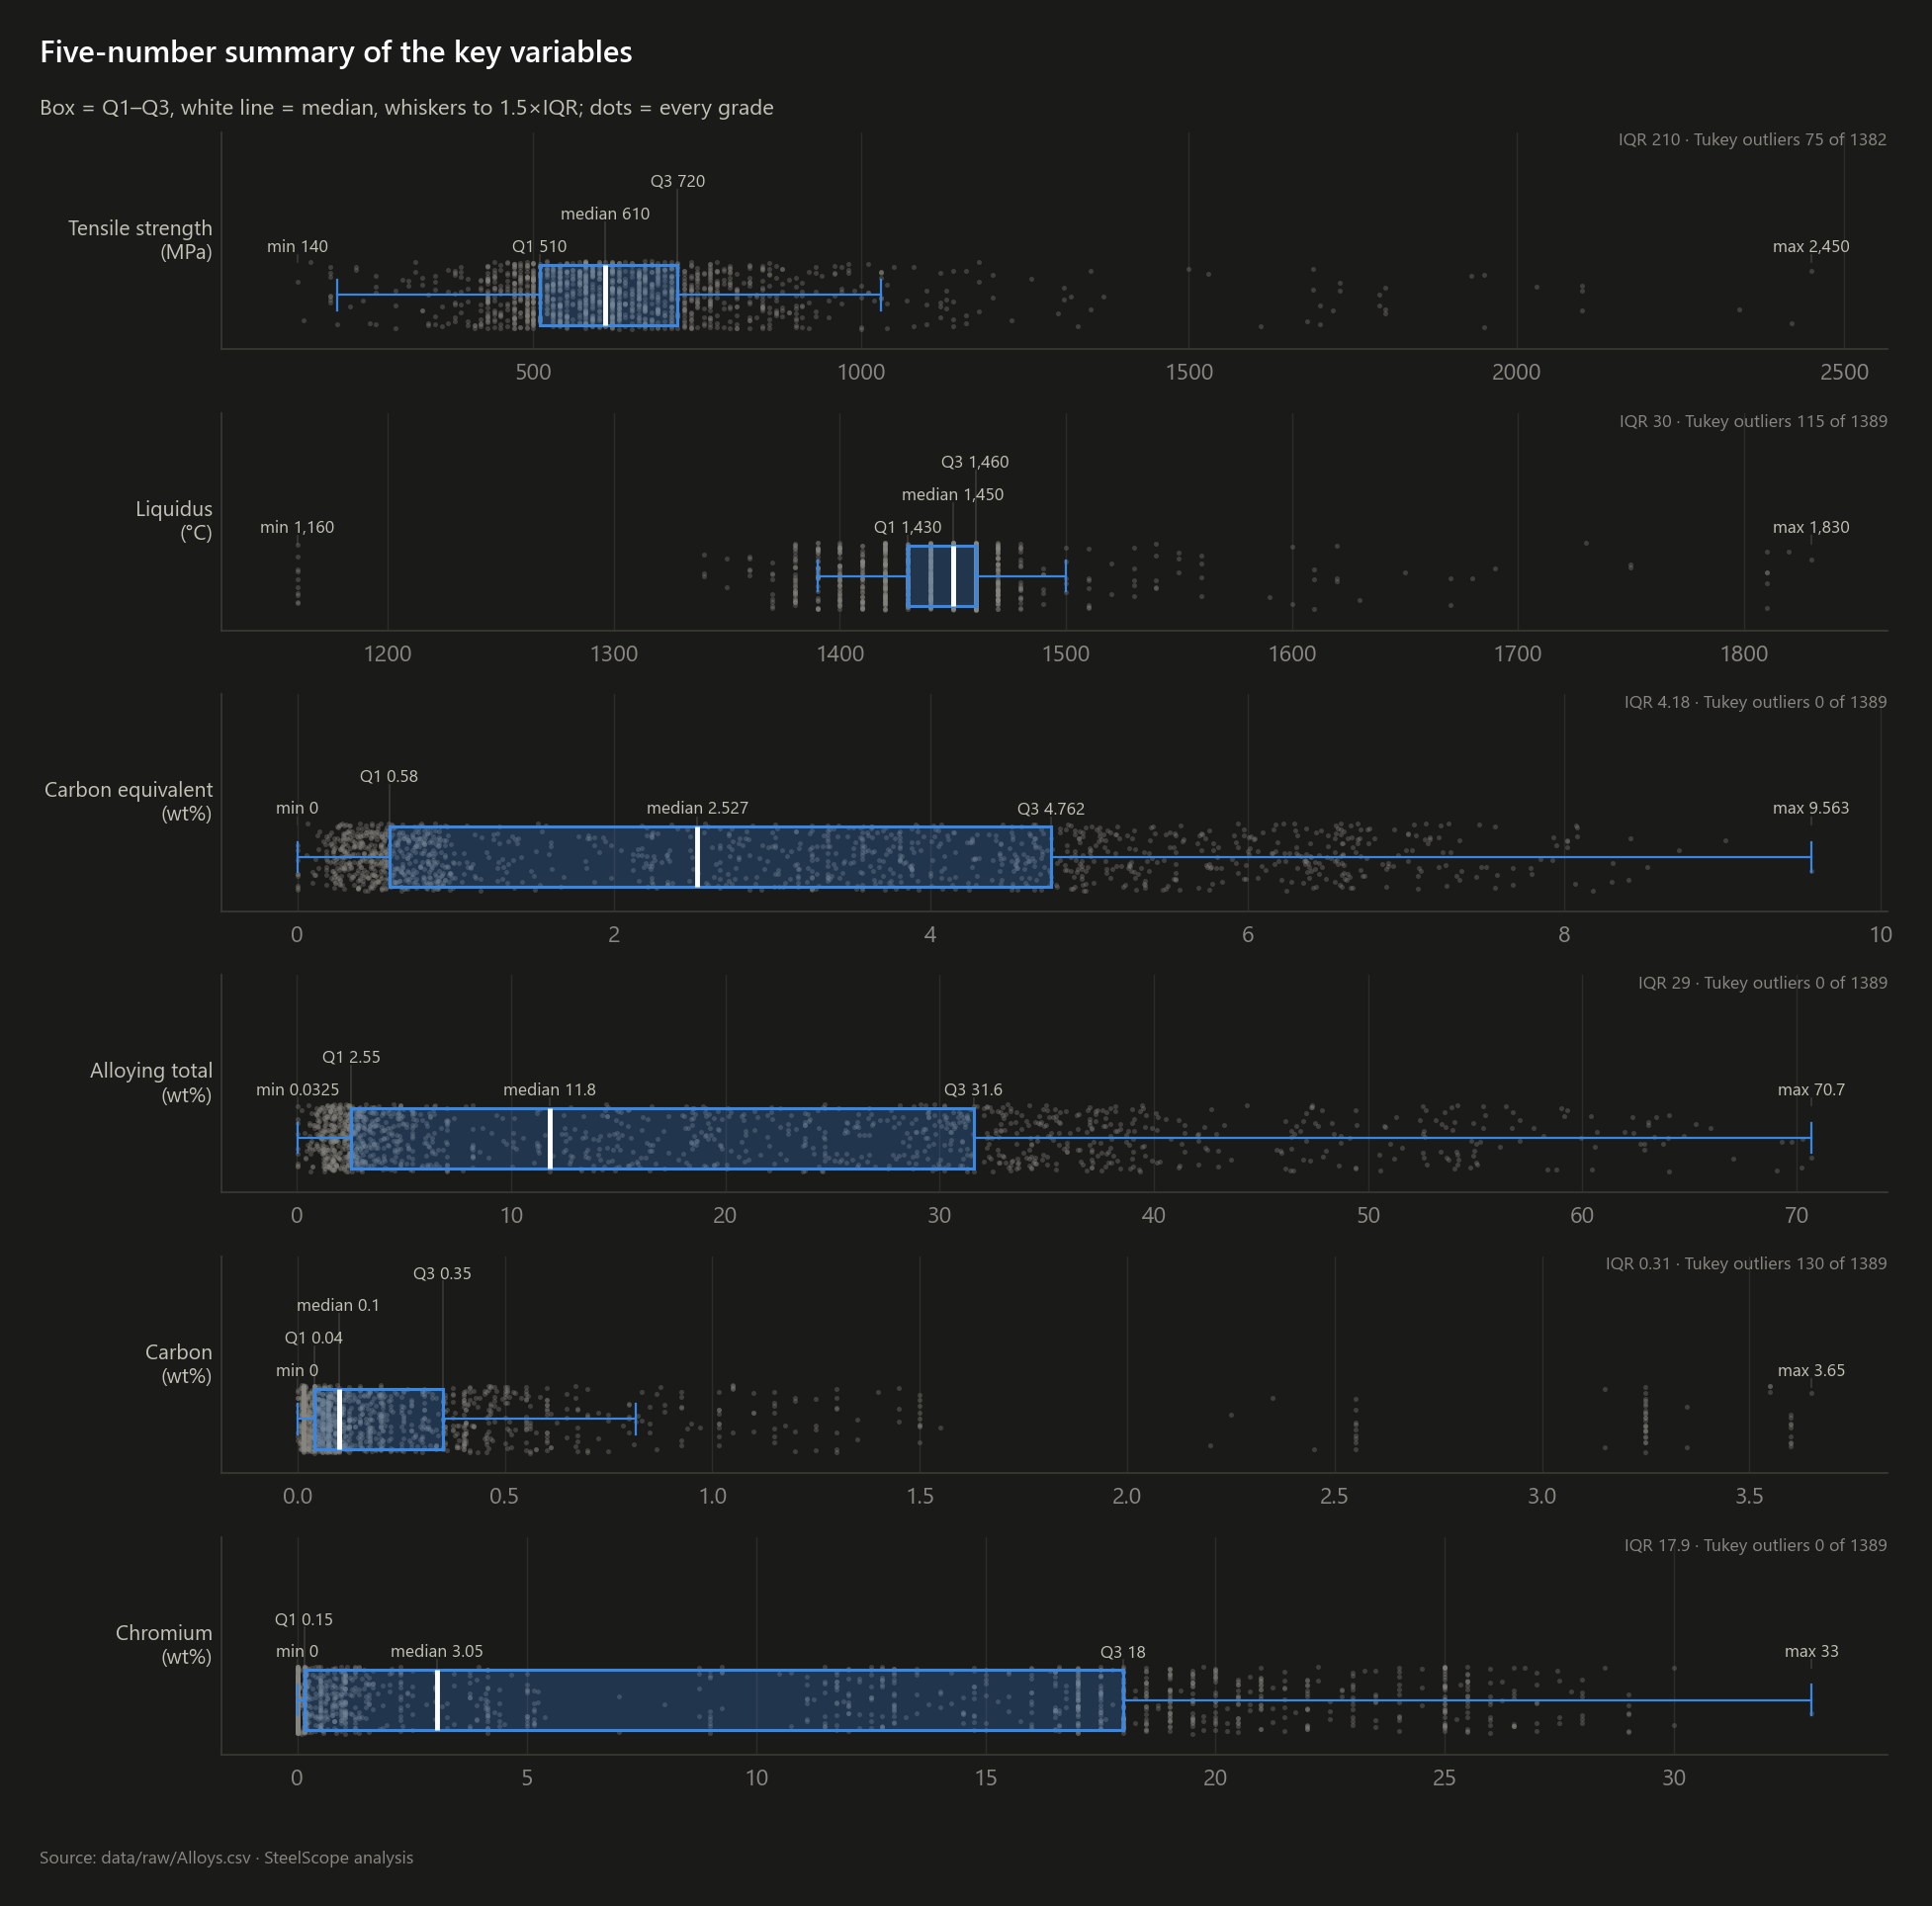

In [3]:
fns = V.five_number_summary(g)
display(fns.round(3))
display(V.descriptive_stats(g).round(3))
show(VS.five_number_boxes(g, fns), "04_01_five_number_summary")

**Reading it.** Tensile strength has a median of 610 MPa with the middle half between 510 and 720 MPa (see the
table), but a long right tail of high-strength grades flagged as Tukey outliers. Liquidus is tightly packed
(IQR of only a few tens of °C) because so many plain steels carry the 1460 °C default. Carbon equivalent and alloy
content are wide and bimodal, which is the plain-steel vs stainless split.

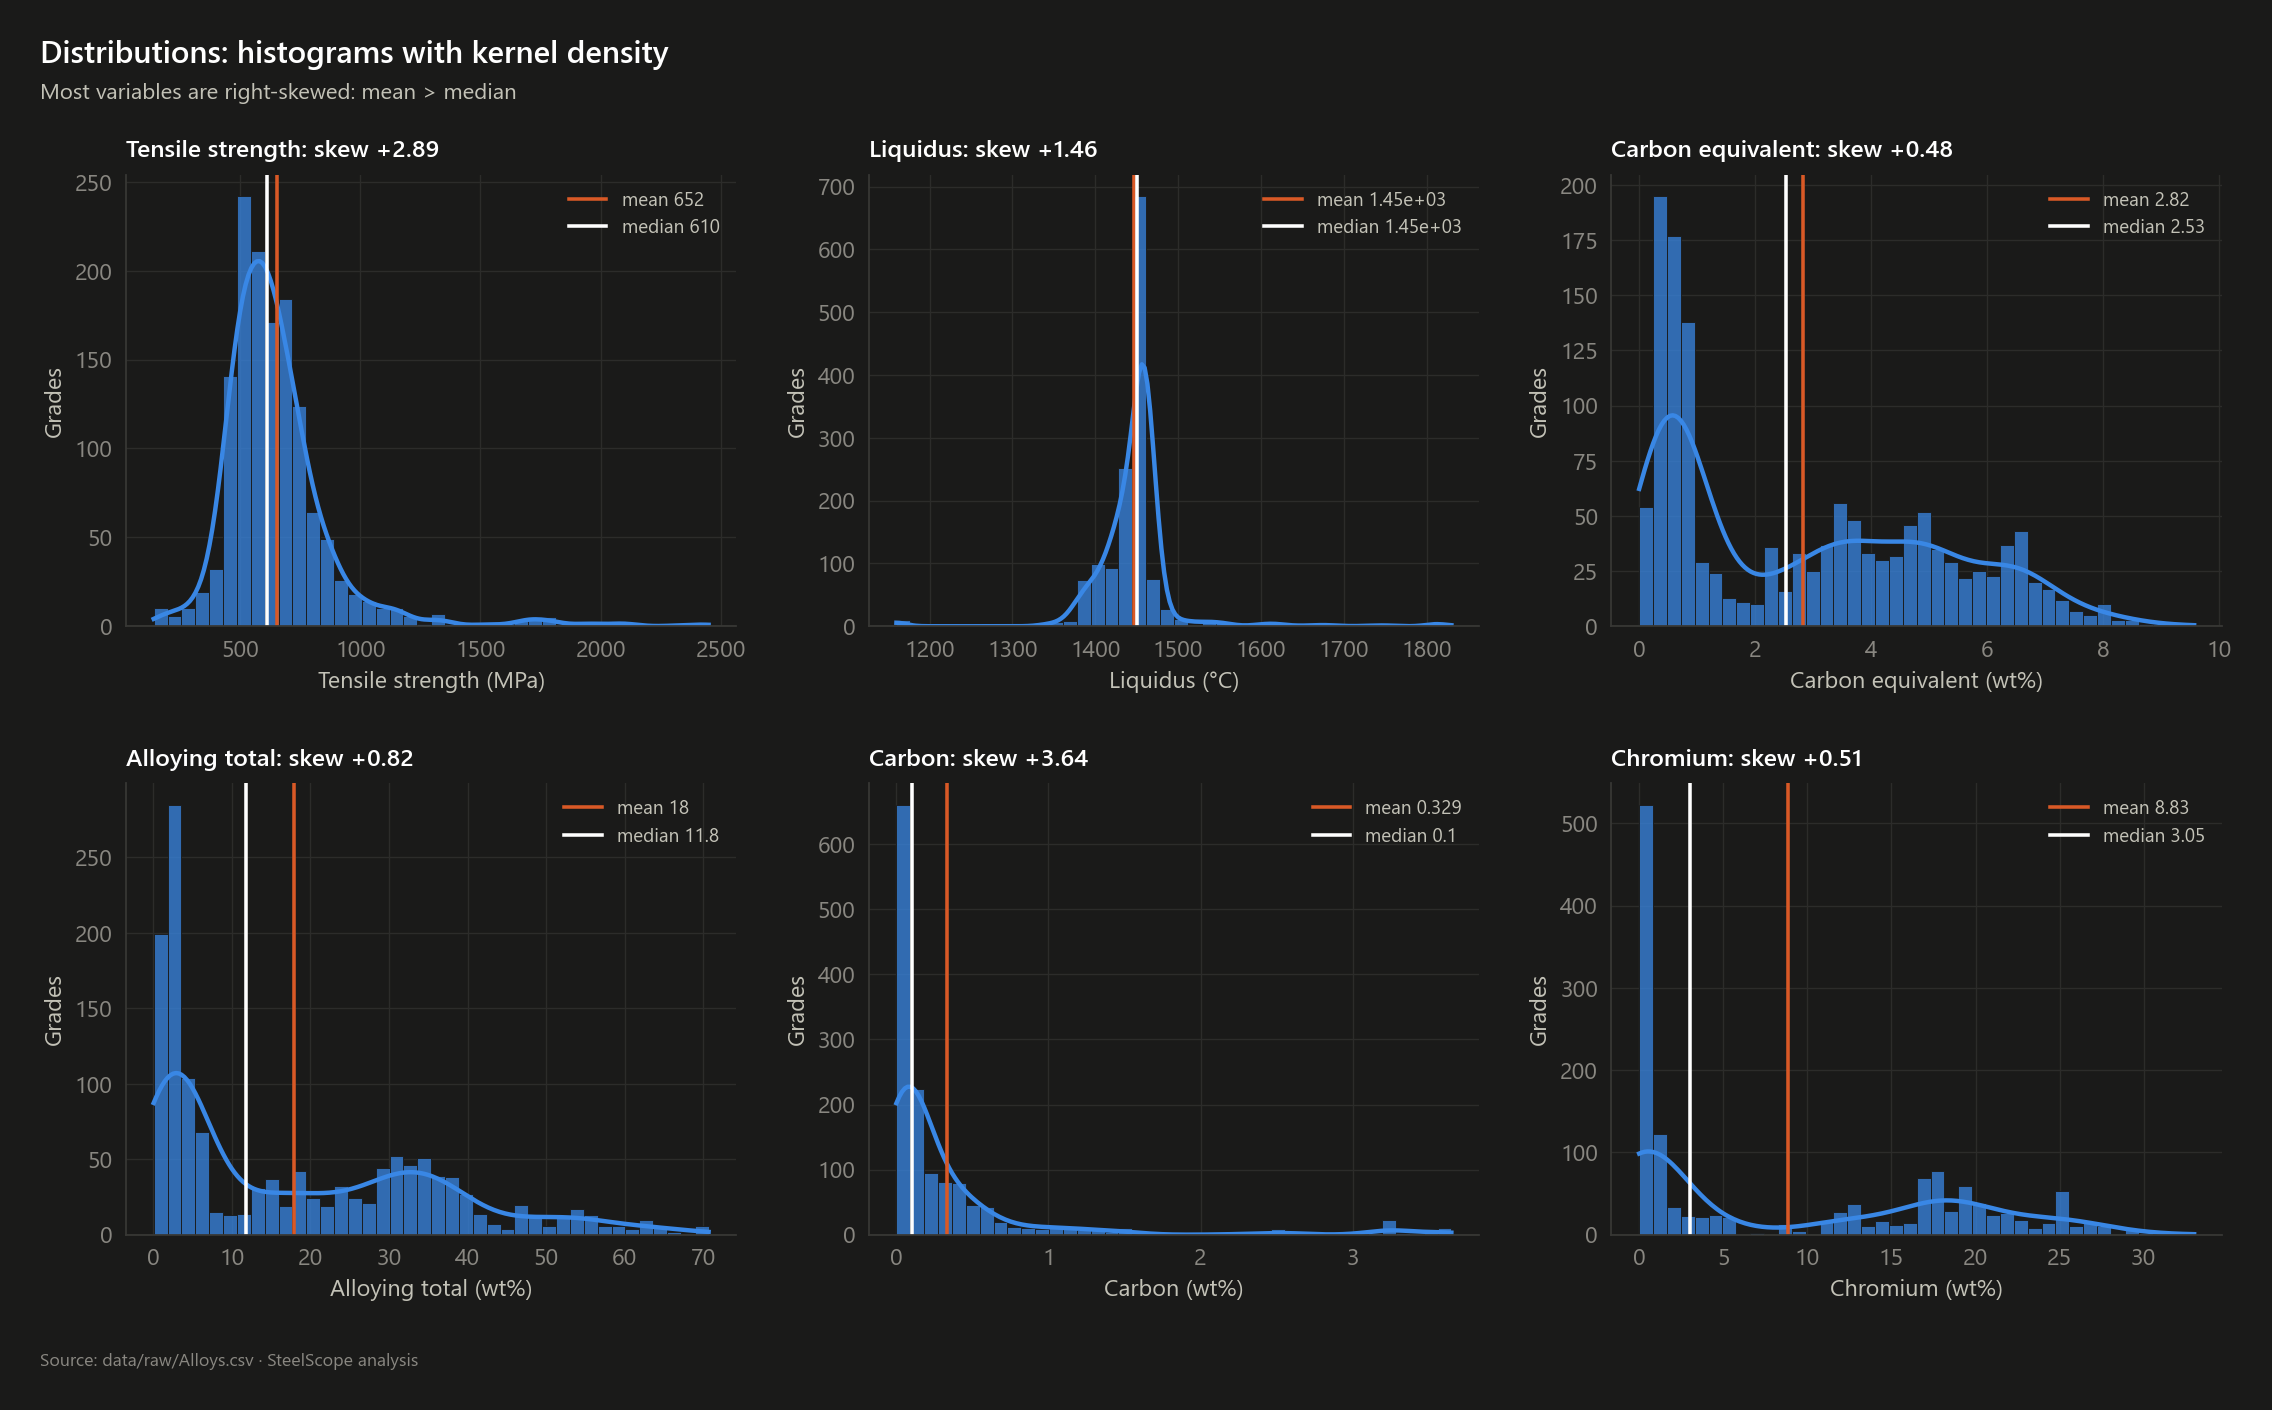

,count,min,Q1,median,Q3,max,mean,std
family_group,,,,,,,,
Cast iron,63.000,140.000,255.000,430.000,520.000,"1,800.000",487.900,339.900
Carbon & low-alloy,583.000,290.000,490.000,570.000,665.000,"2,450.000",623.300,271.200
Weld metal,83.000,500.000,605.000,620.000,710.000,"1,040.000",669.200,108.800
Stainless,543.000,410.000,550.000,630.000,750.000,"1,690.000",675.000,180.300
Tool & high-speed,82.000,330.000,680.000,720.000,795.000,"1,130.000",719.400,115.600
Other,28.000,440.000,507.500,840.000,"1,030.000","2,420.000",906.800,503.400


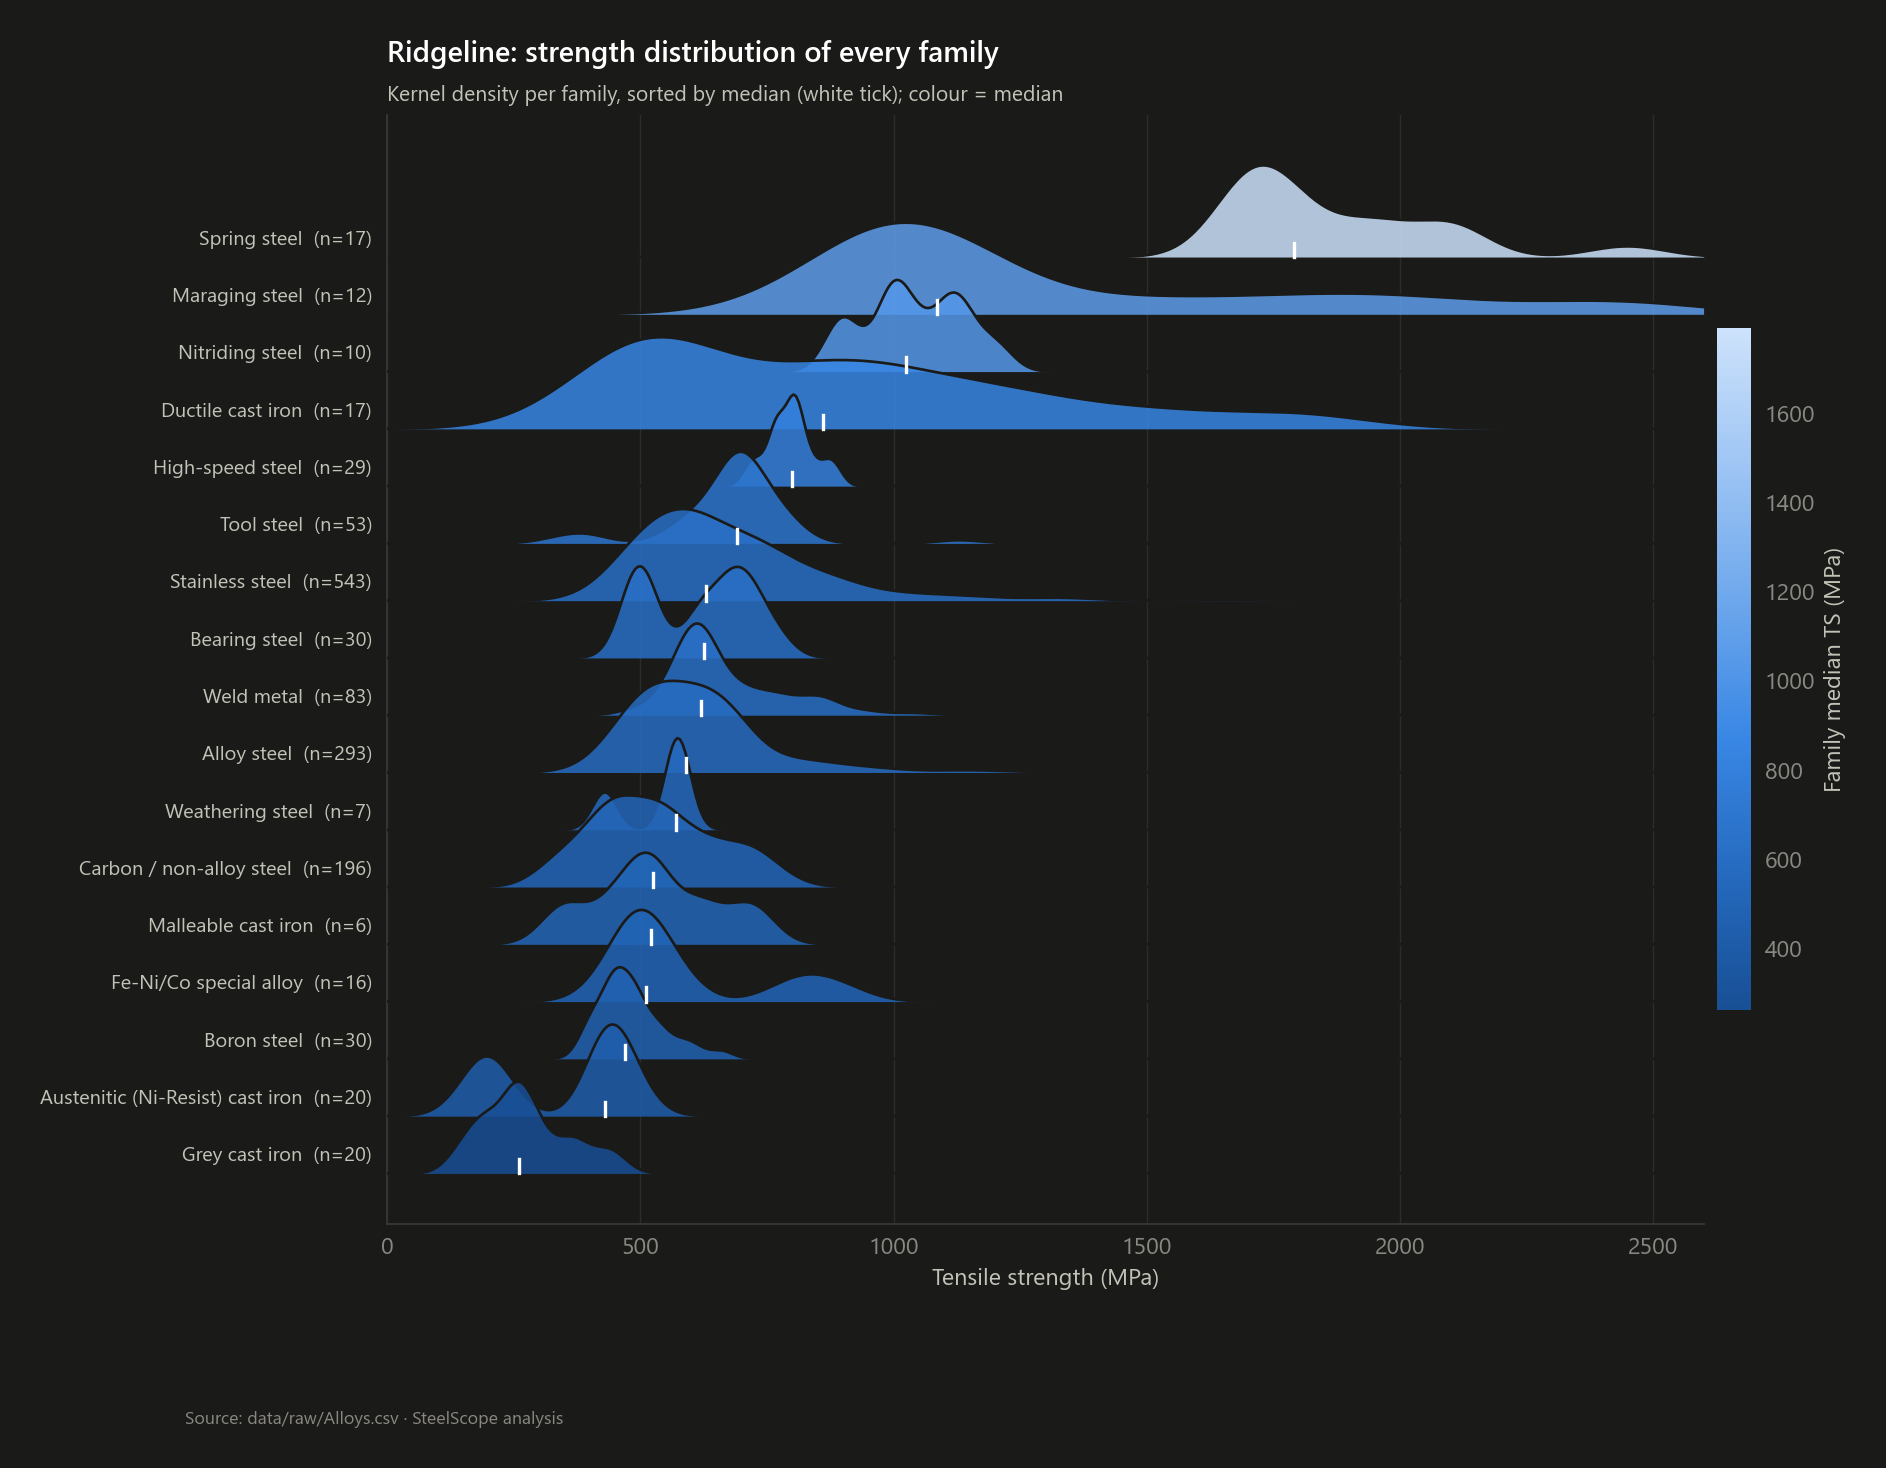

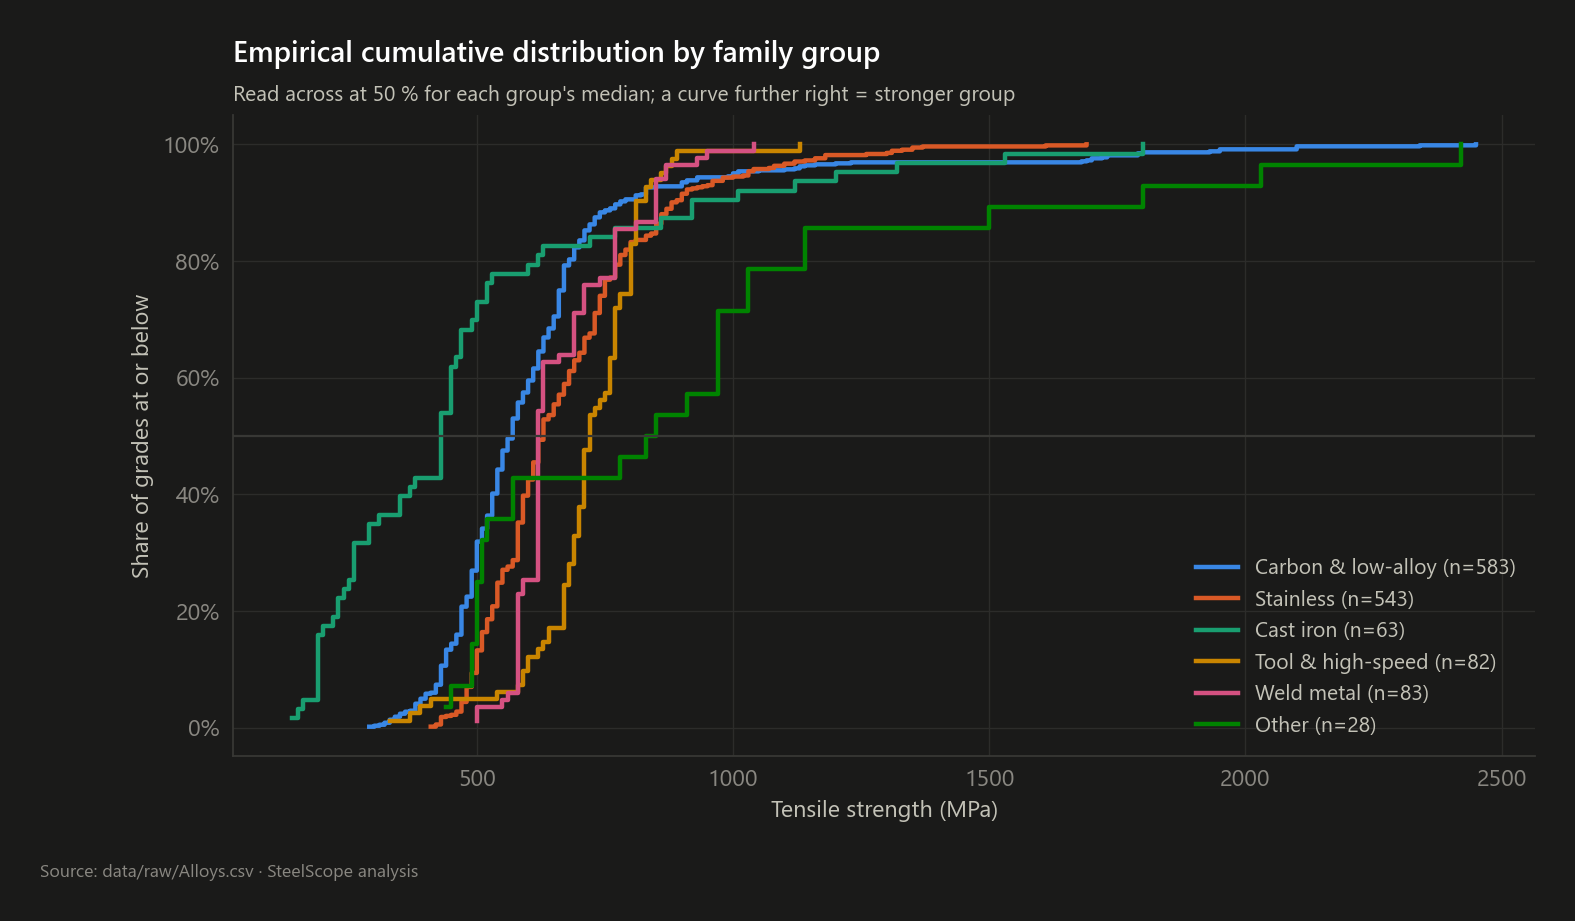

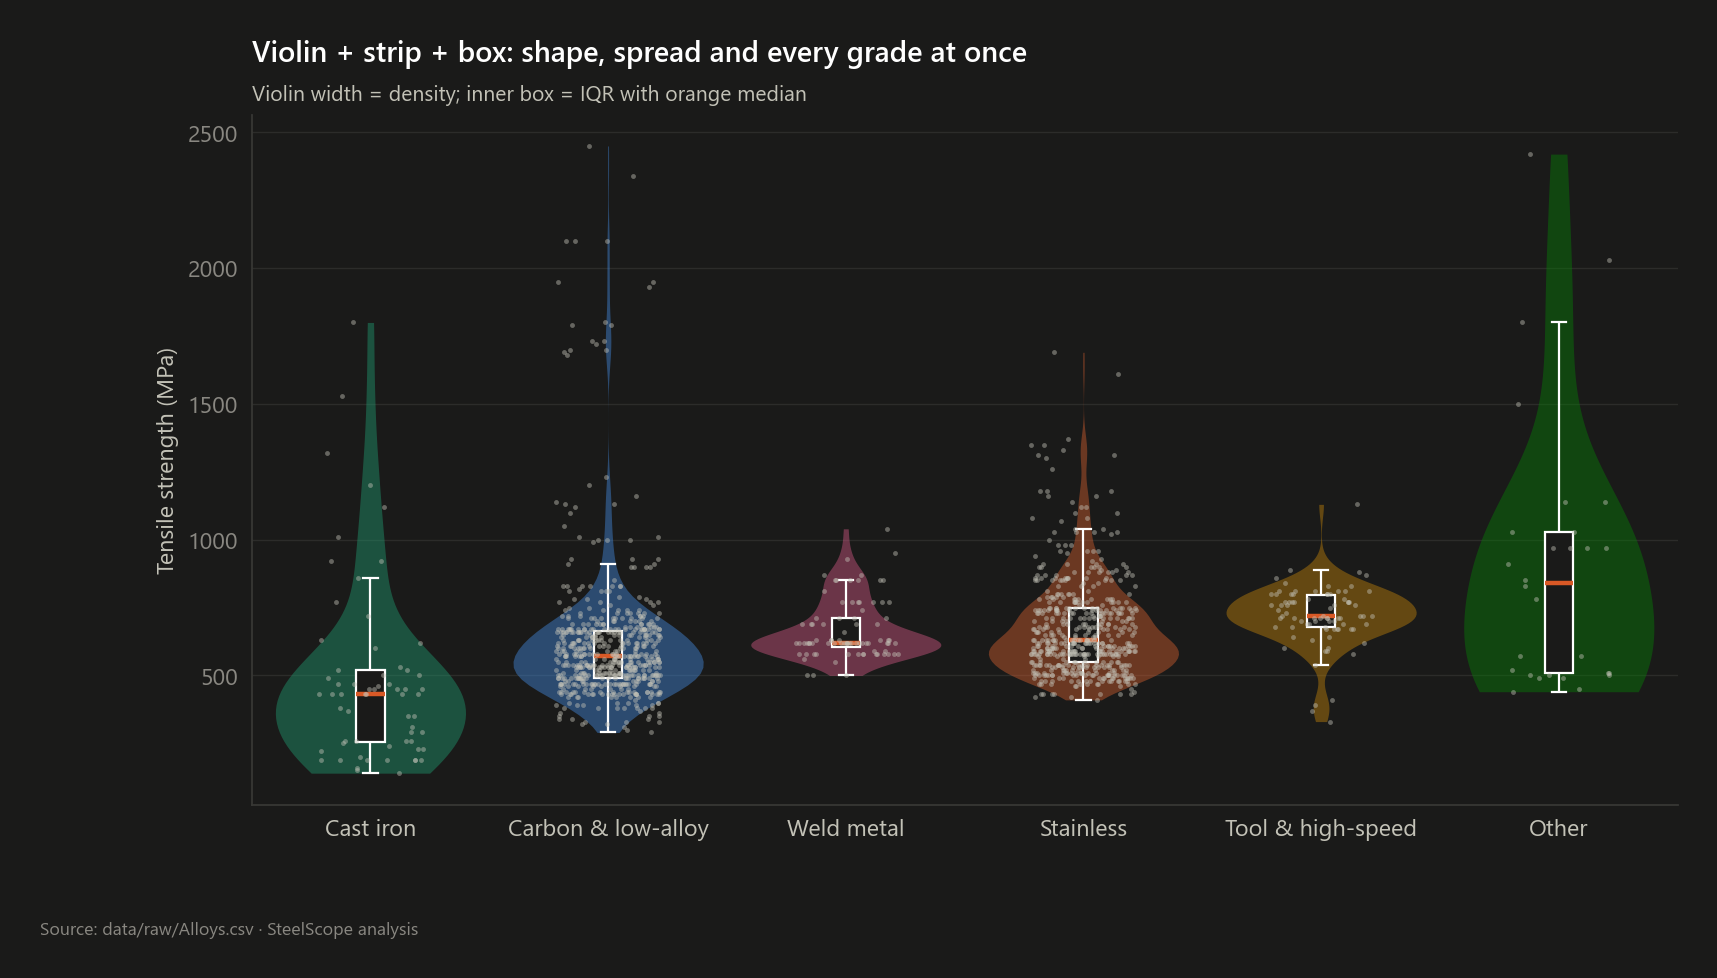

In [4]:
show(VS.distribution_grid(g), "04_02_distributions")
display(V.summary_by_group(g).round(1))
show(VS.ridgeline(g), "04_03_ridgeline_families")
show(VS.ecdf_by_group(g), "04_04_ecdf_groups")
show(VS.violin_strip(g), "04_05_violin_groups")

**Takeaway.** Every chemistry variable is right-skewed (mean above median), so medians and quantiles, not means,
are the honest summaries here. The ridgeline and ECDF show families as shifted, partly overlapping distributions:
a family narrows the strength range but does not fix it.

## 2 · Binning

,bin,n,method,low,high
0,"(137.69, 602.0]",671,equal width,137.690,602.000
1,"(602.0, 1064.0]",650,equal width,602.000,"1,064.000"
2,"(1064.0, 1526.0]",36,equal width,"1,064.000","1,526.000"
3,"(1526.0, 1988.0]",18,equal width,"1,526.000","1,988.000"
4,"(1988.0, 2450.0]",7,equal width,"1,988.000","2,450.000"
5,"(139.999, 500.0]",318,equal frequency (quantile),139.999,500.000
6,"(500.0, 580.0]",284,equal frequency (quantile),500.000,580.000
7,"(580.0, 650.0]",240,equal frequency (quantile),580.000,650.000
8,"(650.0, 750.0]",268,equal frequency (quantile),650.000,750.000
9,"(750.0, 2450.0]",272,equal frequency (quantile),750.000,"2,450.000"


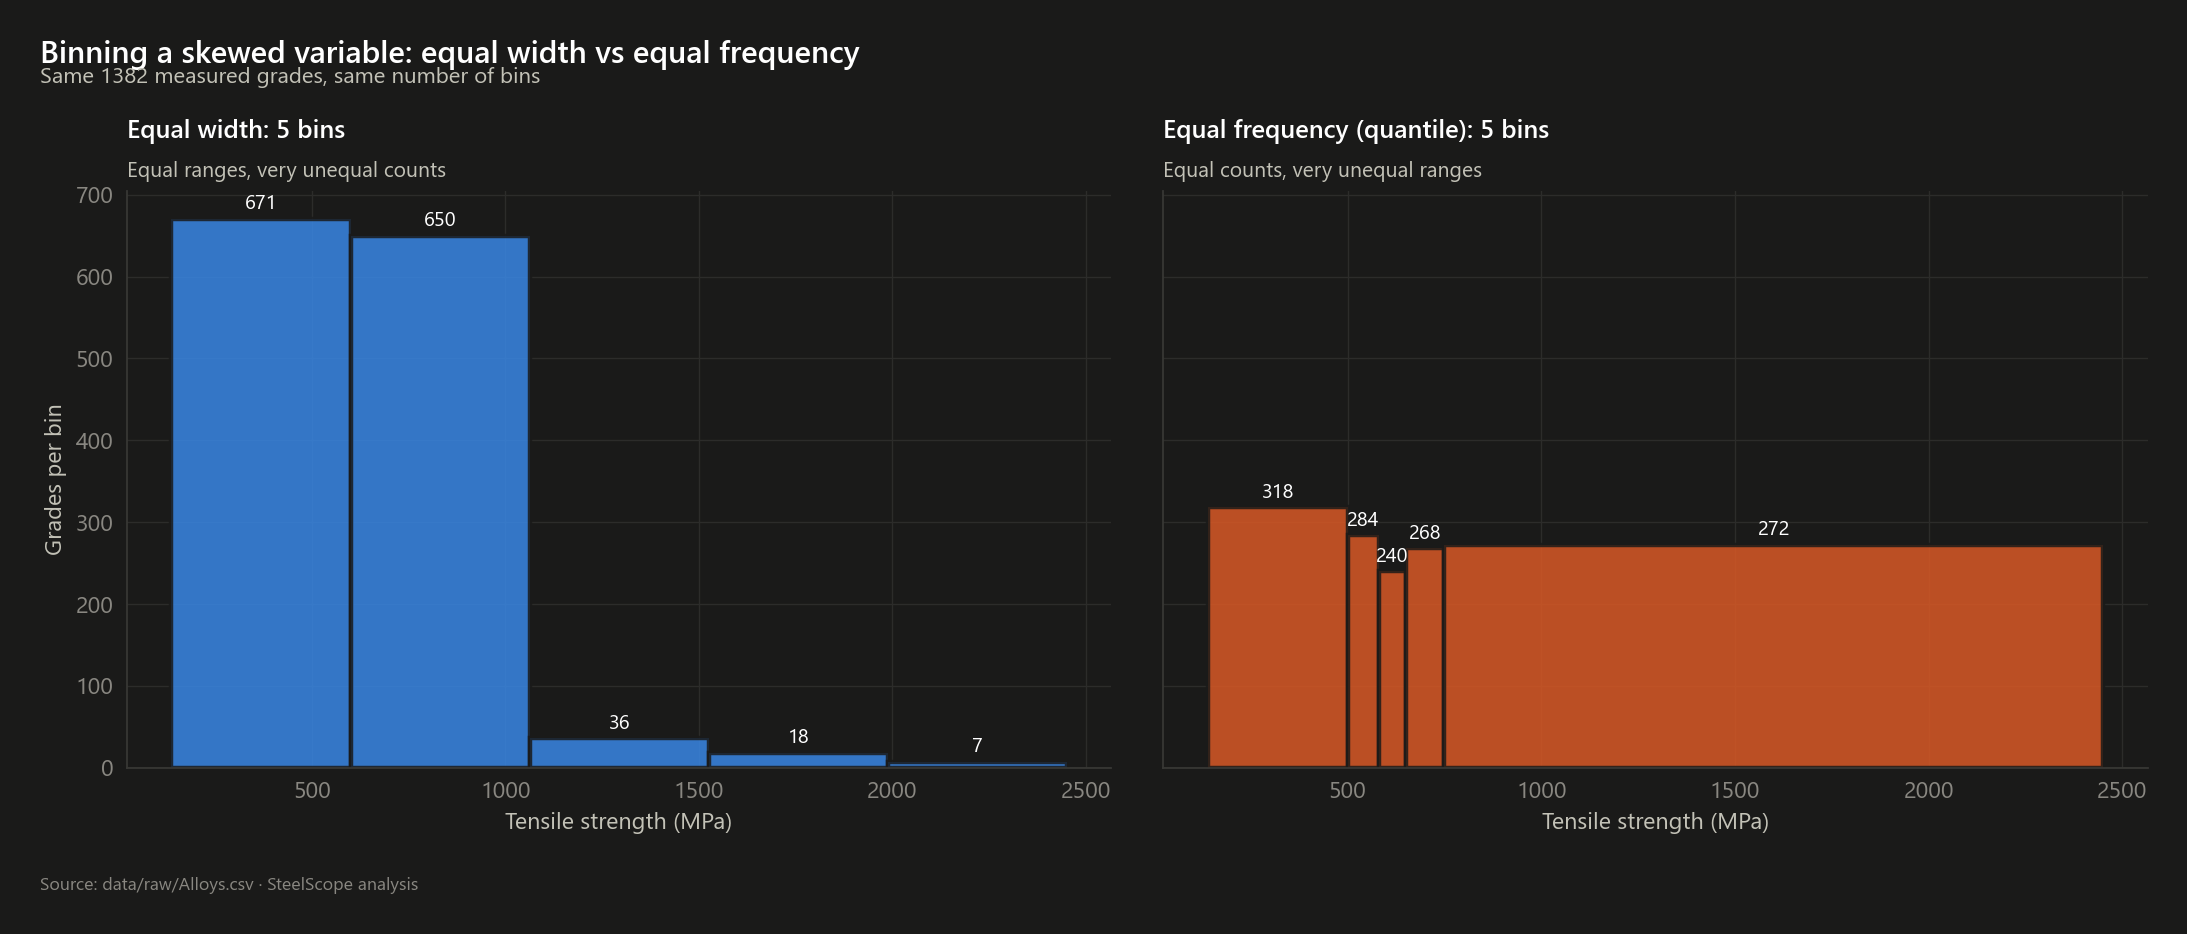

family_group,Carbon & low-alloy,Cast iron,Other,Stainless,Tool & high-speed,Weld metal,All
carbon_band,,,,,,,
Low carbon (≤0.25),357,0,28,495,6,81,967
Medium carbon (0.25–0.60),191,0,0,42,22,2,257
High carbon / tool (0.60–2.1),35,18,0,9,50,0,112
Cast-iron range (>2.1),0,49,0,0,4,0,53
All,583,67,28,546,82,83,1389


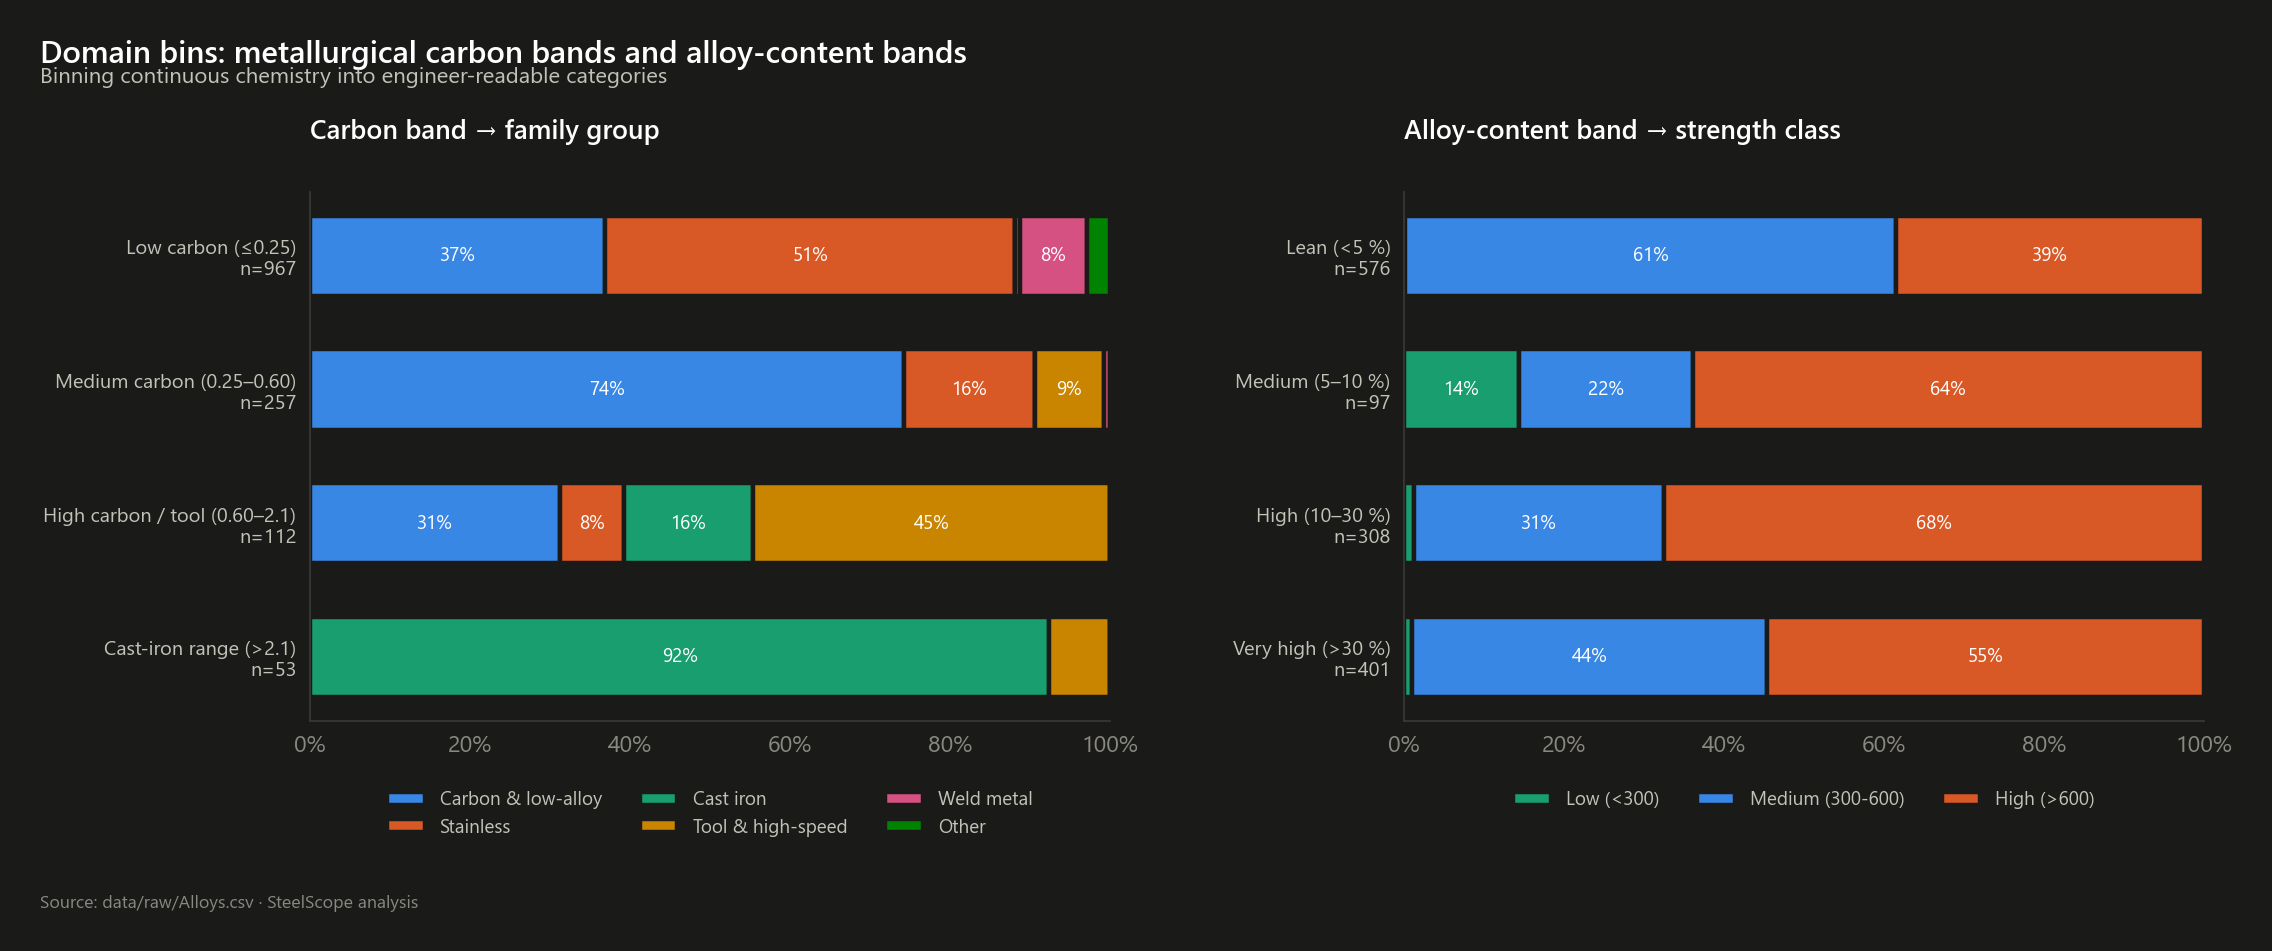

In [5]:
comp = V.binning_comparison(g)
display(comp)
show(VS.binning_comparison(g, comp), "04_06_binning_width_vs_frequency")
b = V.add_bins(g)
display(pd.crosstab(b.carbon_band, b.family_group, margins=True))
show(VS.band_stacks(g), "04_07_domain_bins")

**Takeaway.** On skewed data, equal-width bins pile most grades into one or two bins, while equal-frequency
(quantile) bins balance the counts but stretch the top bin over a huge range. Domain bins (carbon bands, alloy
bands) are the most useful for engineers: the "cast-iron range" carbon band is almost entirely cast iron, and the
share of high-strength grades rises steadily with alloy content.

## 3 · Chi-square tests of independence

,test,rows,columns,n,chi2,dof,p_value,p_permutation,cramers_v,share_expected_lt5,asymptotic_valid
0,Family group × strength class,family_group,strength_class_name,1382,548.727,10,0.000,0.001,0.446,0.222,False
1,Product form × strength class,product_form,strength_class_name,1382,117.366,4,0.000,0.001,0.206,0.222,False
2,Carbon band × strength class,carbon_band,strength_class_name,1382,315.849,6,0.000,0.001,0.338,0.250,False
3,CE weldability band × strength class (plain steels),ce_band,strength_class_name,583,198.216,4,0.000,0.001,0.412,0.333,False
4,Family group × default liquidus,family_group,liquidus_is_default,1389,631.972,5,0.000,0.001,0.674,0.000,True


Family group × strength class


strength_class_name,Low (<300),Medium (300-600),High (>600)
family_group,,,
Carbon & low-alloy,1,346,236
Cast iron,22,28,13
Other,0,12,16
Stainless,0,231,312
Tool & high-speed,0,10,72
Weld metal,0,21,62


strength_class_name,Low (<300),Medium (300-600),High (>600)
family_group,,,
Carbon & low-alloy,9.700,273.400,299.900
Cast iron,1.000,29.500,32.400
Other,0.500,13.100,14.400
Stainless,9.000,254.600,279.400
Tool & high-speed,1.400,38.400,42.200
Weld metal,1.400,38.900,42.700


Product form × strength class


strength_class_name,Low (<300),Medium (300-600),High (>600)
product_form,,,
cast,22,127,101
weld,0,21,62
wrought,1,500,548


strength_class_name,Low (<300),Medium (300-600),High (>600)
product_form,,,
cast,4.200,117.200,128.600
weld,1.400,38.900,42.700
wrought,17.500,491.900,539.700


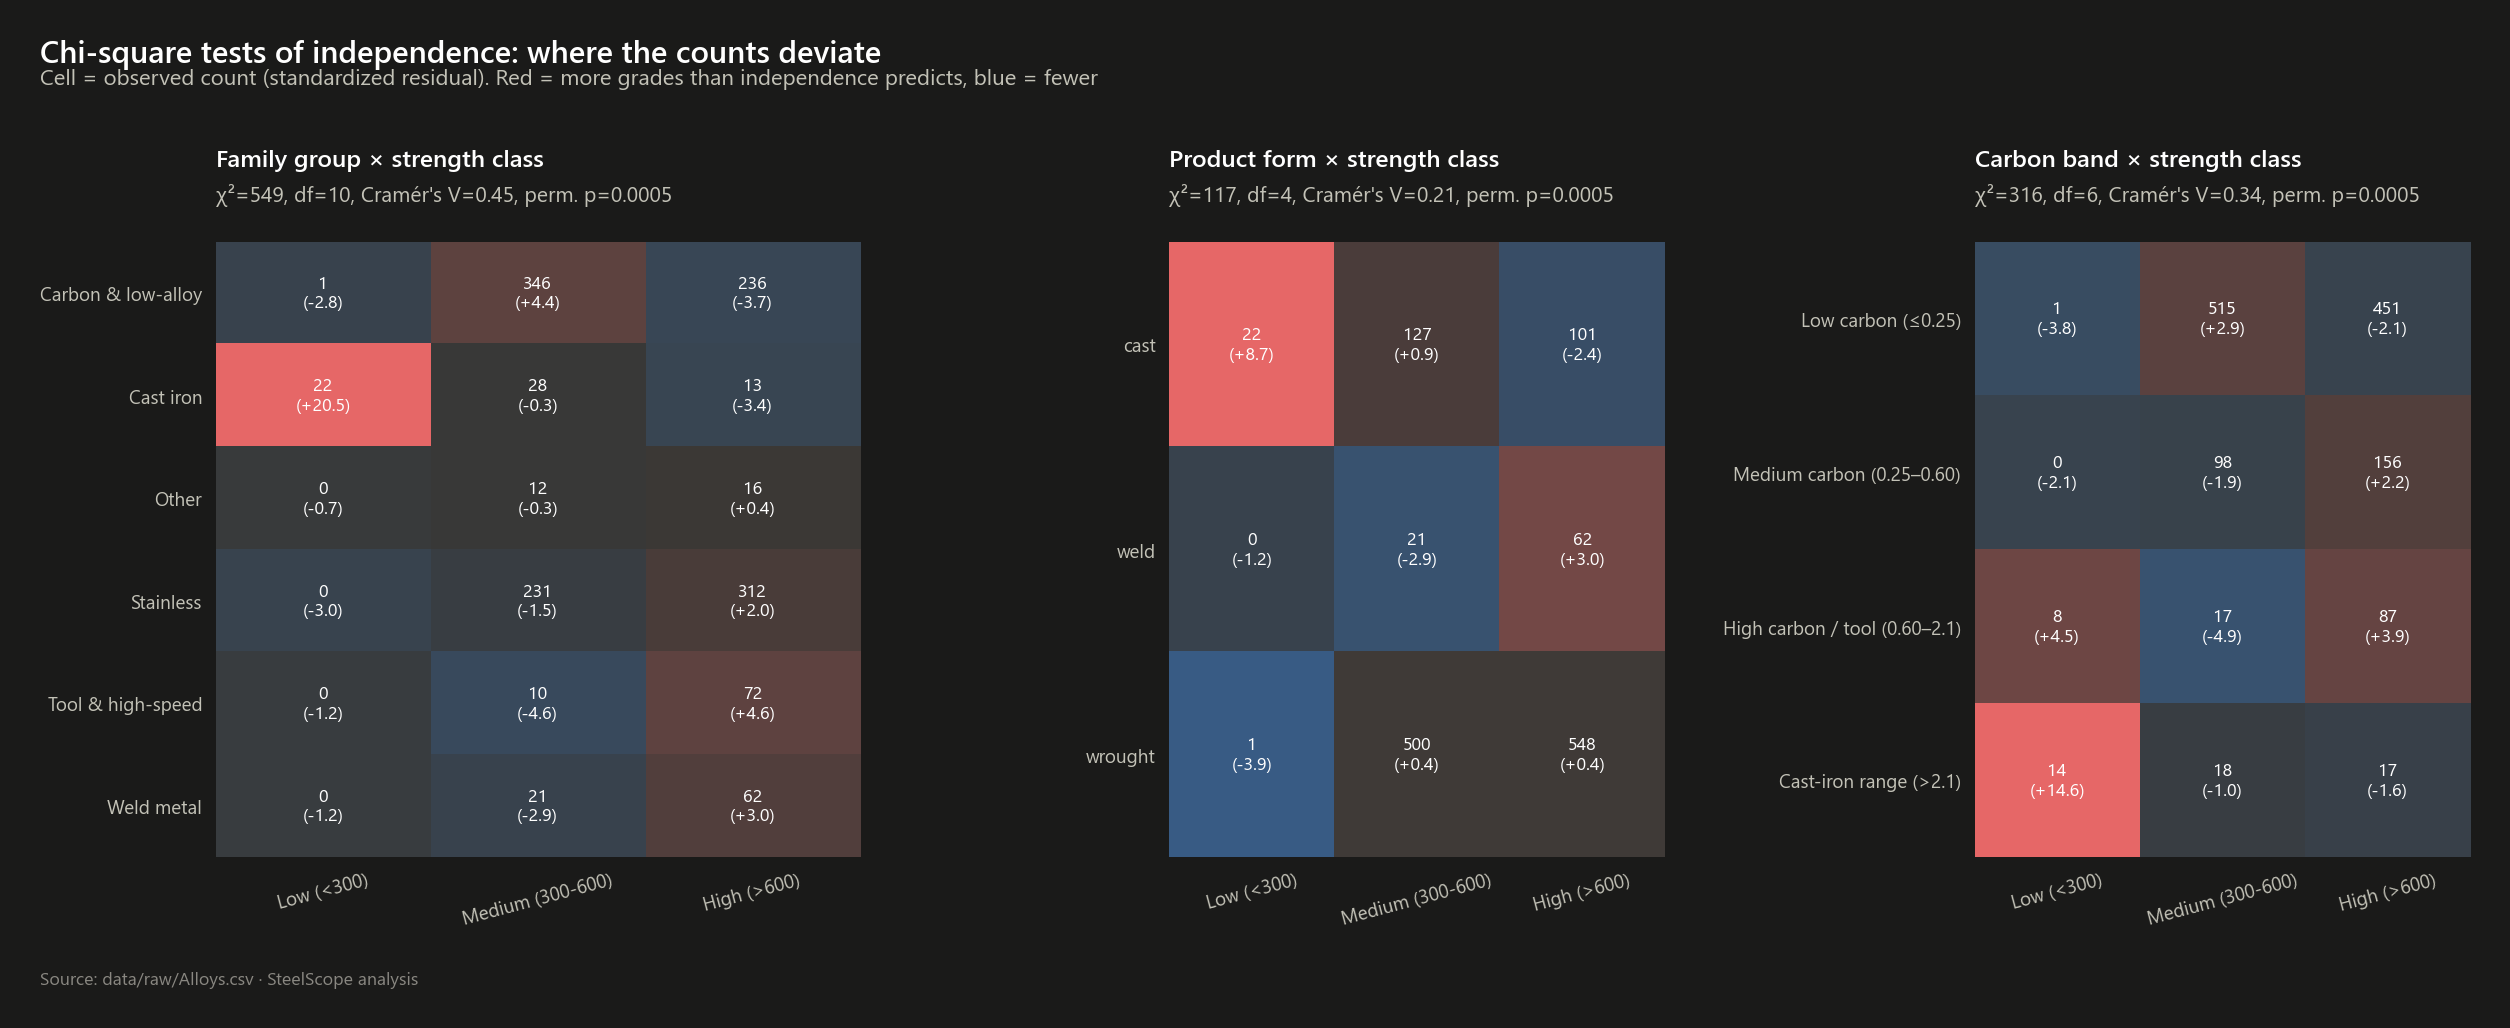

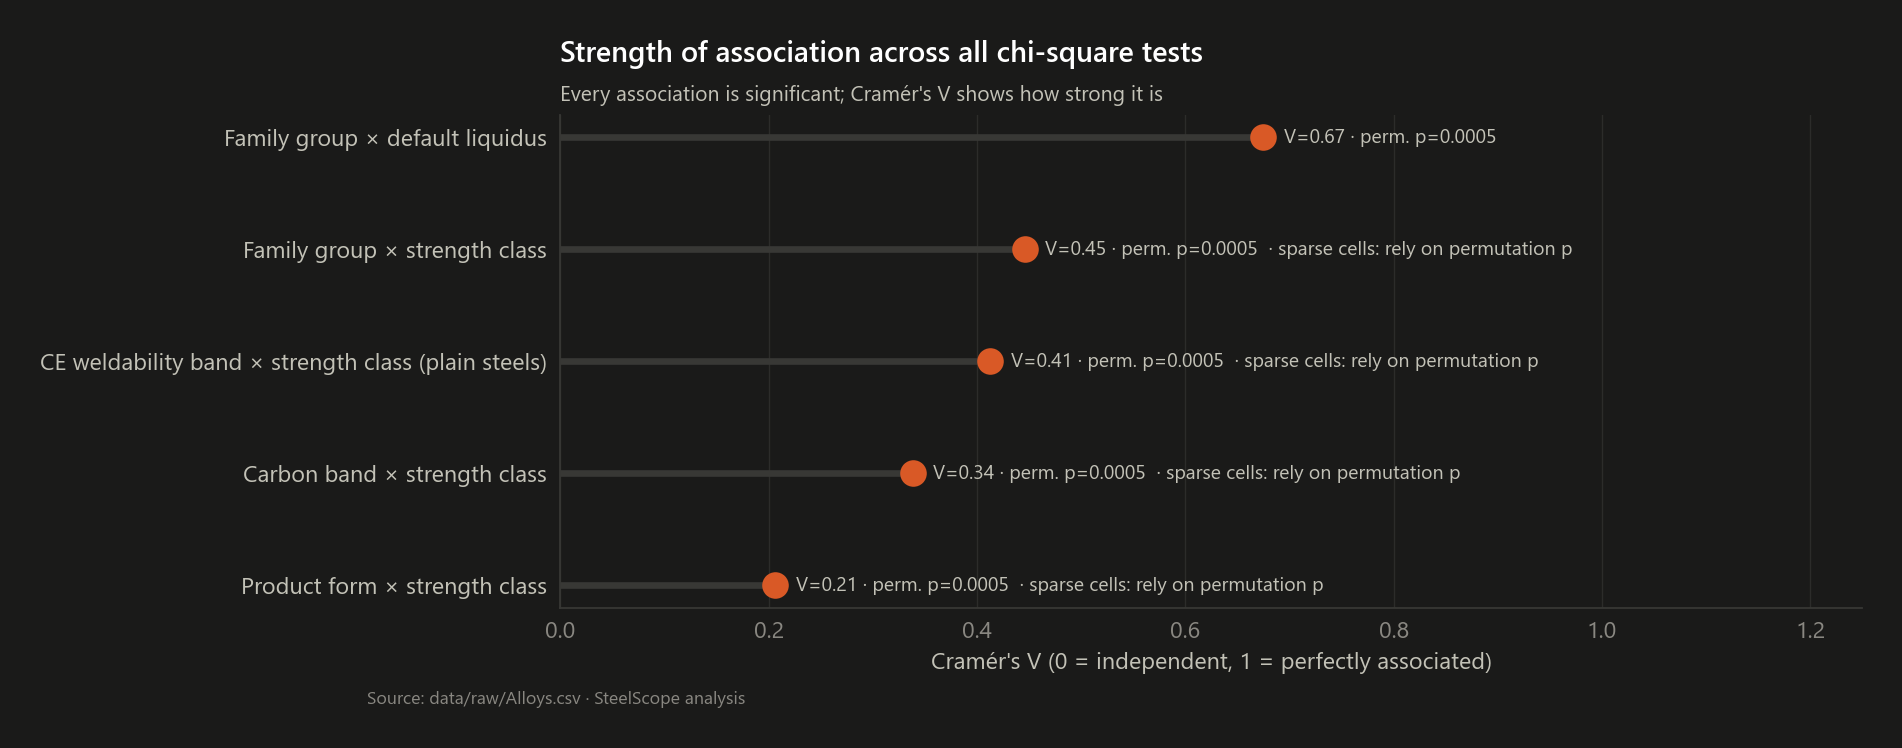

In [6]:
chi = V.chi_square_suite(grades)
display(pd.DataFrame([r.as_row() for r in chi]).round(4))
for r in chi[:2]:
    print(r.name); display(r.observed); display(r.expected.round(1))
show(VS.chi_square_panels(chi), "04_08_chi_square_residuals")
show(VS.cramers_lollipop(chi), "04_09_cramers_v")

**Reading the tests.** H₀ for each test: the two categorical variables are independent. All five are rejected.
Several tables break Cochran's rule (more than 20 % of cells with expected count < 5) because the low strength
class is tiny. For those, the **Monte-Carlo permutation p-value** is the one to quote, and it agrees.
**Cramér's V** says how strong each association is:

* family group ↔ default liquidus is the strongest: the 1460 °C default is a family property (notebook 01);
* family group ↔ strength class and the CE band ↔ strength class (in plain steels) are moderate-to-strong;
* product form ↔ strength class is weak but real: cast grades are under-represented in the high class.

## 4 · Correlation and regression

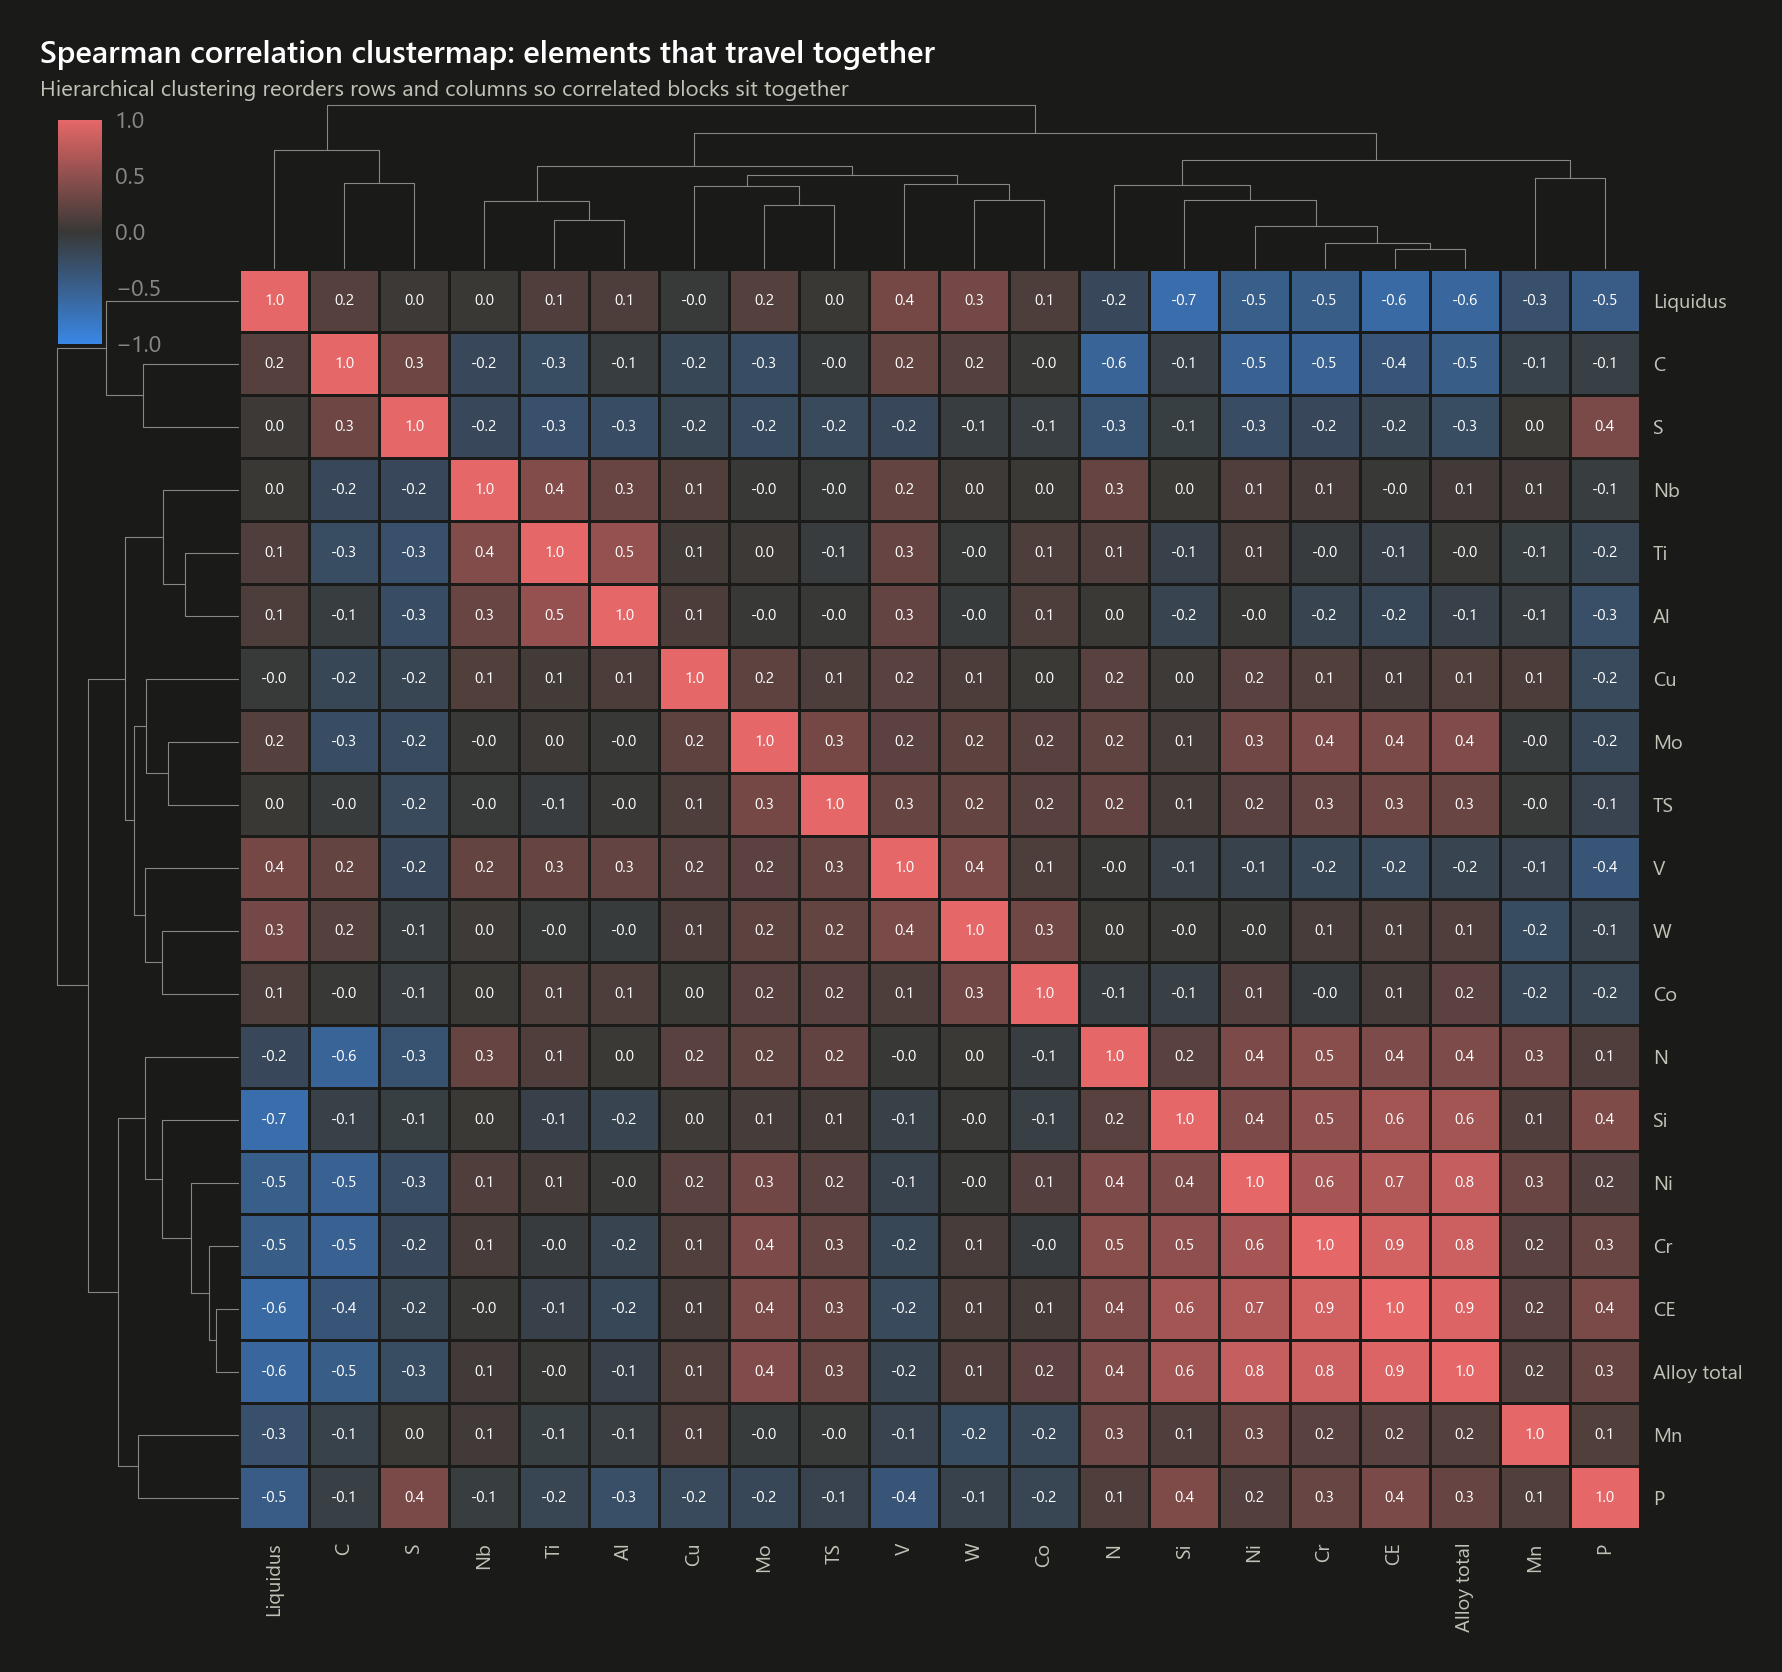

Simple OLS, carbon steels:


,coef,std_err,t,p_value,ci95_low,ci95_high
Intercept,429.185,9.283,46.236,0.000,410.878,447.493
C,428.627,30.272,14.159,0.000,368.922,488.331


R2 = 0.508, n = 196


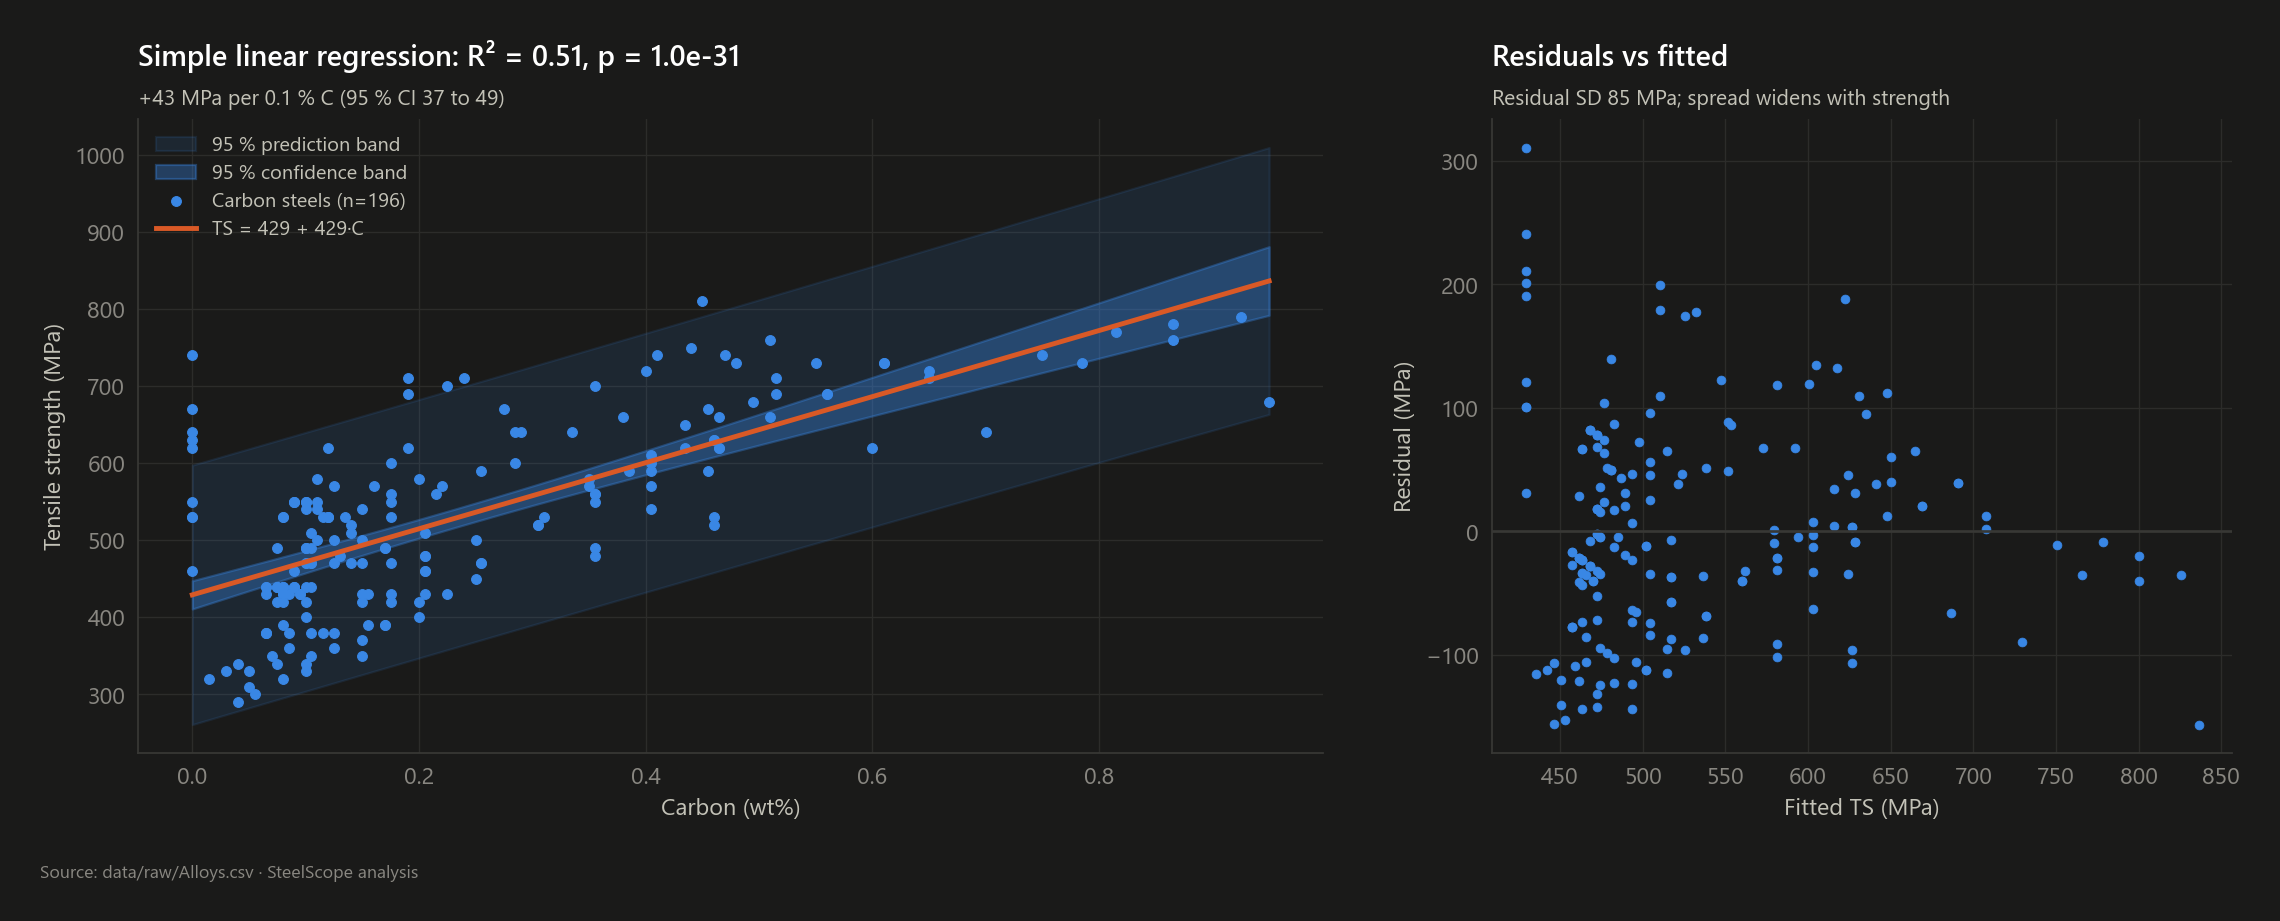

In [7]:
show(VS.correlation_clustermap(g), "04_10_correlation_clustermap")
reg = V.regression_suite(grades)
print("Simple OLS, carbon steels:"); display(reg["simple"].table().round(3))
print(f"R2 = {reg['simple'].r2:.3f}, n = {reg['simple'].n}")
show(VS.simple_regression(reg), "04_11_simple_regression")

Multiple OLS, carbon & low-alloy steels (MPa per wt%):


,coef,std_err,t,p_value,ci95_low,ci95_high
Intercept,404.040,32.000,12.630,0.000,341.190,466.890
C,648.500,53.210,12.190,0.000,544.000,753.010
Mn,-19.570,32.650,-0.600,0.550,-83.710,44.560
Si,193.330,32.910,5.880,0.000,128.700,257.960
Cr,19.720,7.950,2.480,0.010,4.110,35.330
Ni,23.840,7.100,3.360,0.000,9.900,37.770
Mo,-74.220,37.520,-1.980,0.050,-147.910,-0.530
V,362.180,106.440,3.400,0.000,153.120,571.250


R2 = 0.326, adj R2 = 0.317, F = 39.0, n = 574


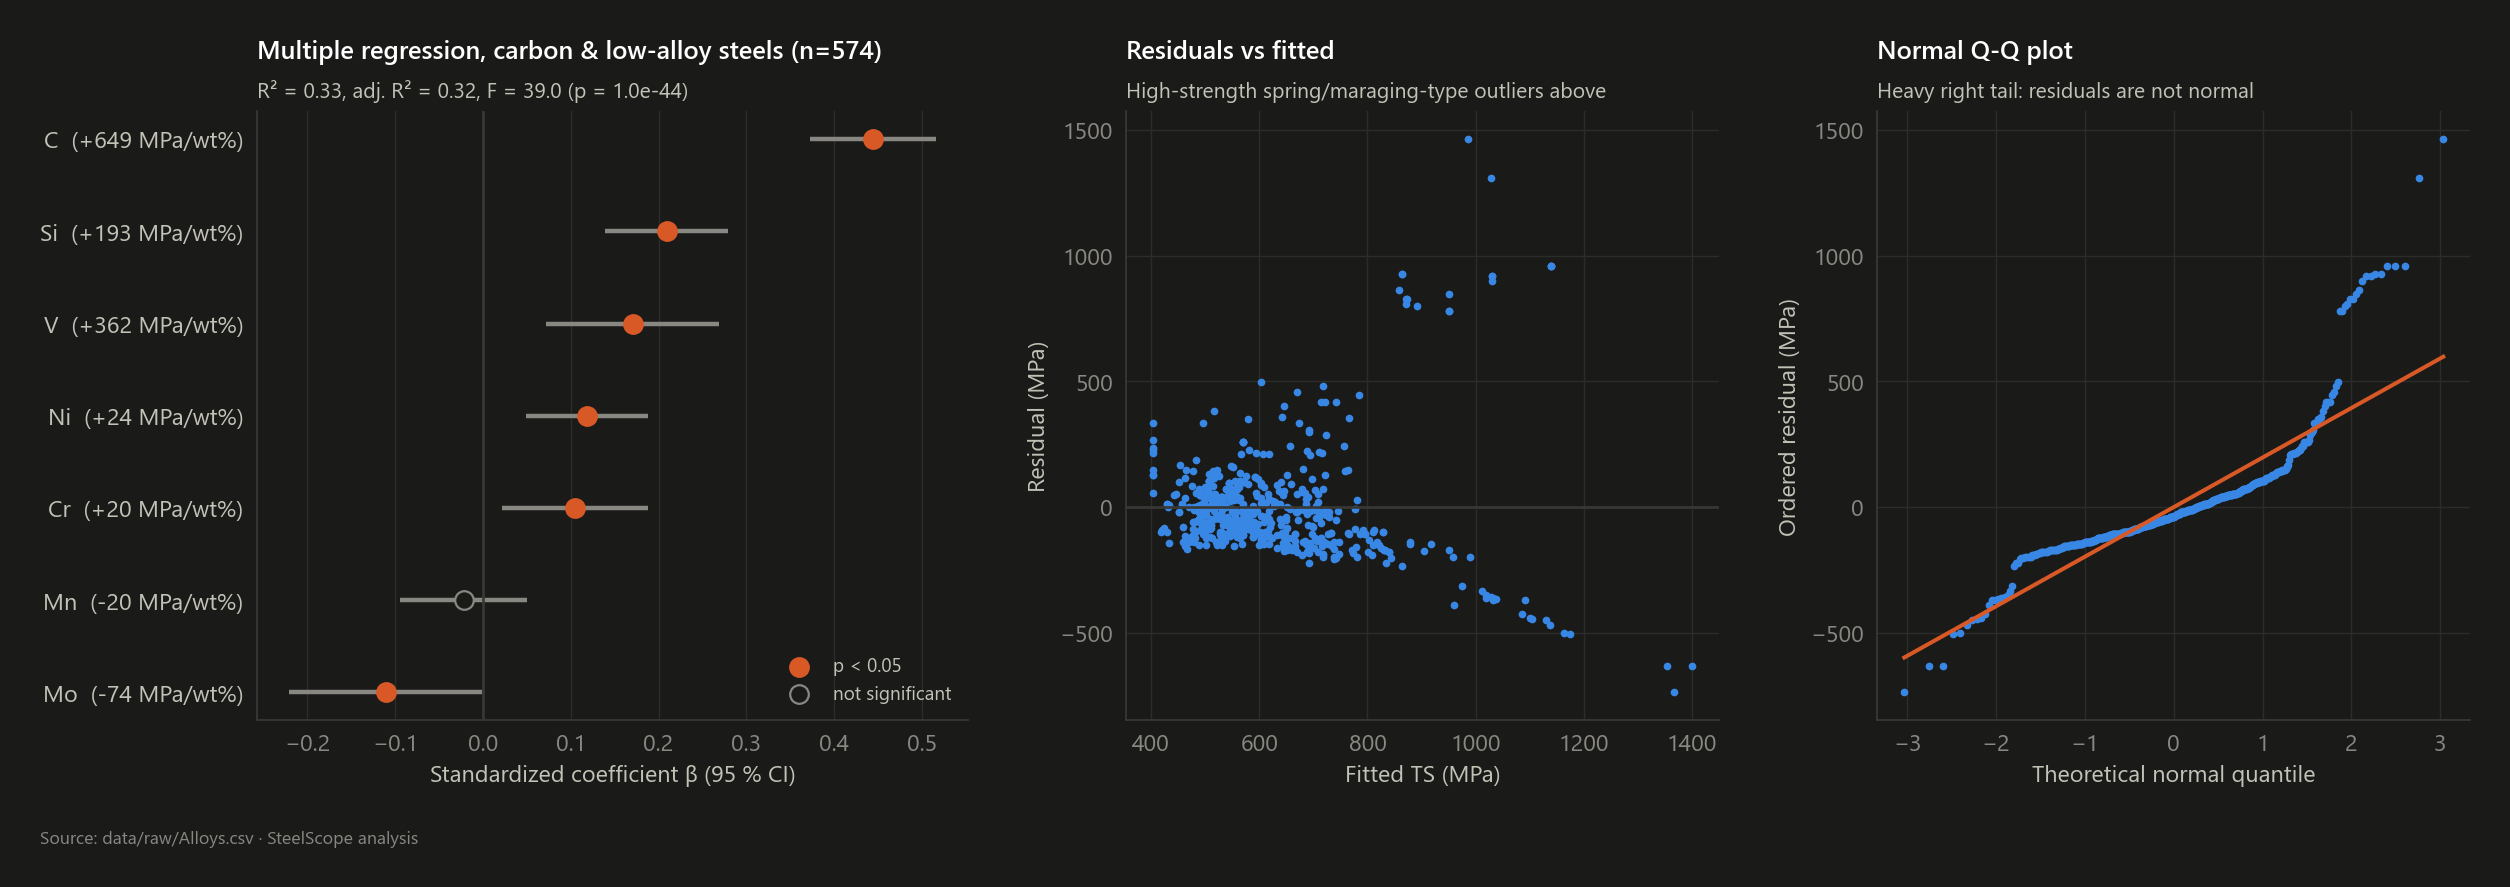

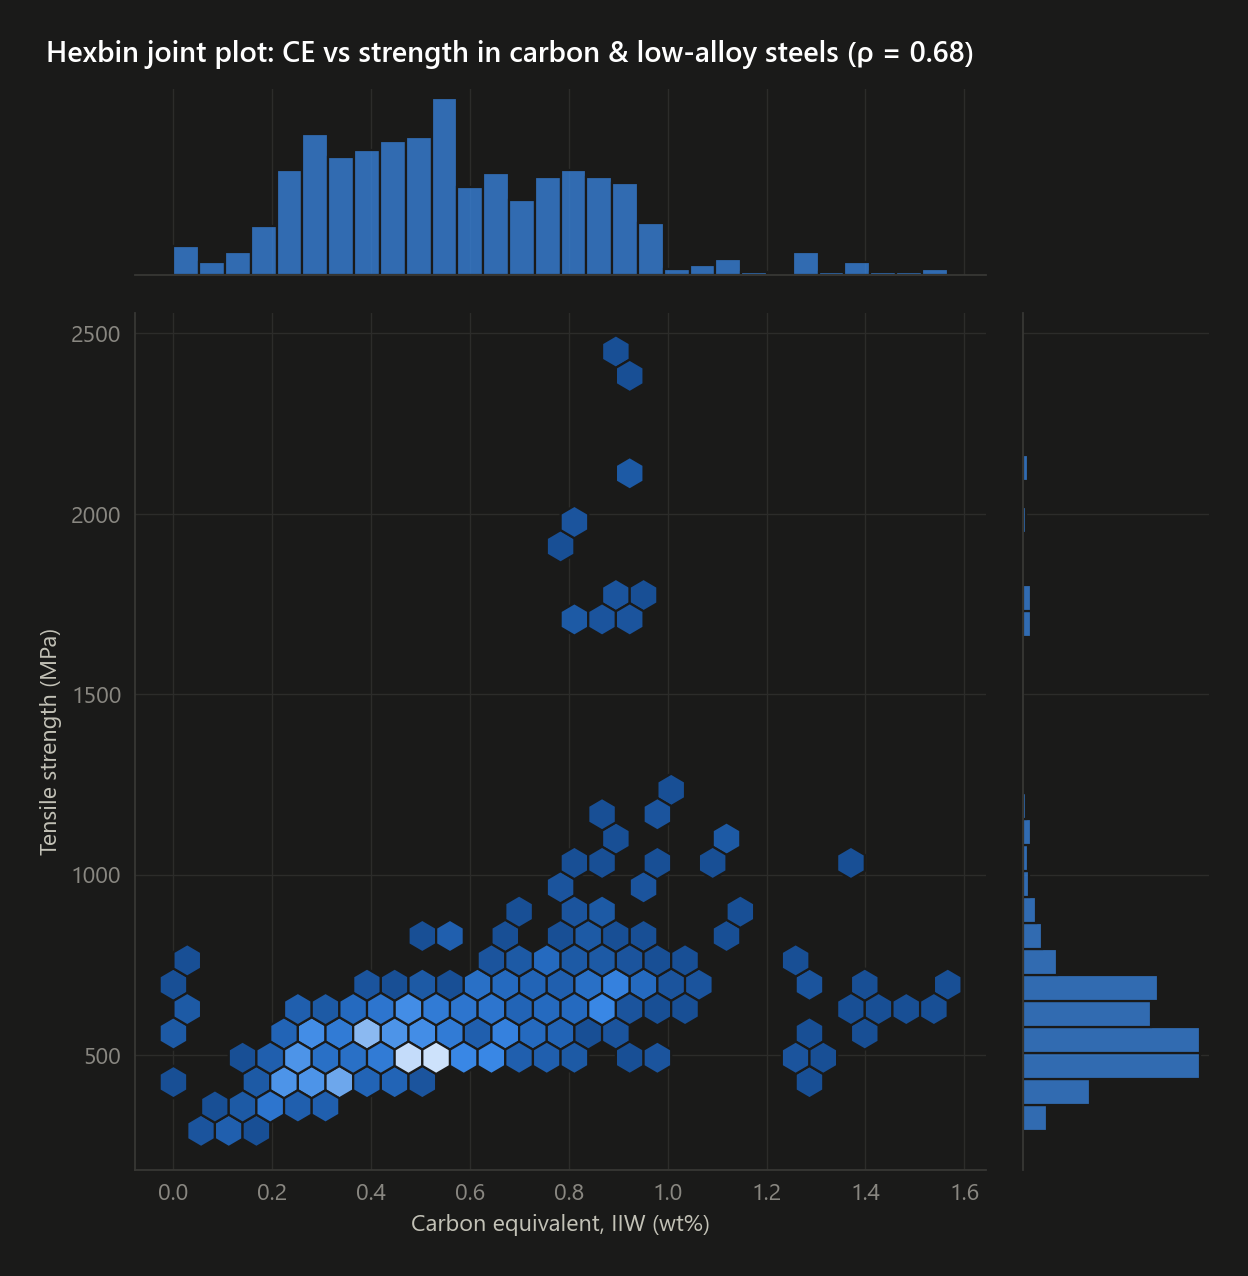

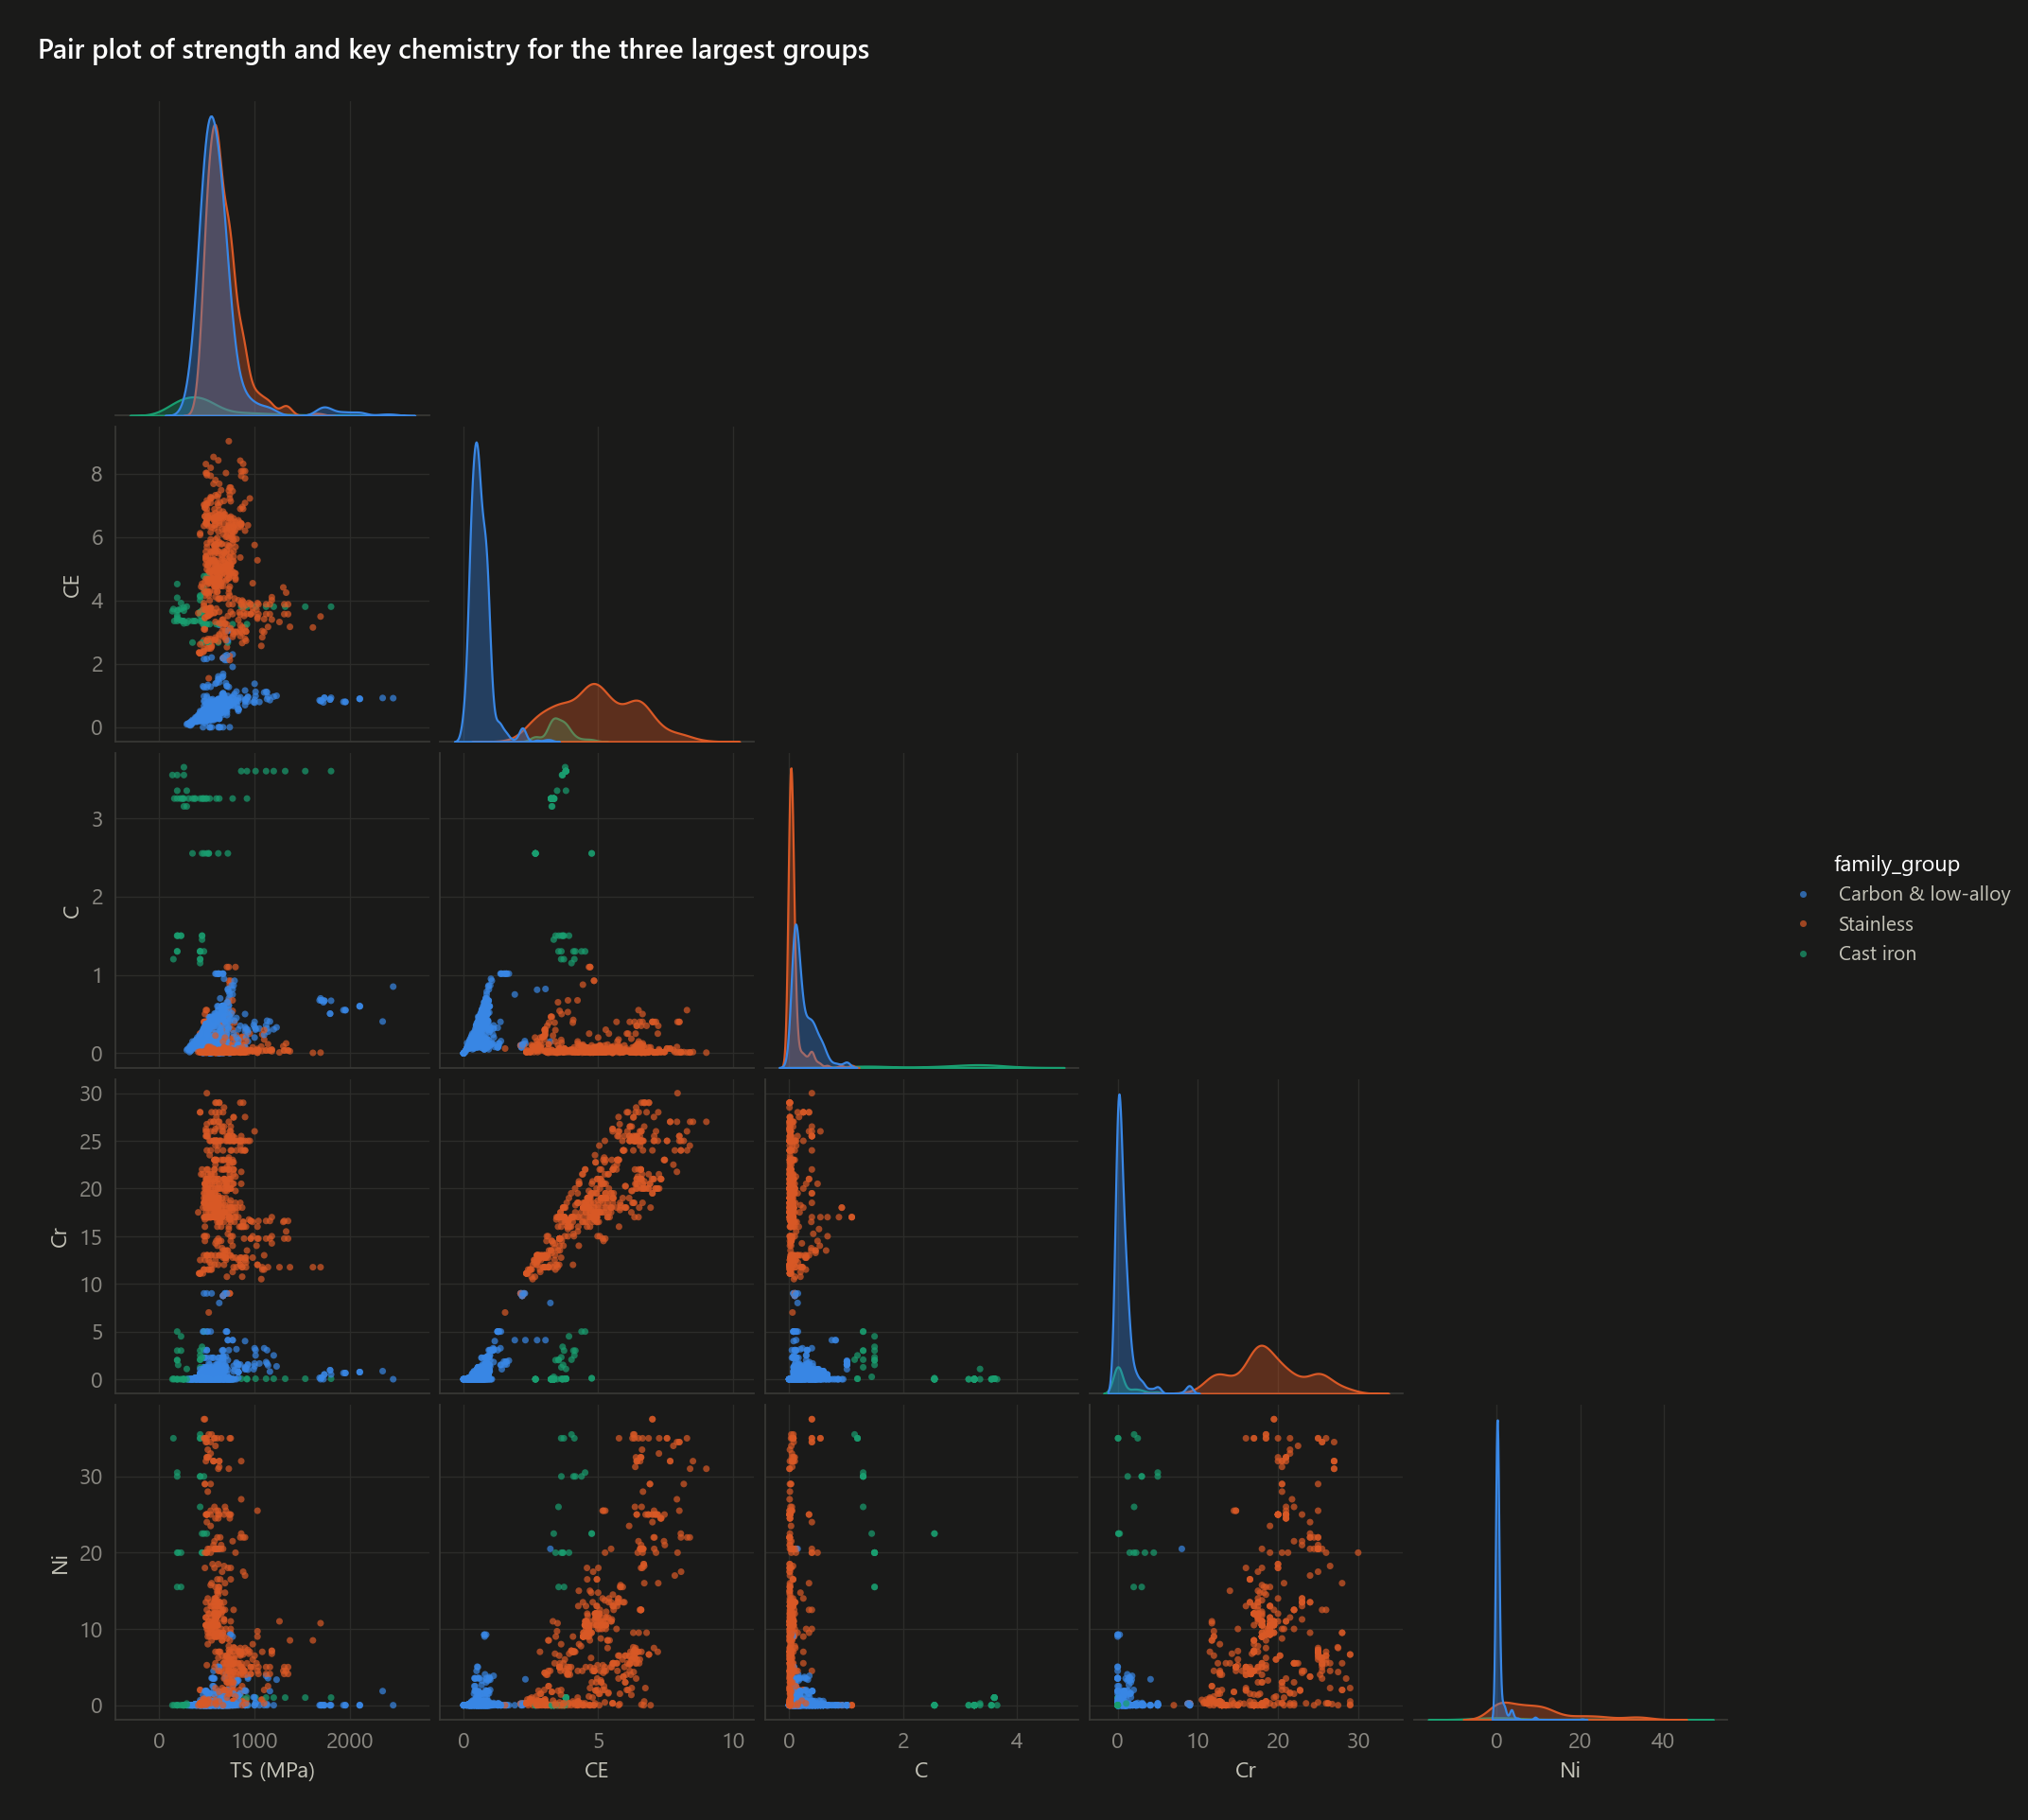

In [8]:
print("Multiple OLS, carbon & low-alloy steels (MPa per wt%):"); display(reg["multi"].table().round(2))
print(f"R2 = {reg['multi'].r2:.3f}, adj R2 = {reg['multi'].adj_r2:.3f}, F = {reg['multi'].f_stat:.1f}, n = {reg['multi'].n}")
show(VS.multiple_regression(reg), "04_12_multiple_regression")
show(VS.joint_hex(g), "04_13_hexbin_ce_strength")
show(VS.pairplot(g), "04_14_pairplot")

**Takeaway.** In plain carbon steels a straight line in carbon alone explains about half of the strength variance,
with a tight confidence band but a wide prediction band: one grade can sit far from the line. Adding Mn, Si, Cr,
Ni, Mo and V across all carbon & low-alloy steels gives significant positive effects for C, Si, V, Ni and Cr (Mo is
borderline negative, Mn not significant), yet the R² stays modest. The diagnostics (fan-shaped residuals, heavy-tailed Q-Q) show why the project's main model is
gradient boosting rather than linear regression.

## 5 · Principal component analysis

,component,explained_variance_ratio,cumulative,eigenvalue
0,PC1,0.150,0.150,3.009
1,PC2,0.118,0.268,2.354
2,PC3,0.095,0.363,1.902
3,PC4,0.076,0.439,1.527
4,PC5,0.059,0.499,1.189
5,PC6,0.052,0.551,1.049
6,PC7,0.052,0.603,1.031
7,PC8,0.050,0.653,1.005


components to reach 80 %: 12 | Kaiser (eigenvalue > 1): 8


,PC1,PC2,PC3
C,-0.580,0.140,0.630
P,-0.260,-0.150,0.660
S,-0.250,-0.150,0.320
V,-0.140,0.800,0.170
O,-0.130,-0.060,-0.110
W,-0.060,0.780,0.170
Zr,-0.030,0.050,-0.220
B,0.050,0.100,-0.120
Al,0.050,0.050,-0.190
Co,0.060,0.710,0.000


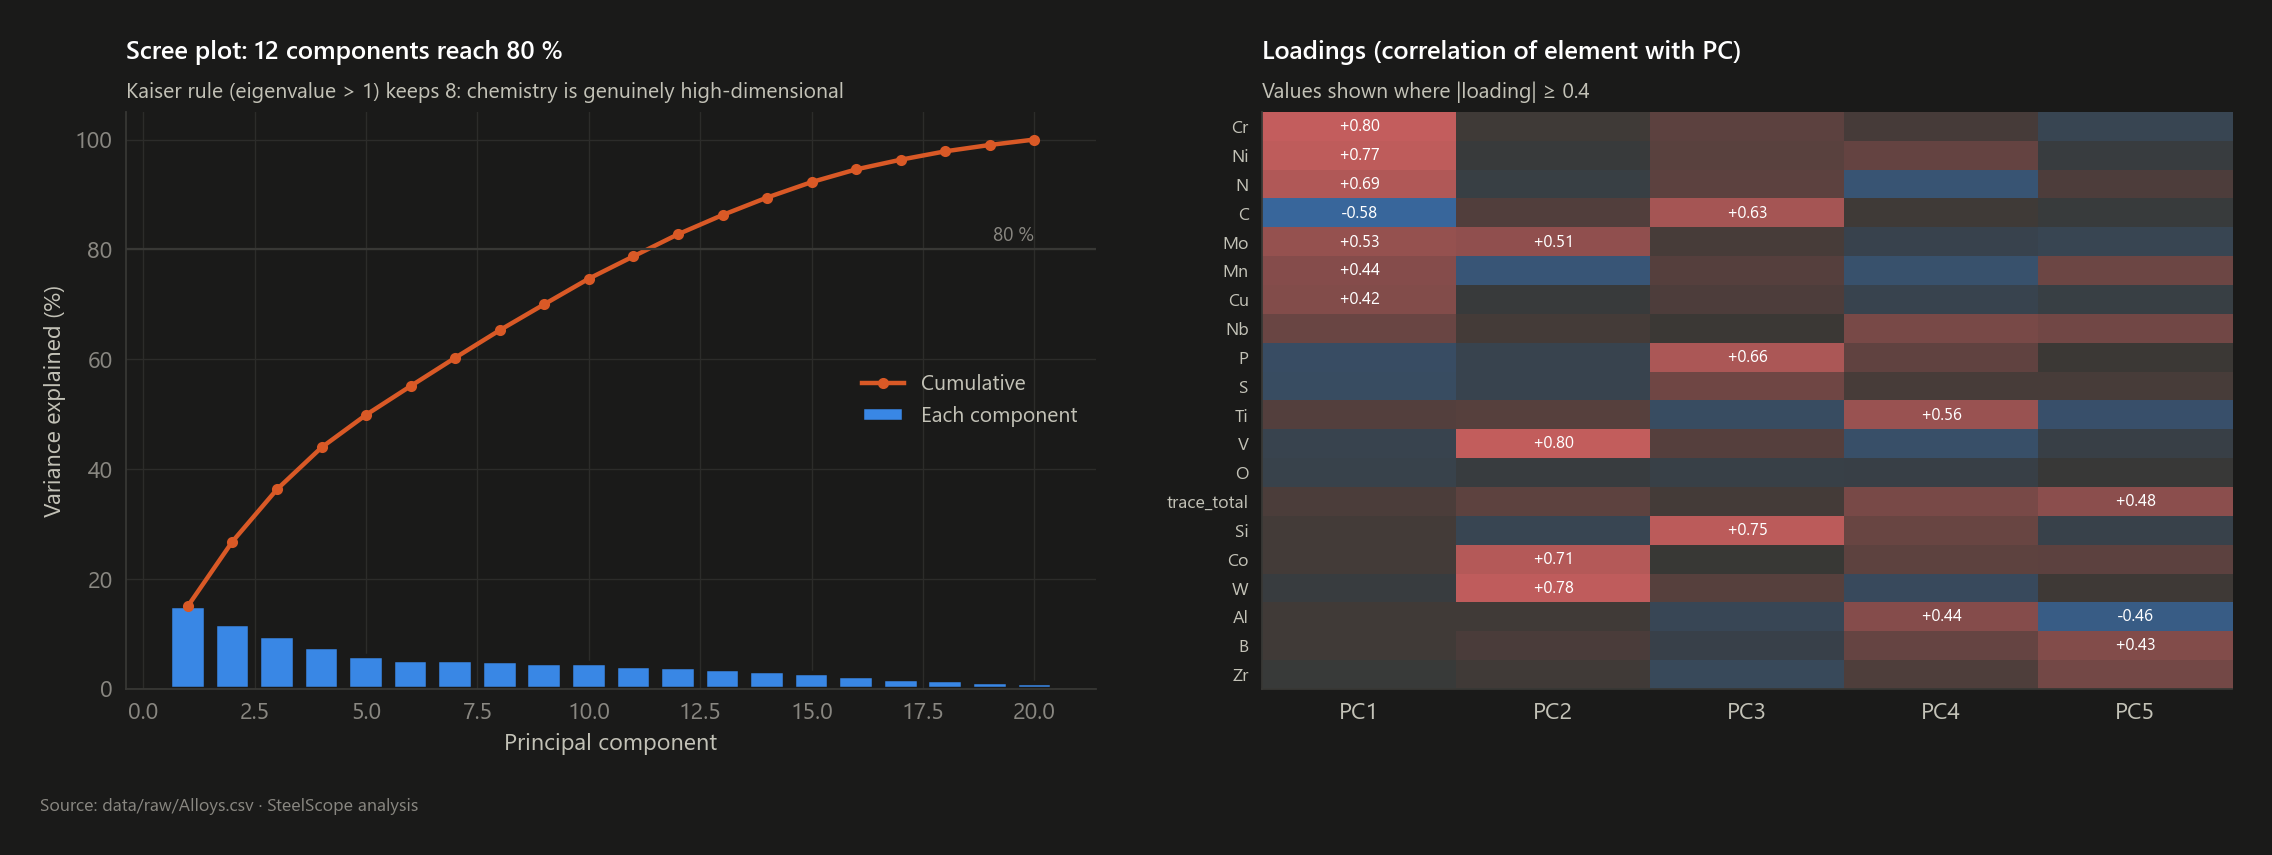

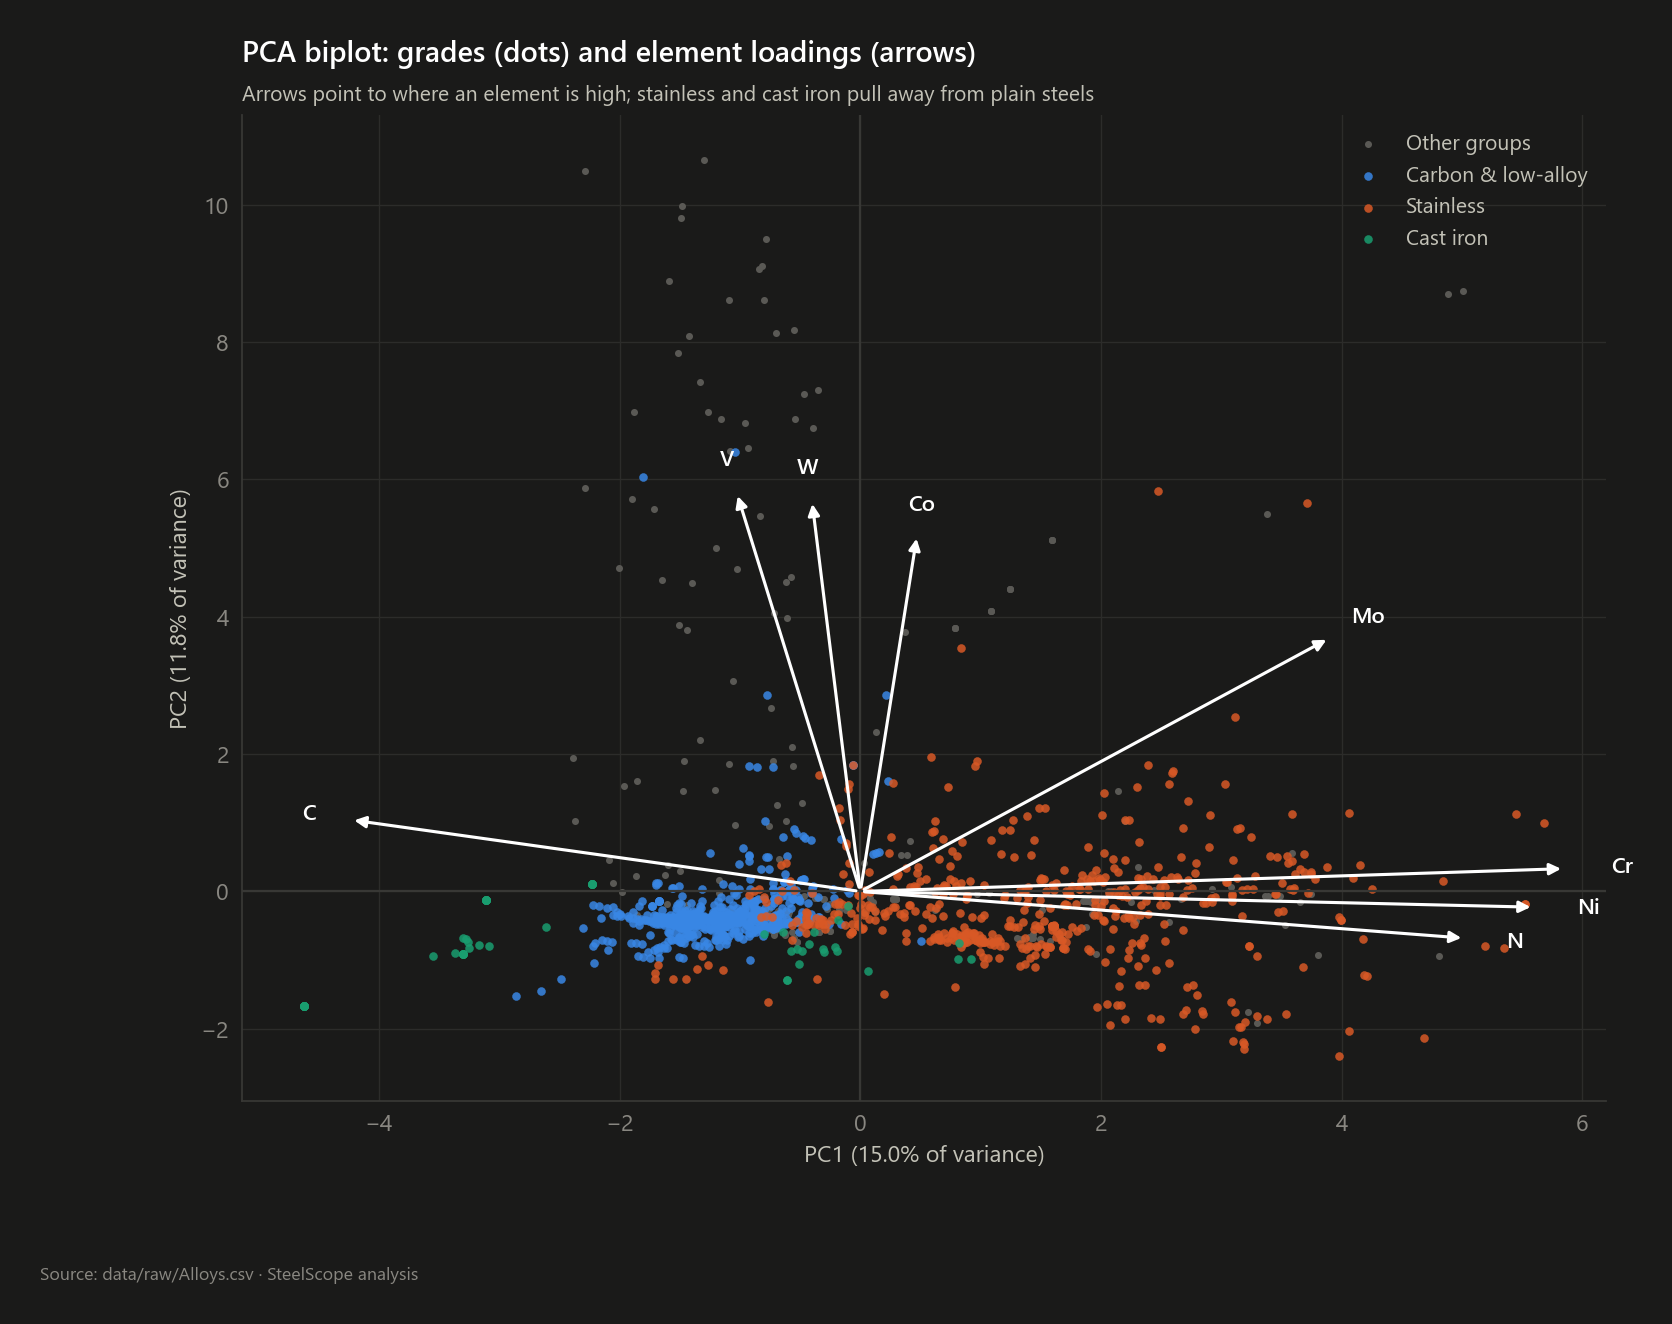

In [9]:
X, feats = V.composition_space(grades, rare)
pca = V.pca_analysis(X, feats)
display(pca["explained"].head(8).round(3))
print("components to reach 80 %:", pca["n_for_80pct"], "| Kaiser (eigenvalue > 1):", pca["n_kaiser"])
display(pca["loadings"].iloc[:, :3].round(2).sort_values("PC1"))
show(VS.pca_scree(pca), "04_15_pca_scree_loadings")
show(VS.pca_biplot(g, pca), "04_16_pca_biplot")

**Takeaway.** No single direction dominates: the first two components carry only about a quarter of the variance,
and many components are needed for 80 %. Steel chemistry is genuinely multi-dimensional. The biplot still
separates the big three: stainless grades pull along the Cr/Ni/N arrows, cast irons along C/Si/P, and plain steels
sit near the origin.

## 6 · K-means clustering

,inertia,silhouette
k,,
2,"24,549.566",0.231
3,"22,084.606",0.247
4,"20,334.023",0.269
5,"19,041.752",0.271
6,"17,758.751",0.277
7,"16,517.379",0.286
8,"15,268.567",0.317
9,"13,961.895",0.331
10,"13,295.641",0.336


k used for the visuals: 8
{0: 'K1 · Stainless steel (92%)', 1: 'K2 · Alloy steel (40%)', 2: 'K3 · Bearing steel (100%)', 3: 'K4 · Stainless steel (75%)', 4: 'K5 · Grey cast iron (25%)', 5: 'K6 · Stainless steel (88%)', 6: 'K7 · High-speed steel (65%)', 7: 'K8 · Alloy steel (44%)'}


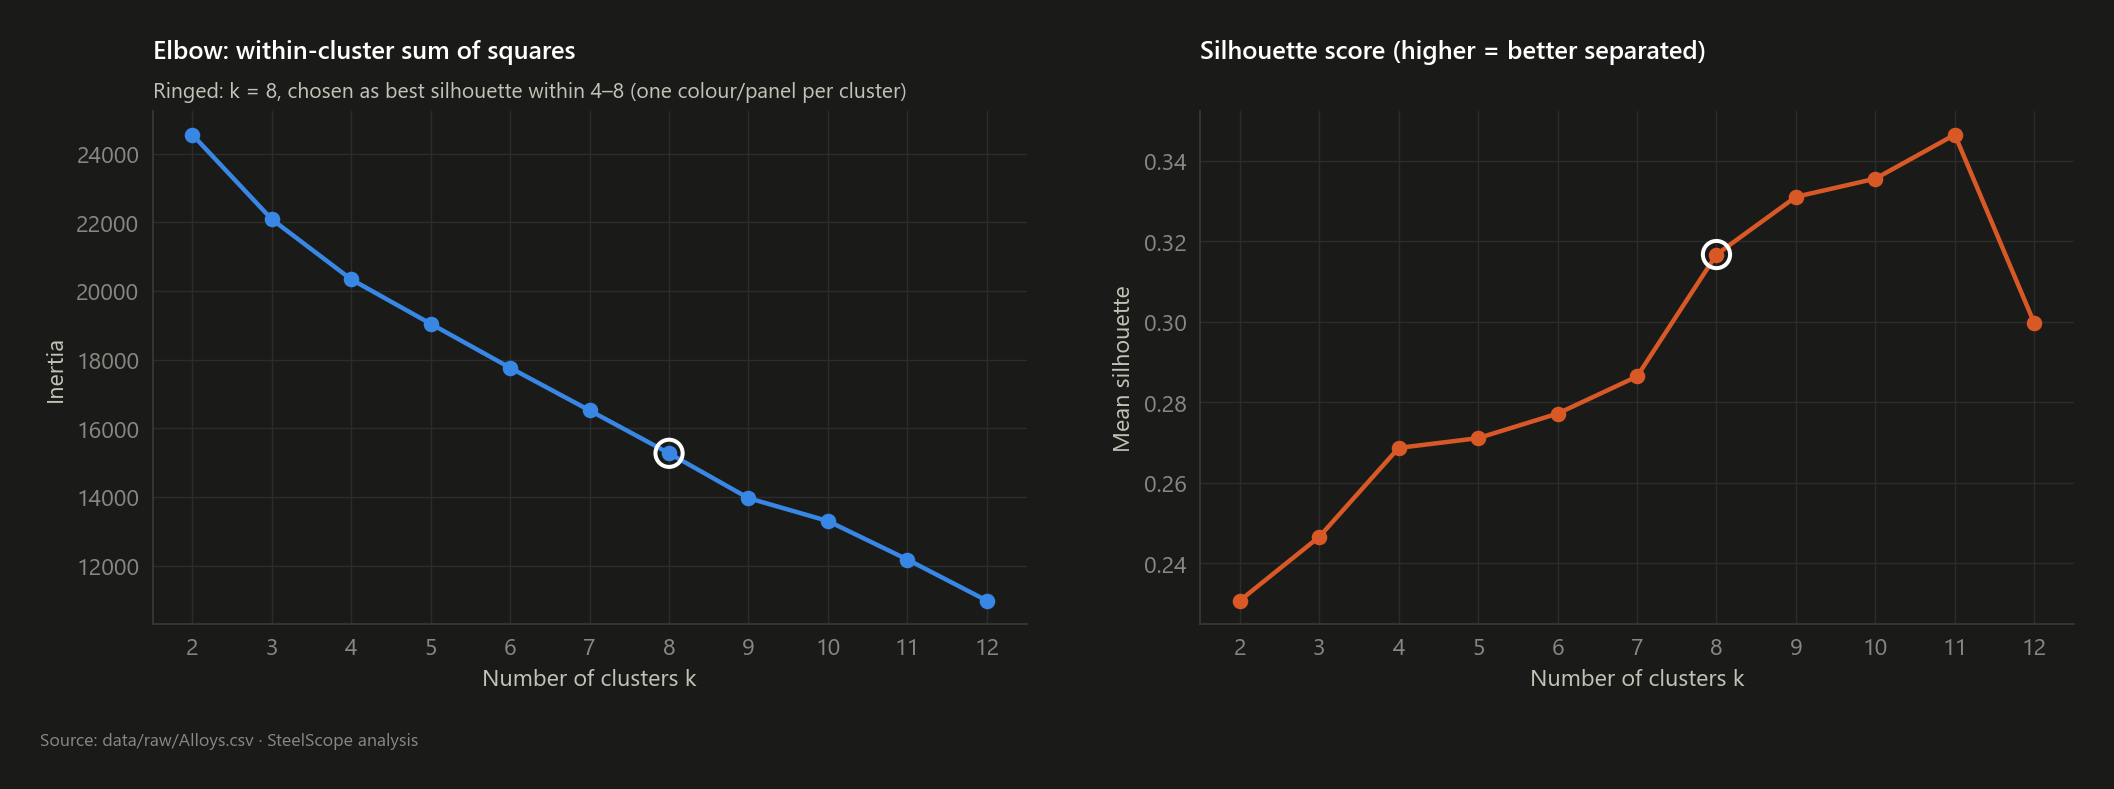

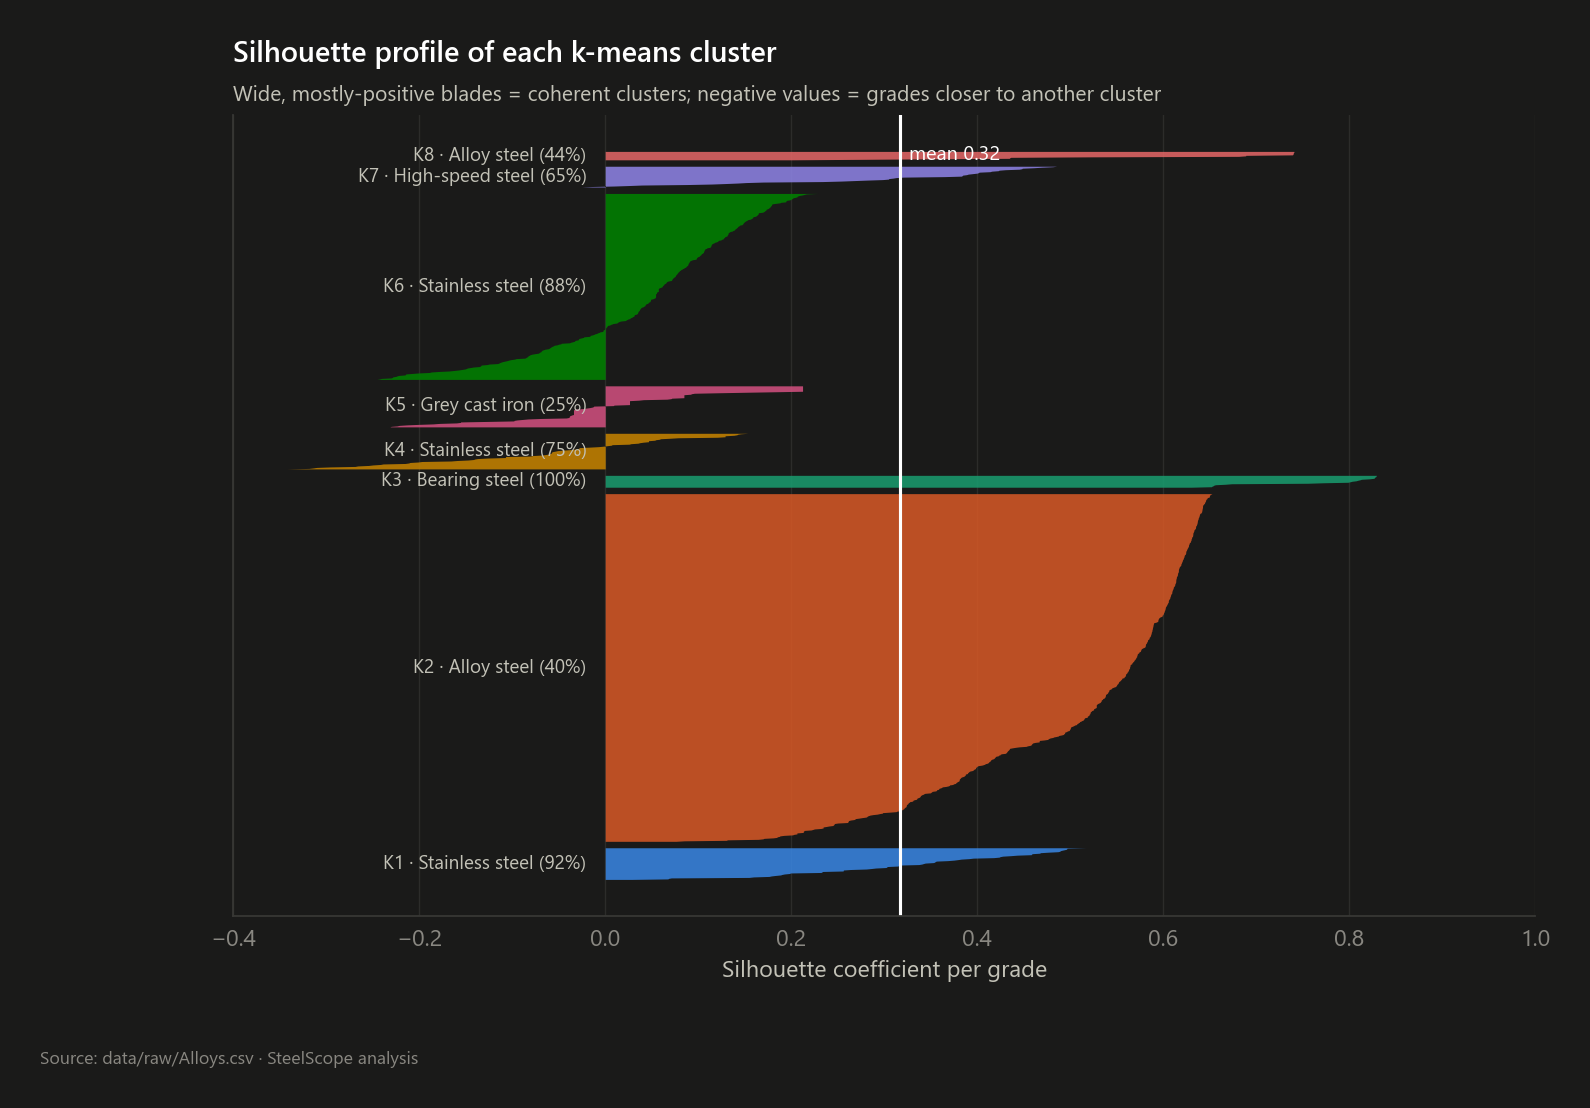

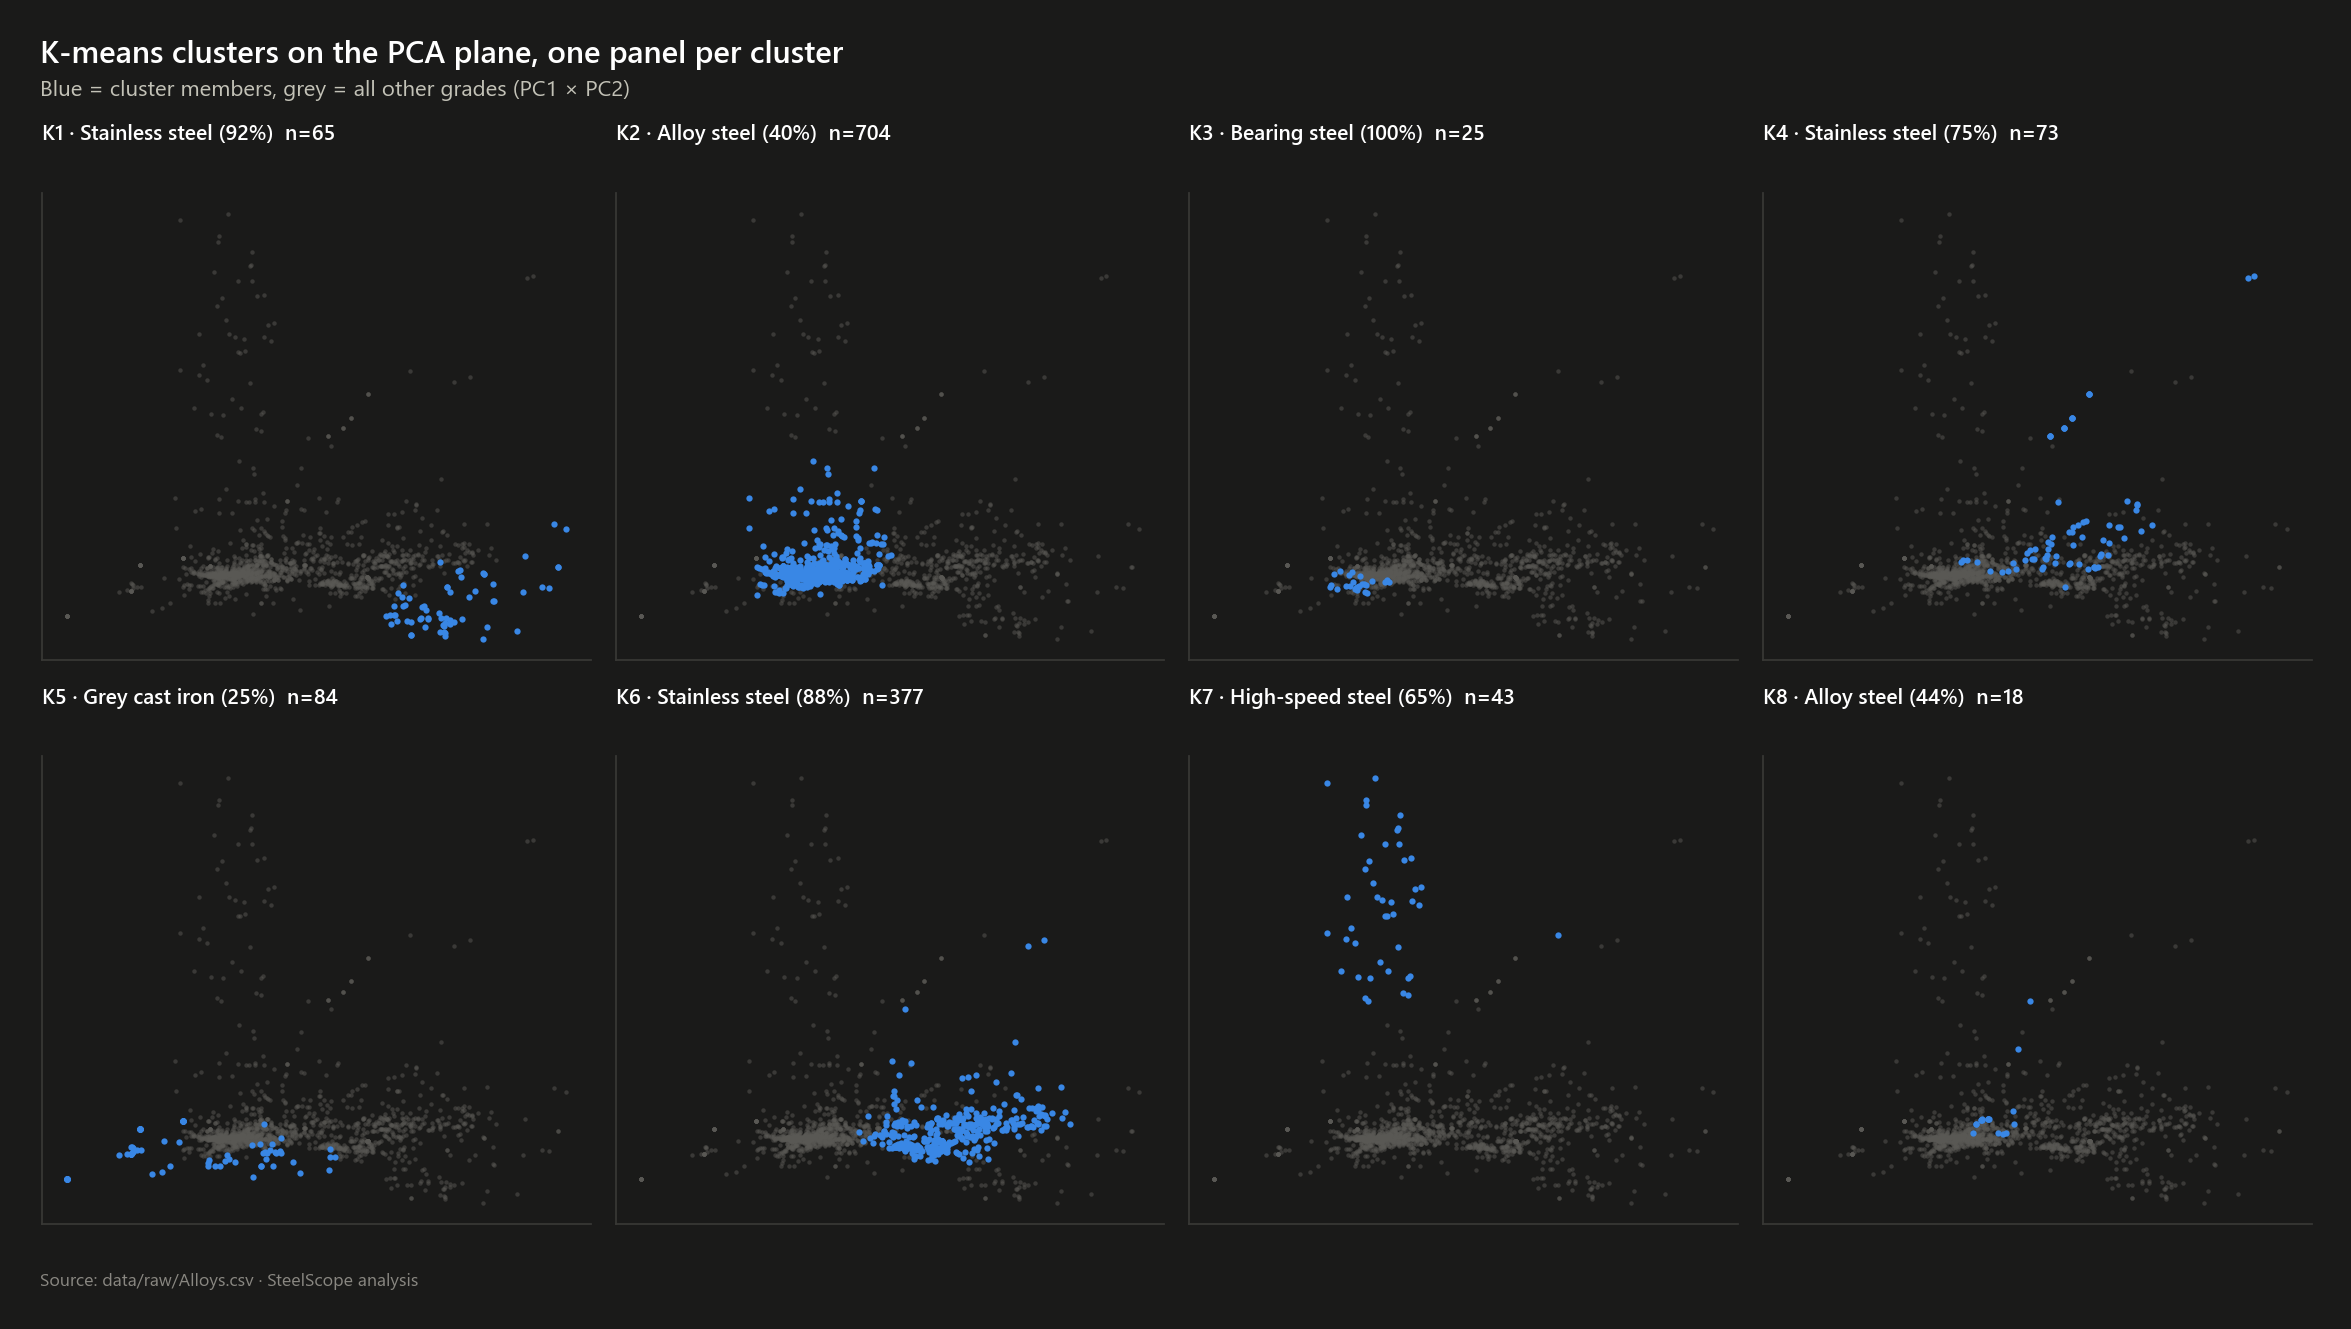

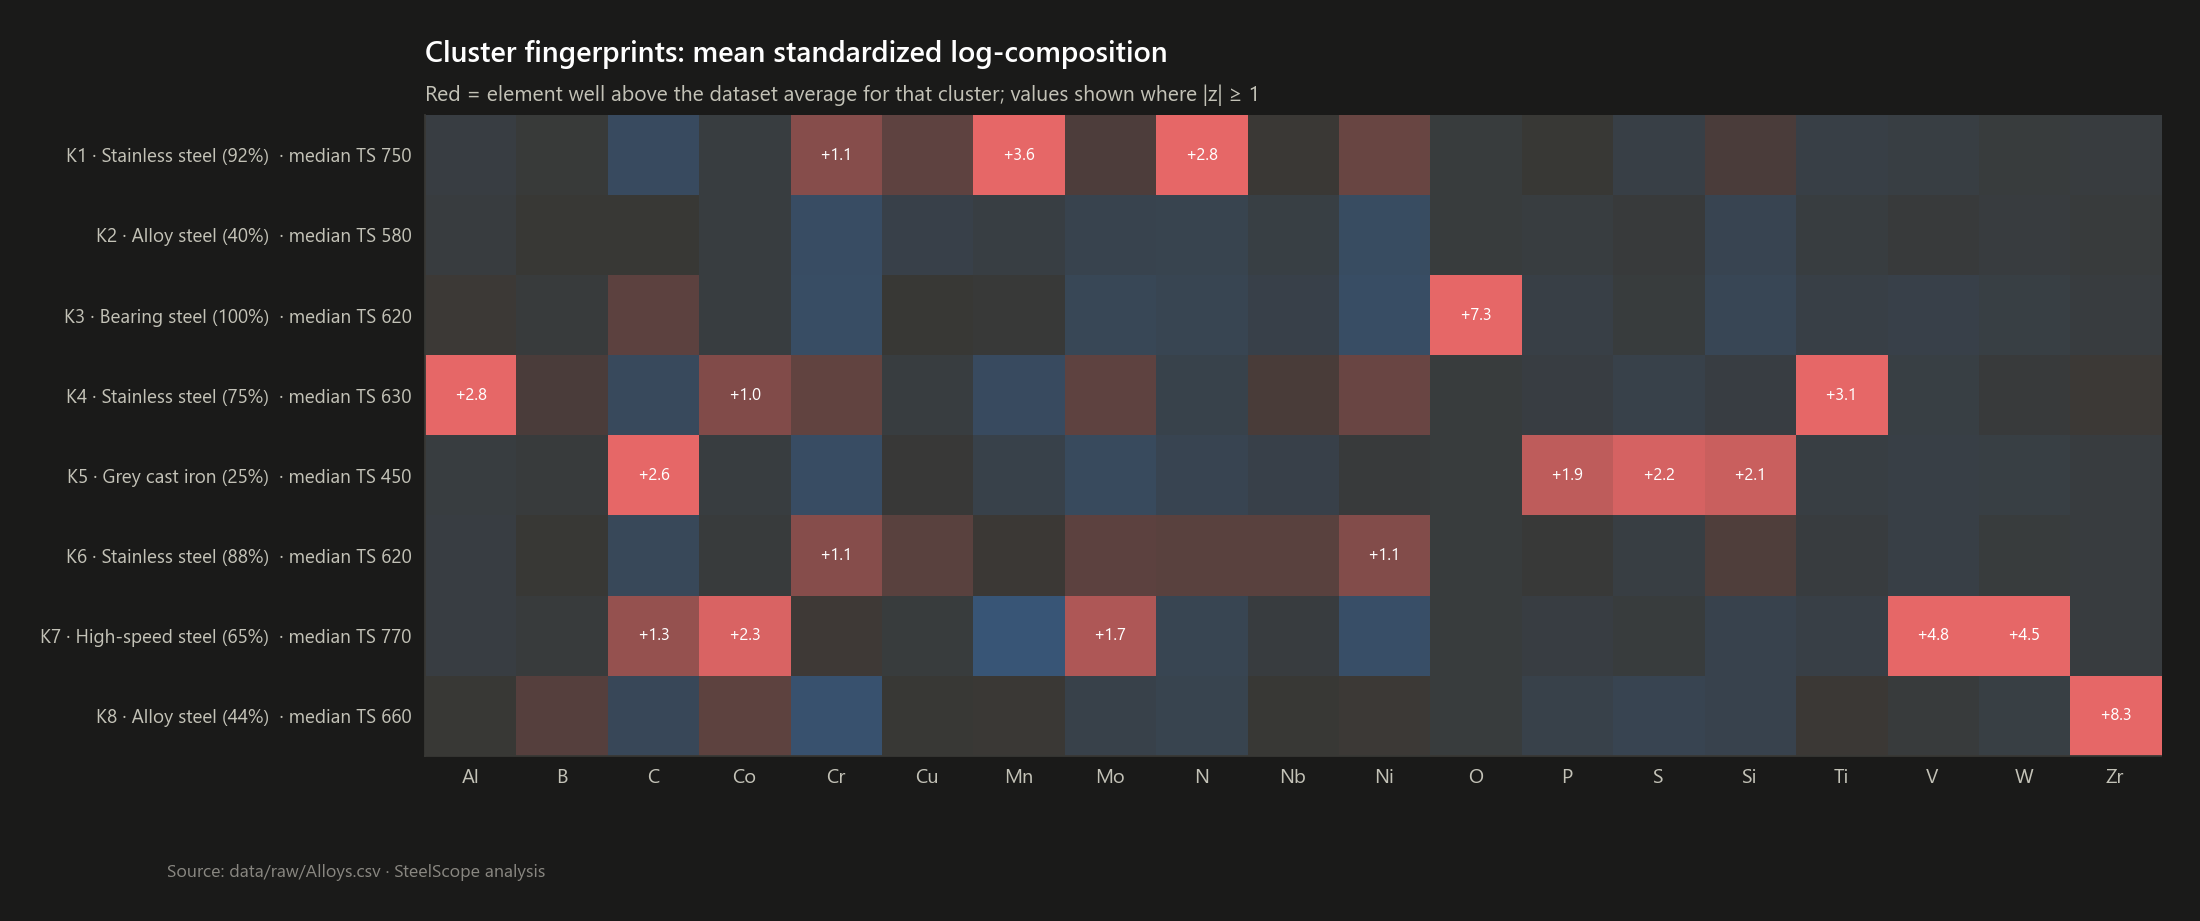

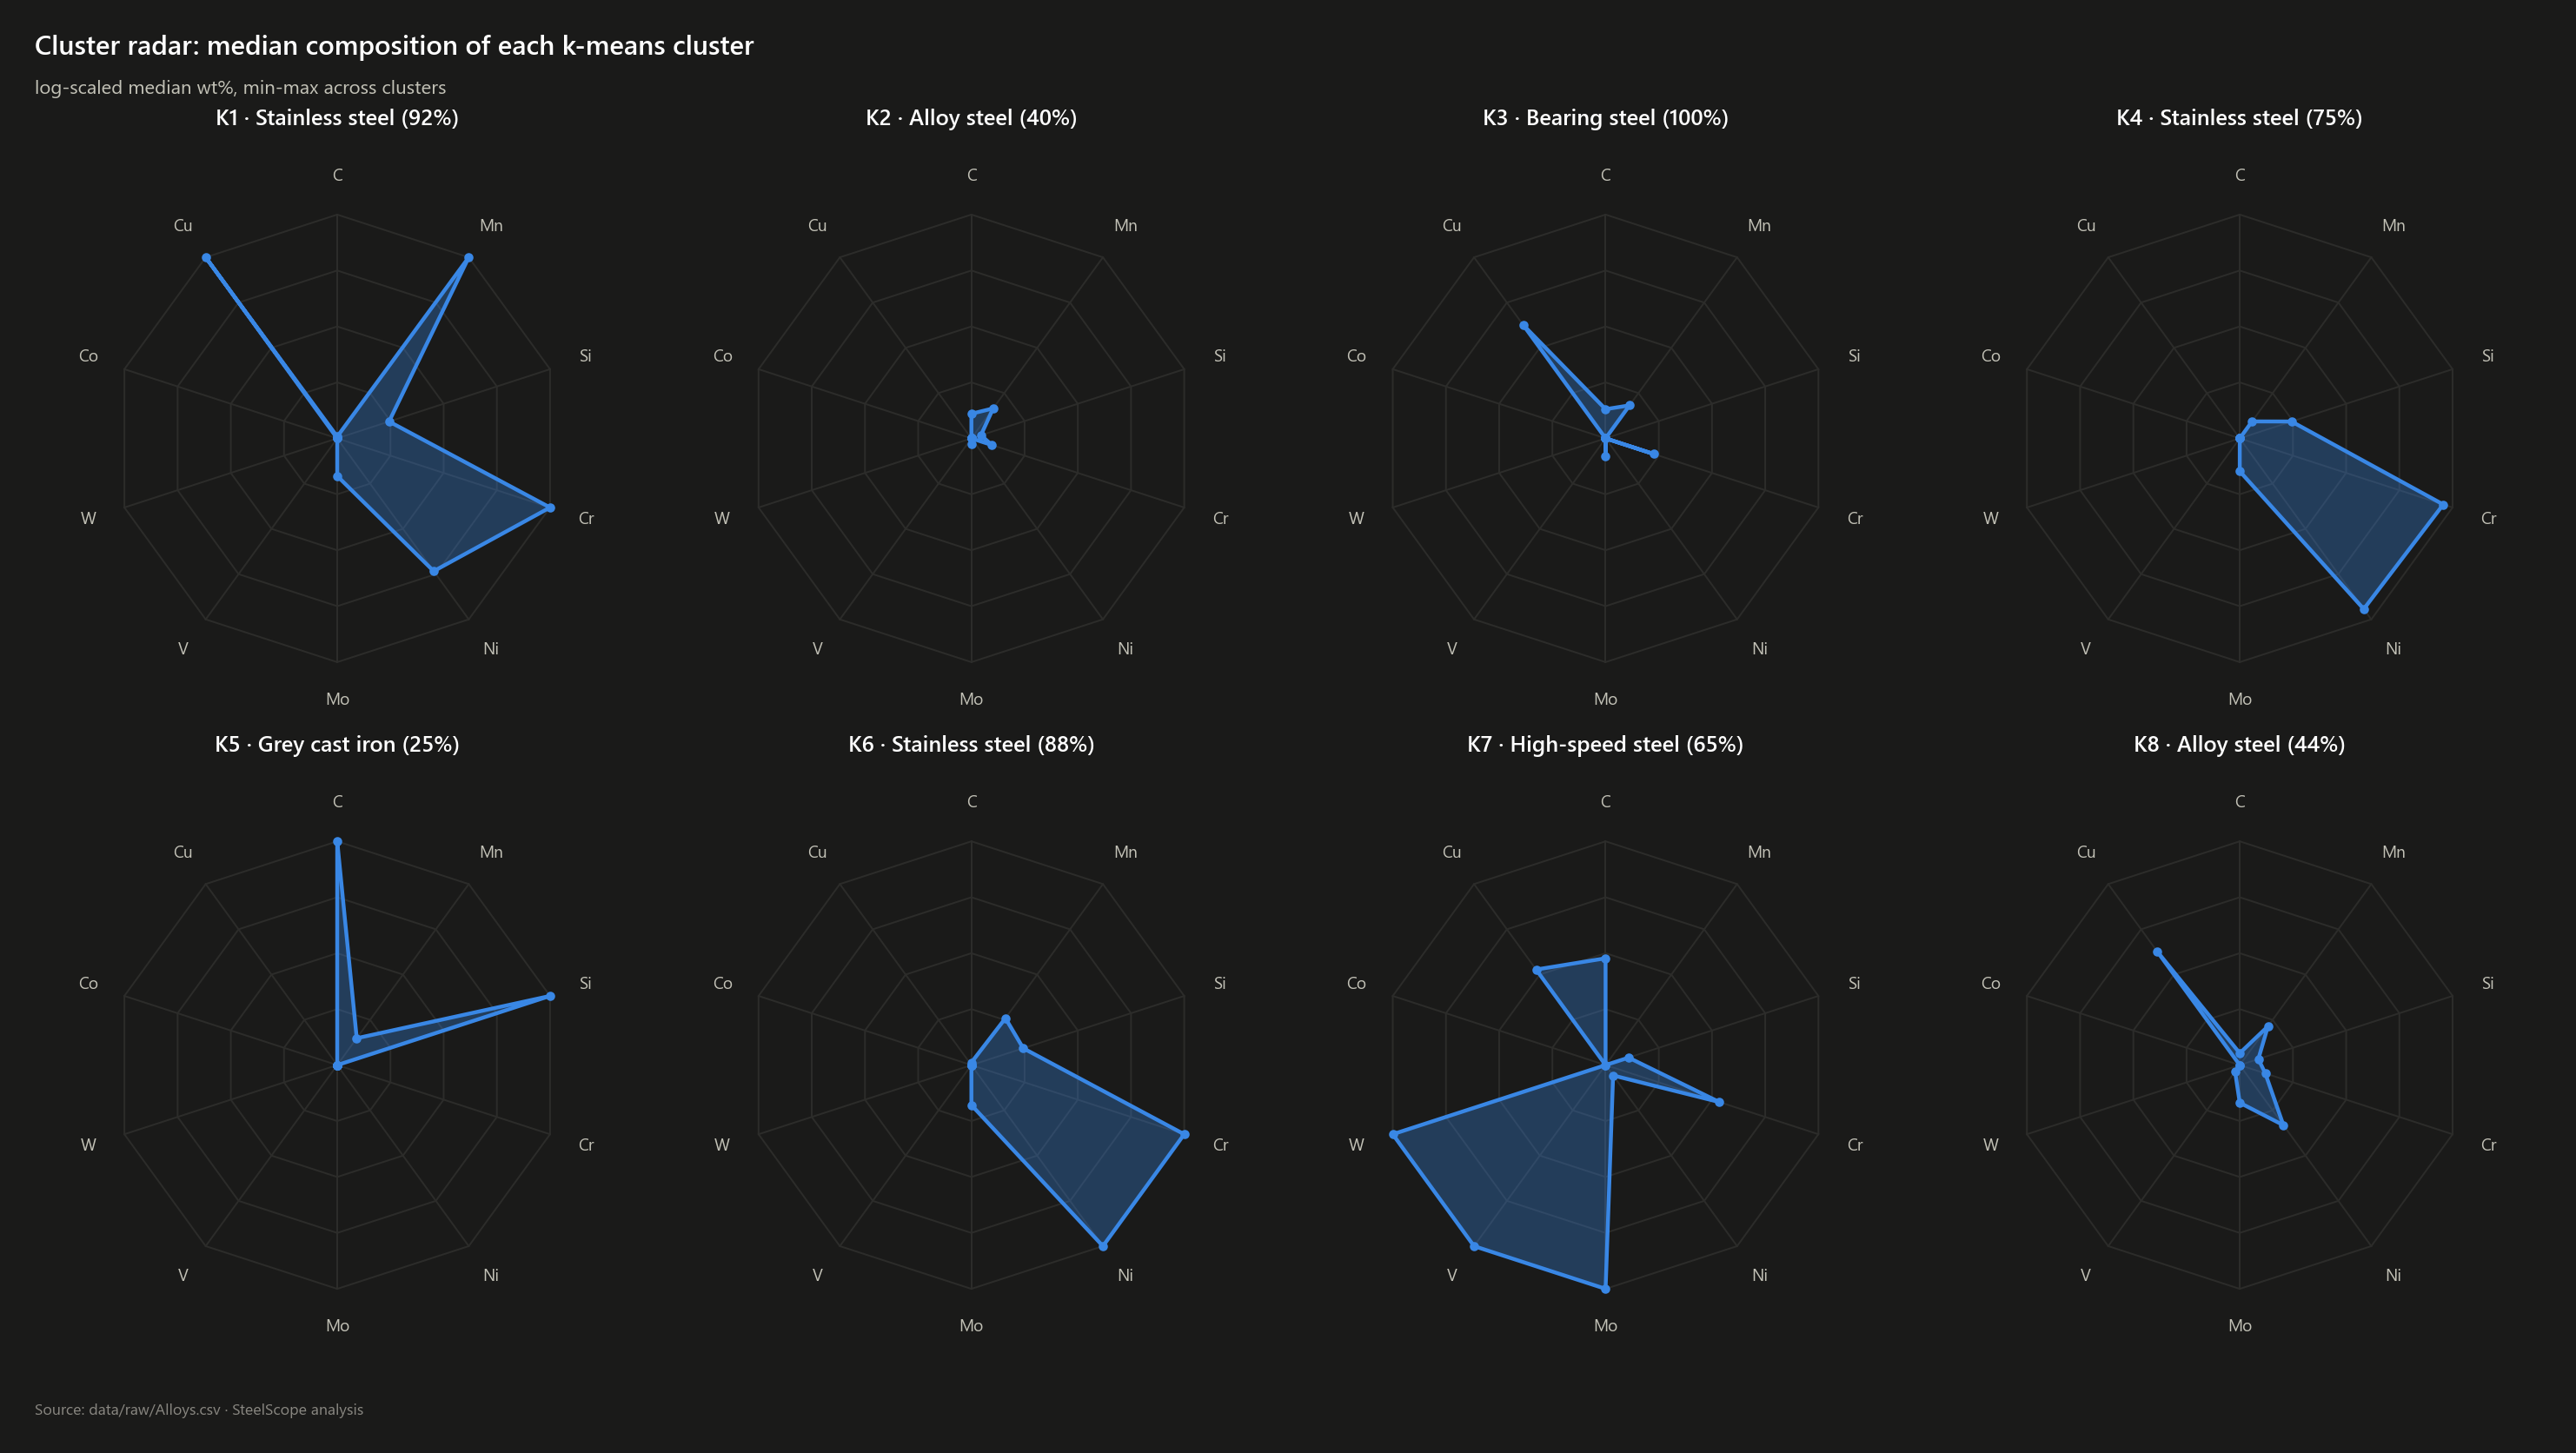

In [10]:
scan = V.kmeans_scan(X)
k, labels = V.kmeans_visual(X, scan)
names = V.cluster_names(grades, labels)
display(scan.round(3)); print("k used for the visuals:", k); print(names)
show(VS.kmeans_elbow(scan, k), "04_17_kmeans_elbow_silhouette")
show(VS.silhouette_plot(X, labels, names), "04_18_kmeans_silhouette_blades")
show(VS.kmeans_small_multiples(pca["scores"], labels, names), "04_19_kmeans_pca_panels")
show(VS.cluster_heatmap(g, labels, names, X, feats), "04_20_cluster_fingerprints")
radar_c = V.radar_cluster_composition(grades, labels, names)
show(VS.radar_small_multiples(radar_c, P.BLUE, "Cluster radar: median composition of each k-means cluster",
                              "log-scaled median wt%, min-max across clusters", cols=4), "04_21_cluster_radar")

**Takeaway.** The elbow has no sharp knee and the silhouette keeps creeping up with k, which is typical of a
continuum with dense islands. For visual profiling we use the best silhouette within 4–8 clusters, so each
cluster gets its own panel. The fingerprints read like a metallurgy textbook: an austenitic Cr-Ni block, a
nitrogen/manganese block, a high-speed block (W, V, Co, Mo), a cast-iron block (C, Si, P) and a large lean block
where most plain steels sit regardless of their family name.

## 7 · Circular migration (chord) plots

,source,target,value
0,Raw class 0,Dropped: exact duplicate,24
1,Raw class 0,Grade class 0,23
2,Raw class 1,Dropped: exact duplicate,19
3,Raw class 1,Grade class 1,648
4,Raw class 1,Merged into twin listing,350
5,Raw class 2,Dropped: exact duplicate,19
6,Raw class 2,Grade class 2,711
7,Raw class 2,Merged into twin listing,871
8,Raw class 2,Unmeasured TS (excluded),7


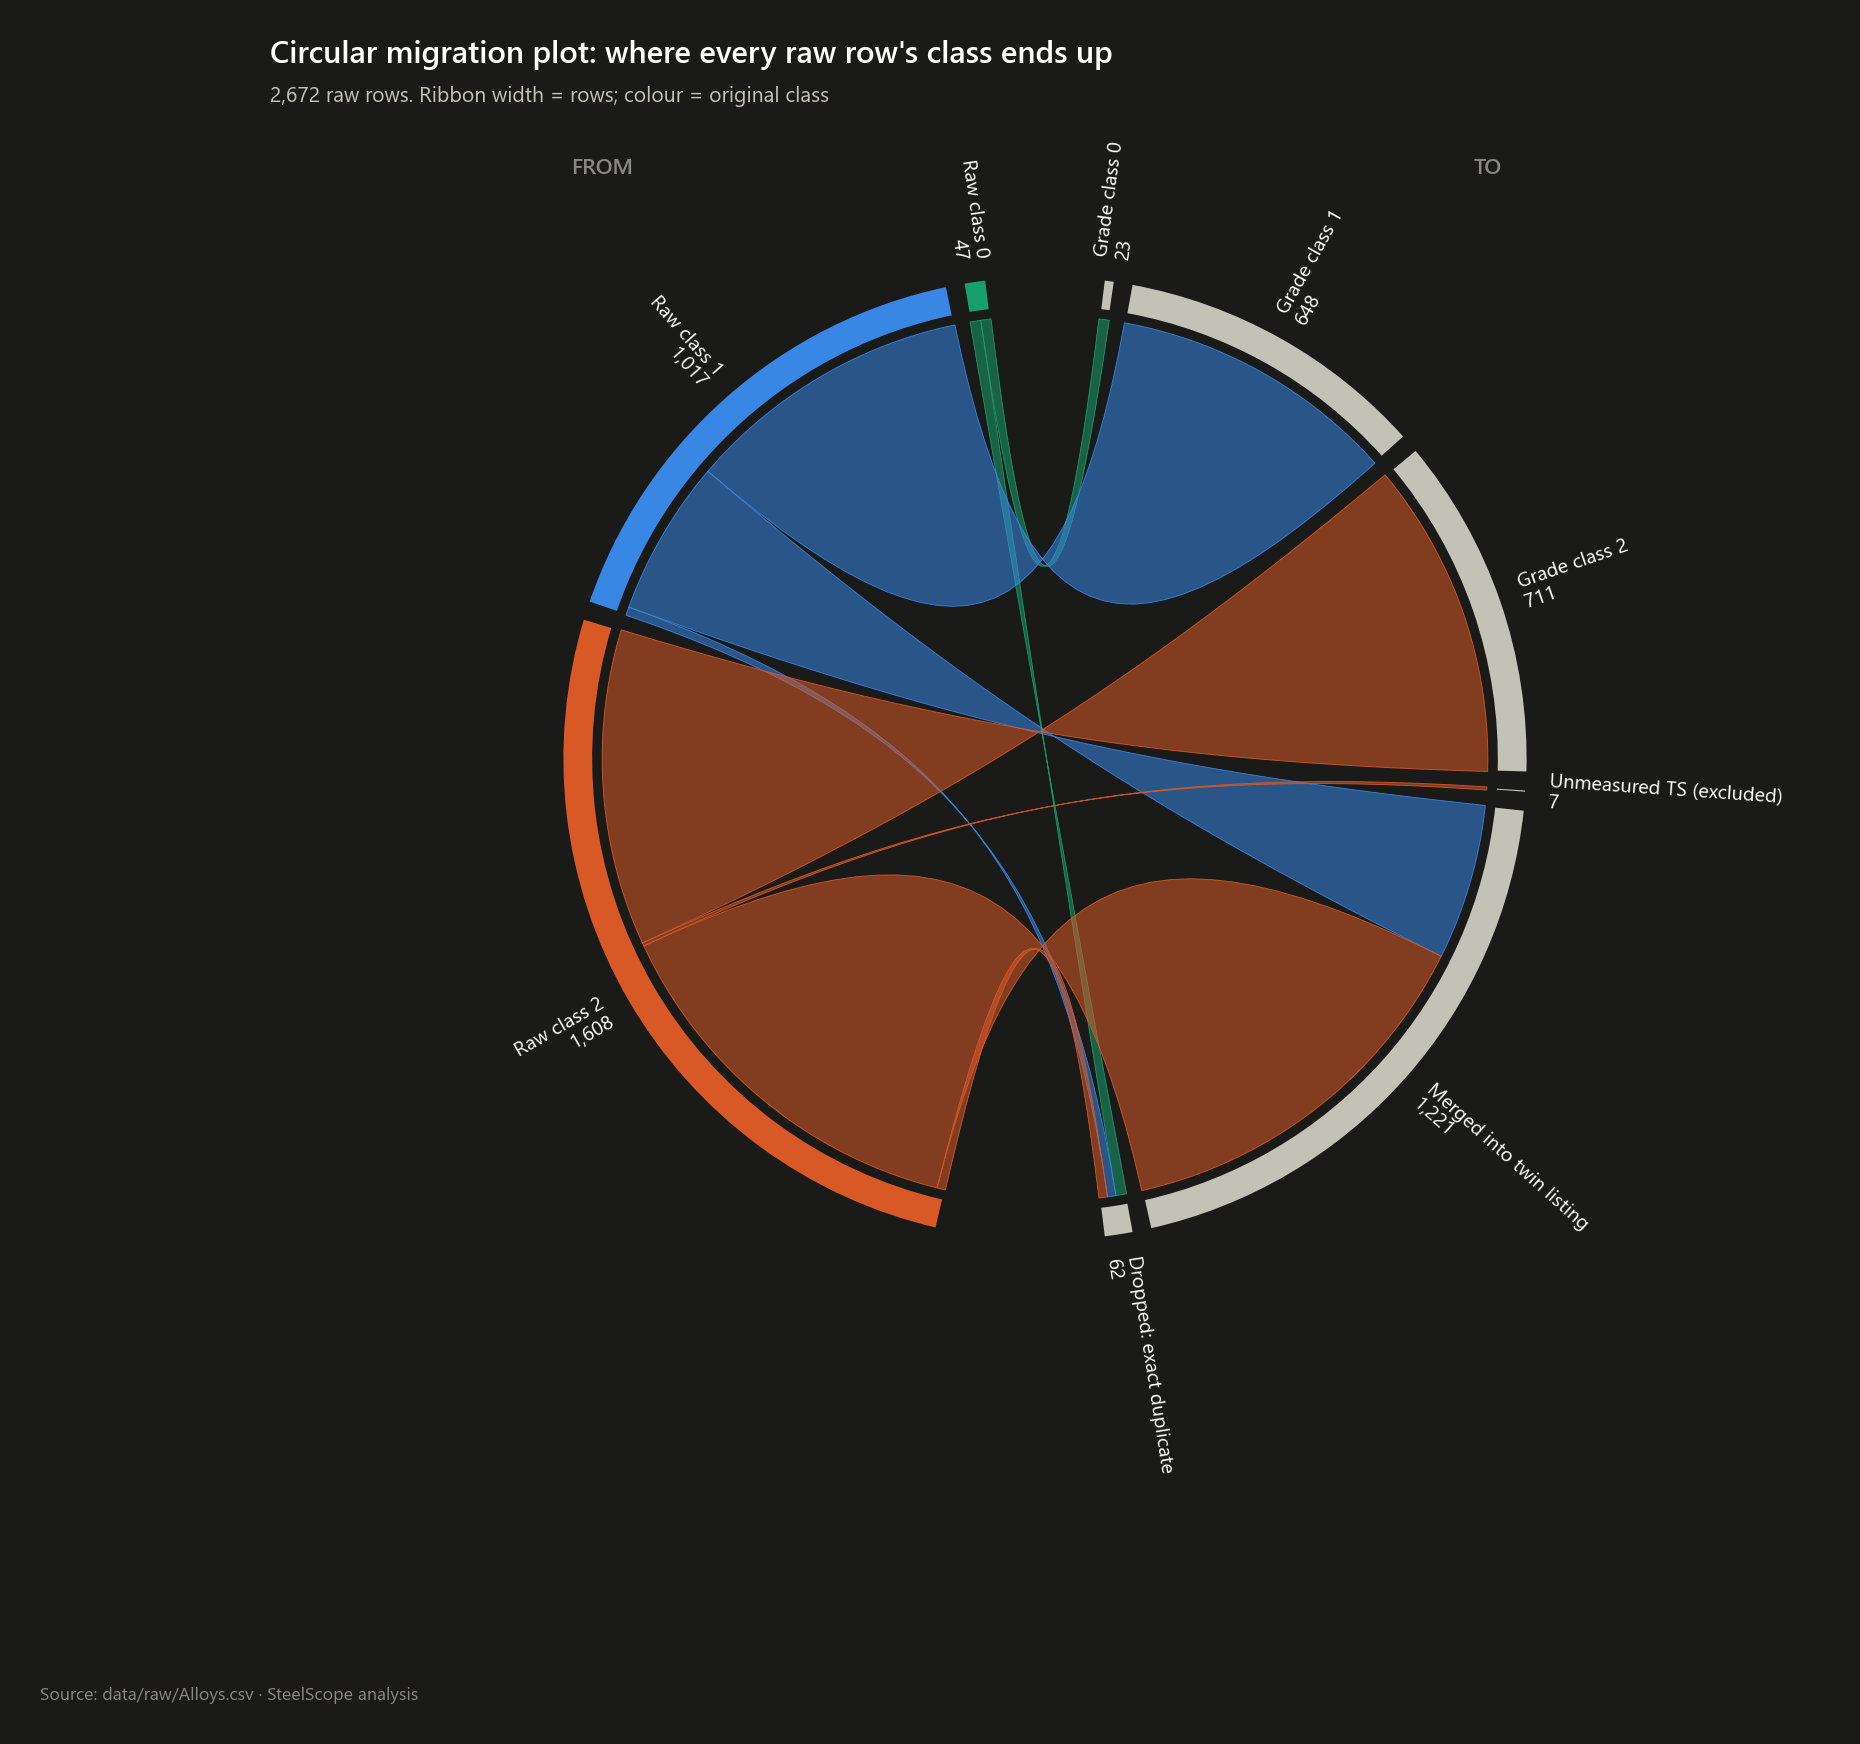

In [11]:
raw = pd.read_csv(DATA_RAW); listings = pd.read_csv(CLEAN_LISTINGS_CSV)
f1 = V.flow_raw_class_to_outcome(raw, listings, grades)
display(f1)
src1 = sorted(f1.source.unique())
tgt1 = ["Grade class 0", "Grade class 1", "Grade class 2", "Unmeasured TS (excluded)", "Merged into twin listing", "Dropped: exact duplicate"]
show(VS.circular_migration(f1, src1, tgt1, dict(zip(src1, [P.AQUA, P.BLUE, P.ORANGE])),
                           "Circular migration plot: where every raw row's class ends up",
                           f"{f1.value.sum():,} raw rows. Ribbon width = rows; colour = original class", min_label_share=0.0),
     "04_22_chord_raw_class_migration")

**Reading it.** Each ribbon carries rows from an original class (left) to their fate after cleaning (right).
Most of raw class 2's mass flows into "Merged into twin listing": those are the hyphenated duplicates, including
almost all of the imputed 652 MPa rows. Only a thin ribbon ends in "Unmeasured". The original classes never jump
to a different cleaned class: recomputing the class from measured strength reproduces it exactly.

target,K1 · Stainless steel (92%),K2 · Alloy steel (40%),K3 · Bearing steel (100%),K4 · Stainless steel (75%),K5 · Grey cast iron (25%),K6 · Stainless steel (88%),K7 · High-speed steel (65%),K8 · Alloy steel (44%)
source,,,,,,,,
Carbon & low-alloy,0,536,25,4,4,1,2,11
Cast iron,0,0,0,0,66,1,0,0
Other,0,9,0,14,0,2,0,3
Stainless,60,84,0,55,14,331,1,1
Tool & high-speed,0,42,0,0,0,0,40,0
Weld metal,5,33,0,0,0,42,0,3


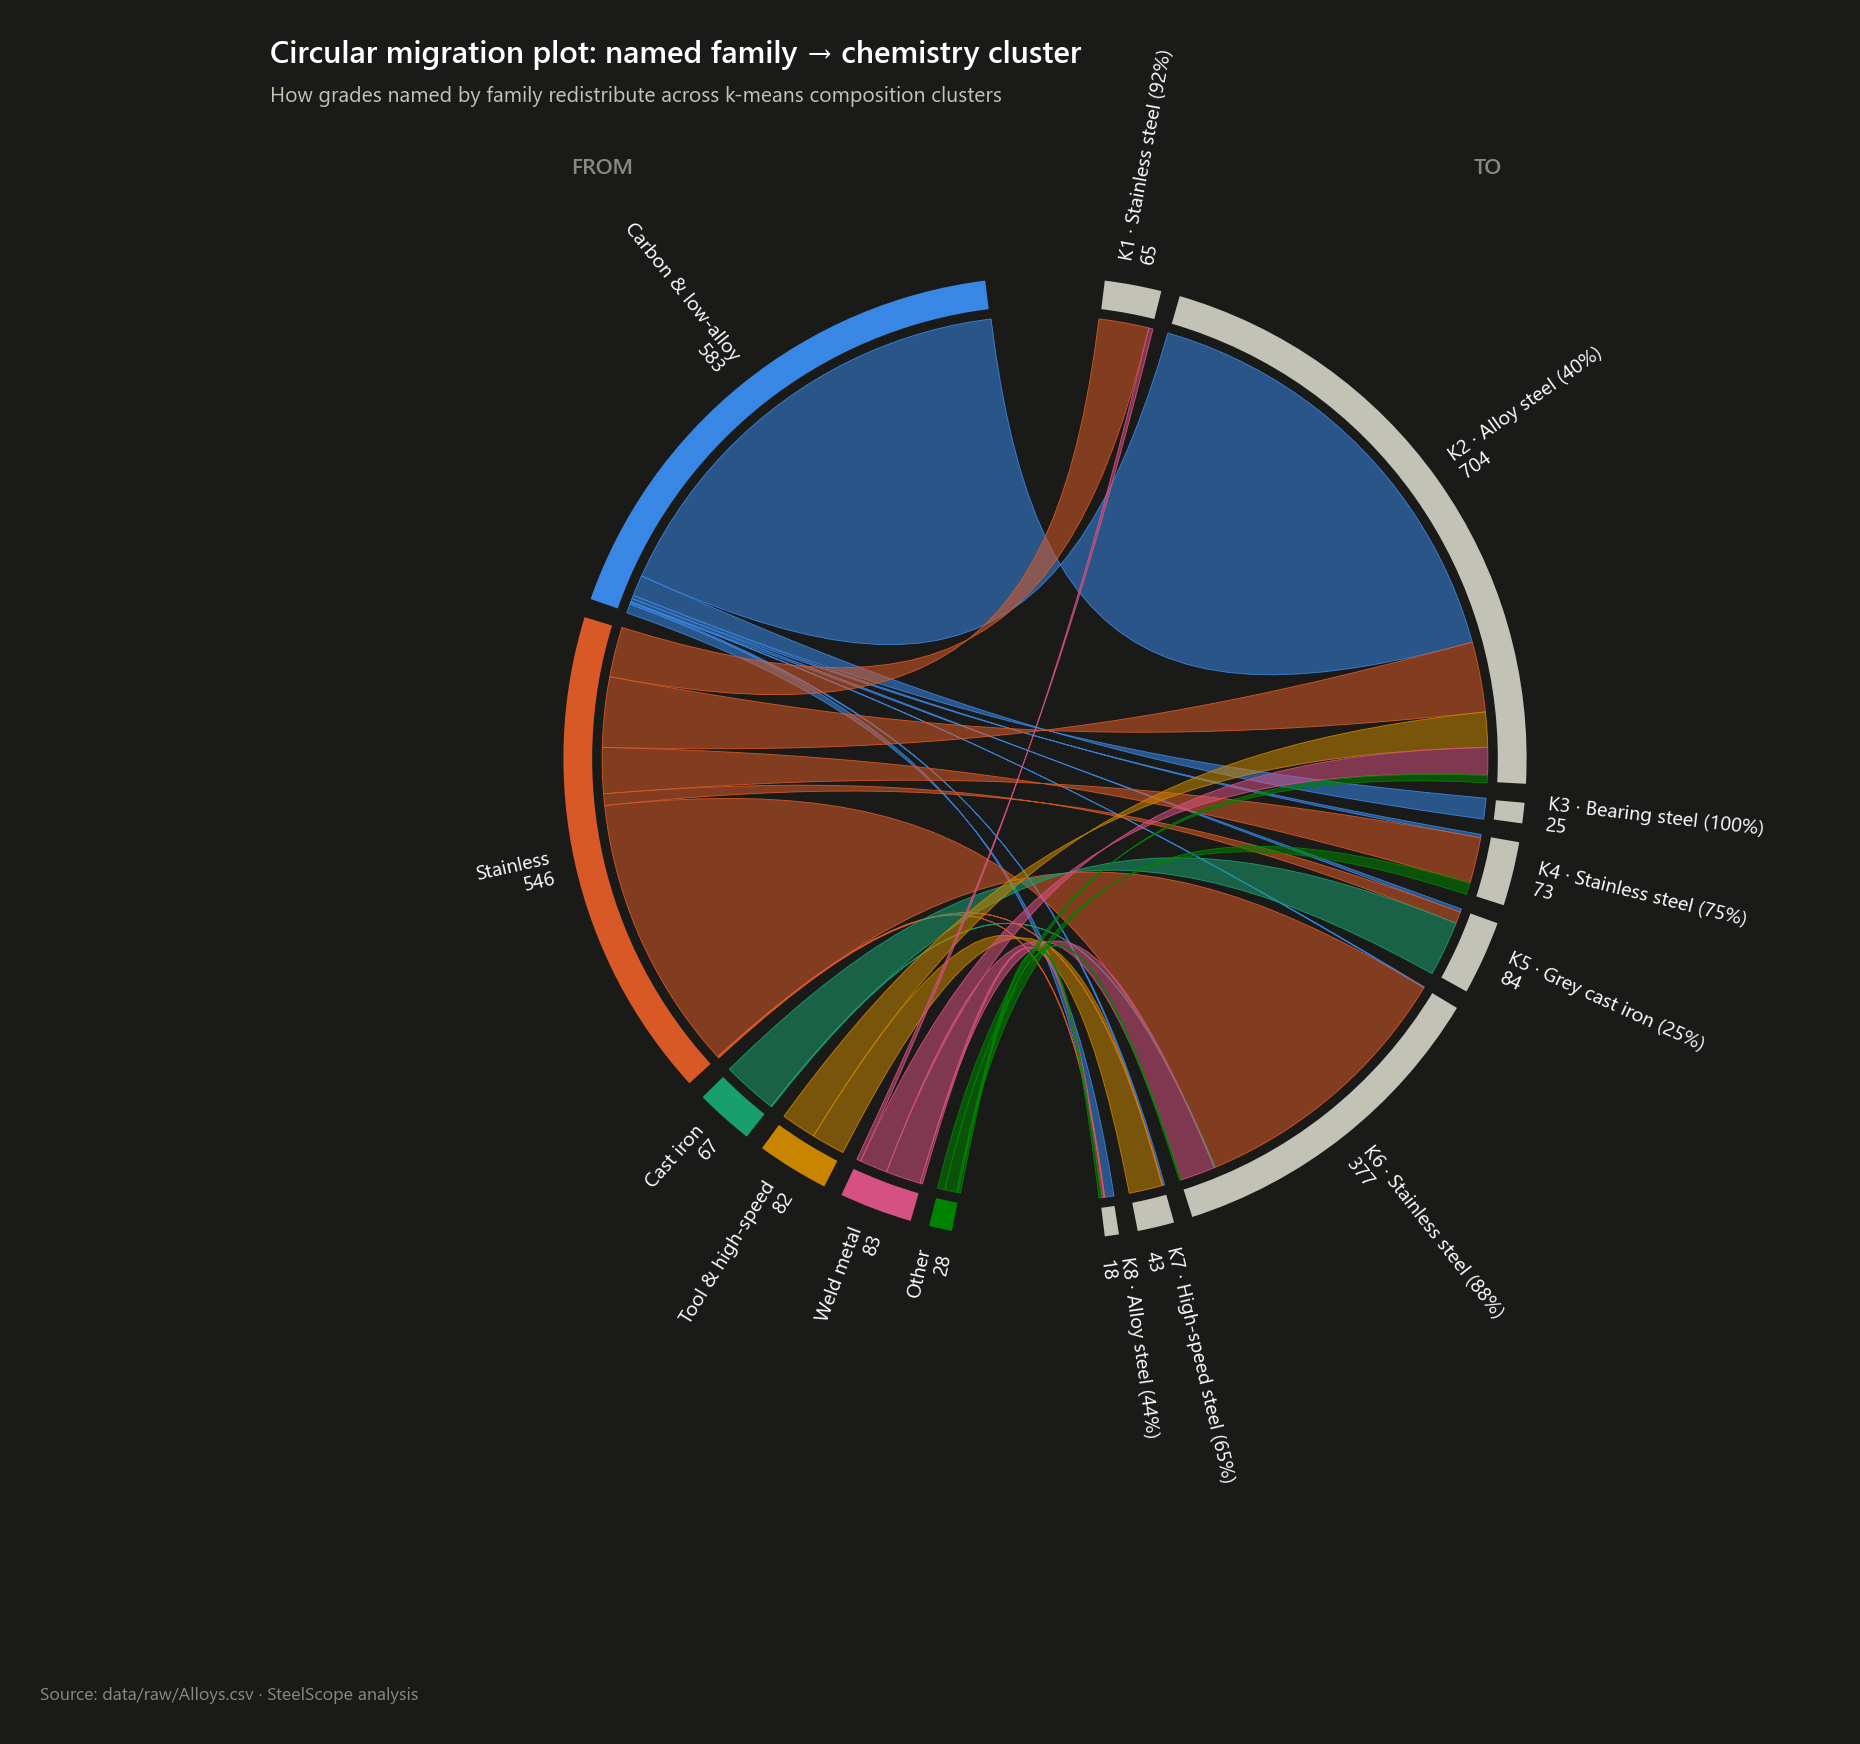

In [12]:
f2 = V.flow_family_to_cluster(grades, labels, names)
src2 = [s for s in VS.FAMILY_GROUP_ORDER if s in set(f2.source)]
tgt2 = [names[i] for i in sorted(names)]
display(f2.pivot(index="source", columns="target", values="value").fillna(0).astype(int))
show(VS.circular_migration(f2, src2, tgt2, VS.GROUP_COLOR, "Circular migration plot: named family → chemistry cluster",
                           "How grades named by family redistribute across k-means composition clusters"), "04_23_chord_family_to_cluster")

**Takeaway.** Stainless grades fan out over several chemistry clusters (austenitic, ferritic, N/Mn-rich), so the
name "stainless" hides real chemical diversity. Carbon & low-alloy grades flow almost entirely into the lean
clusters together with tool and other steels: their family names reflect use and heat treatment, not distinct
chemistry.

## 8 · Ring diagram, circular columns and treemap

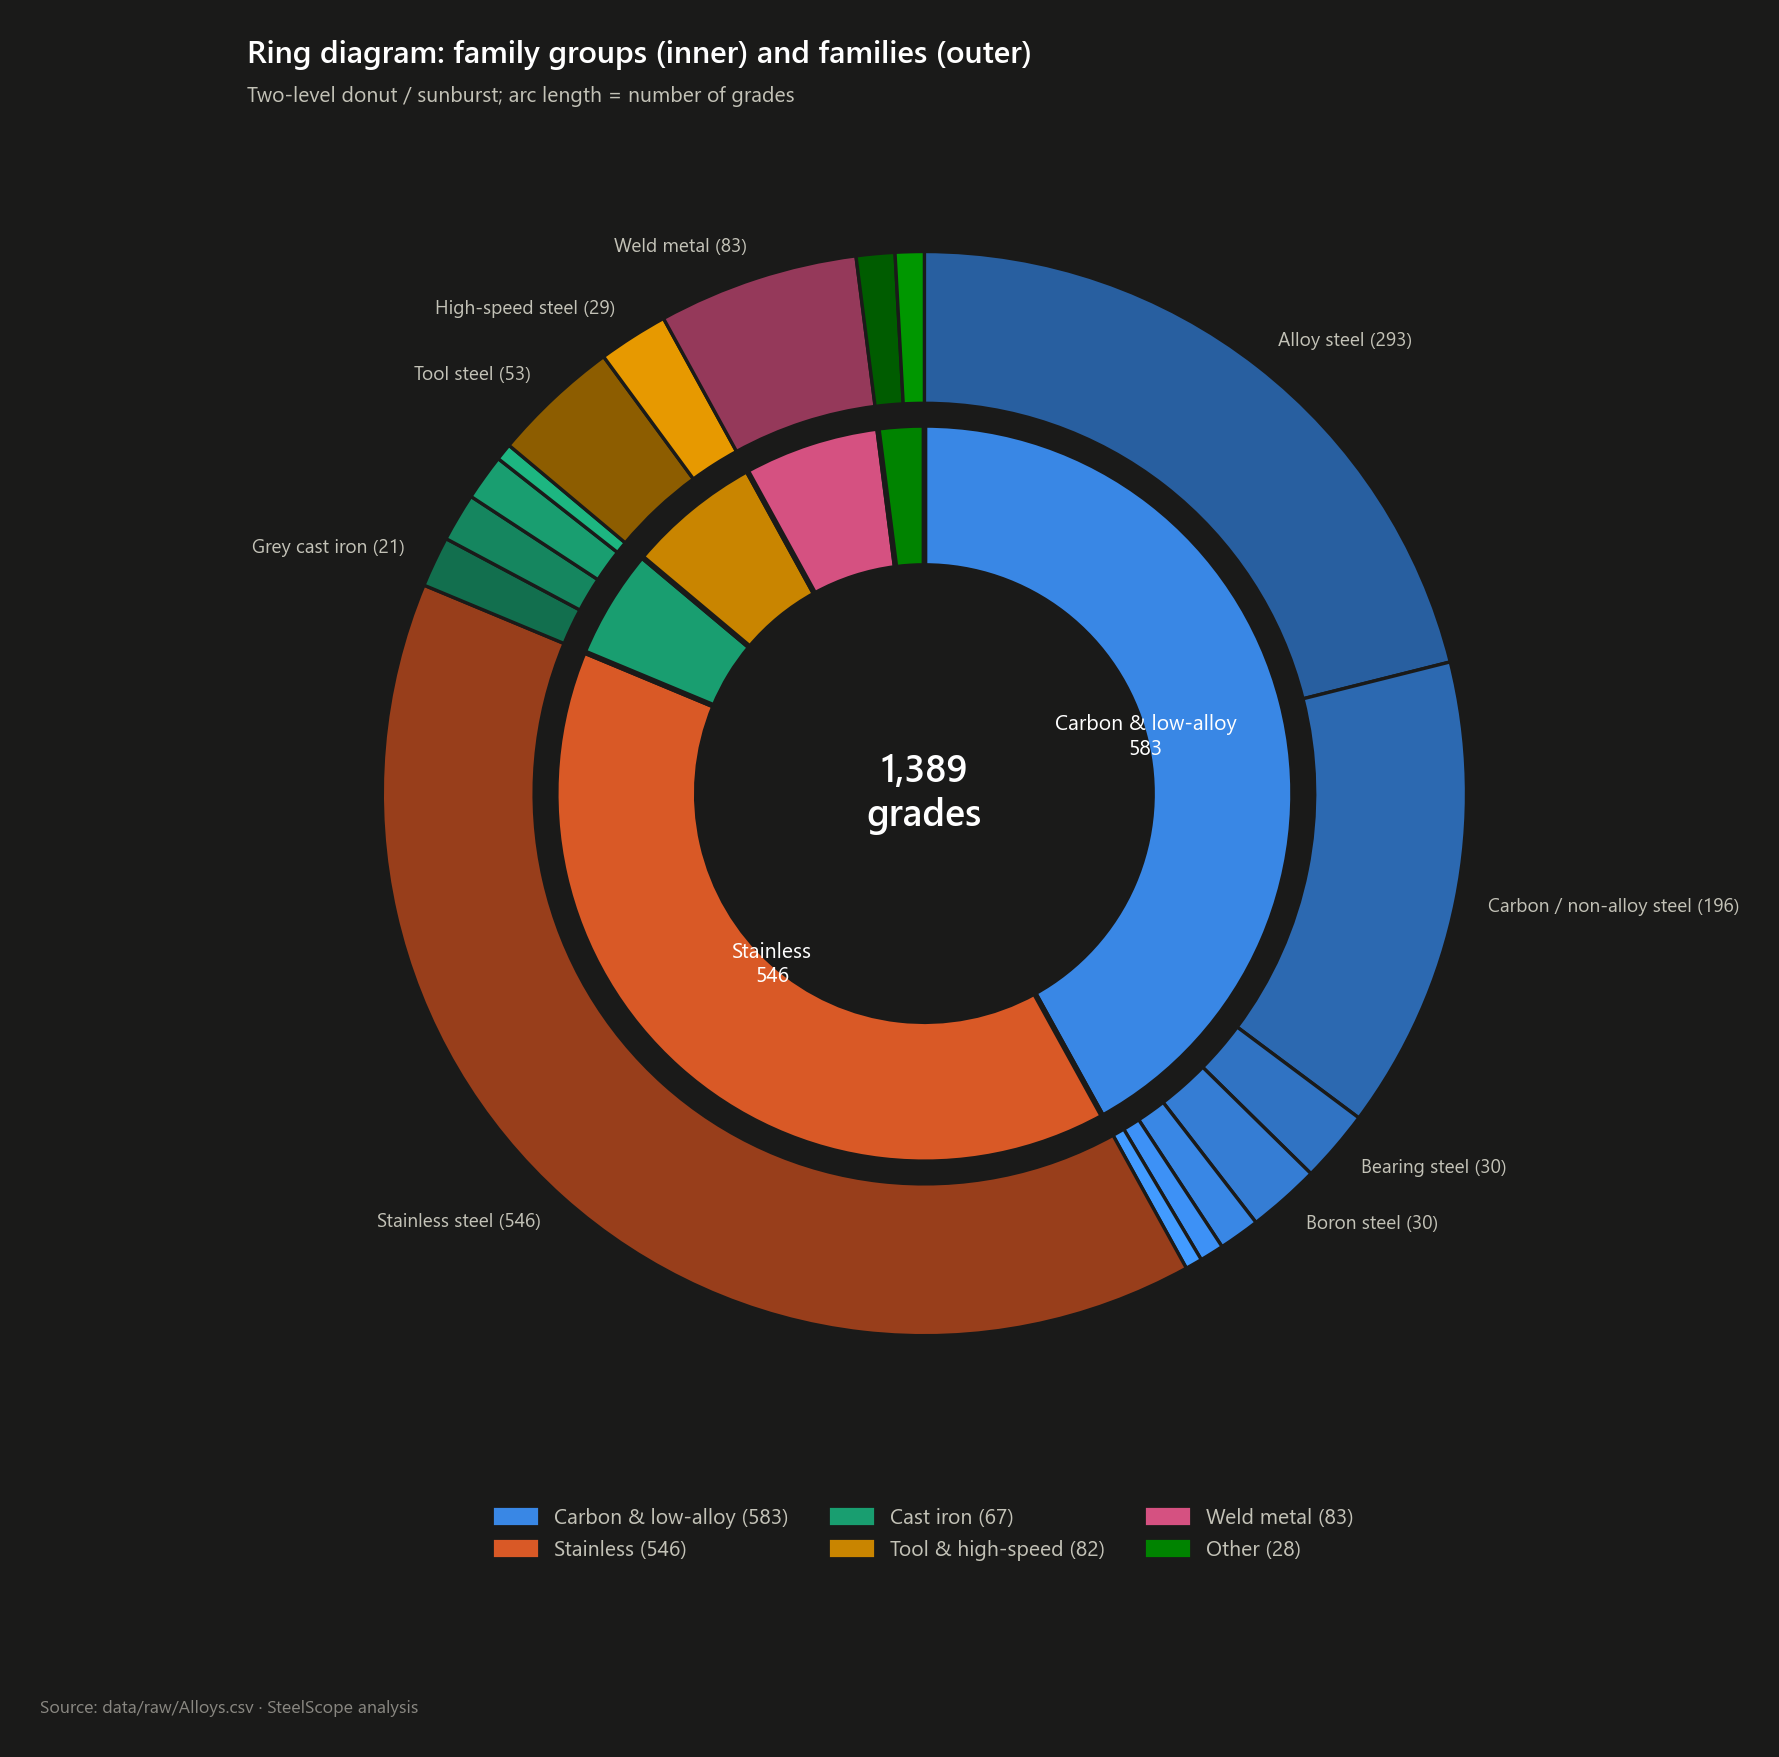

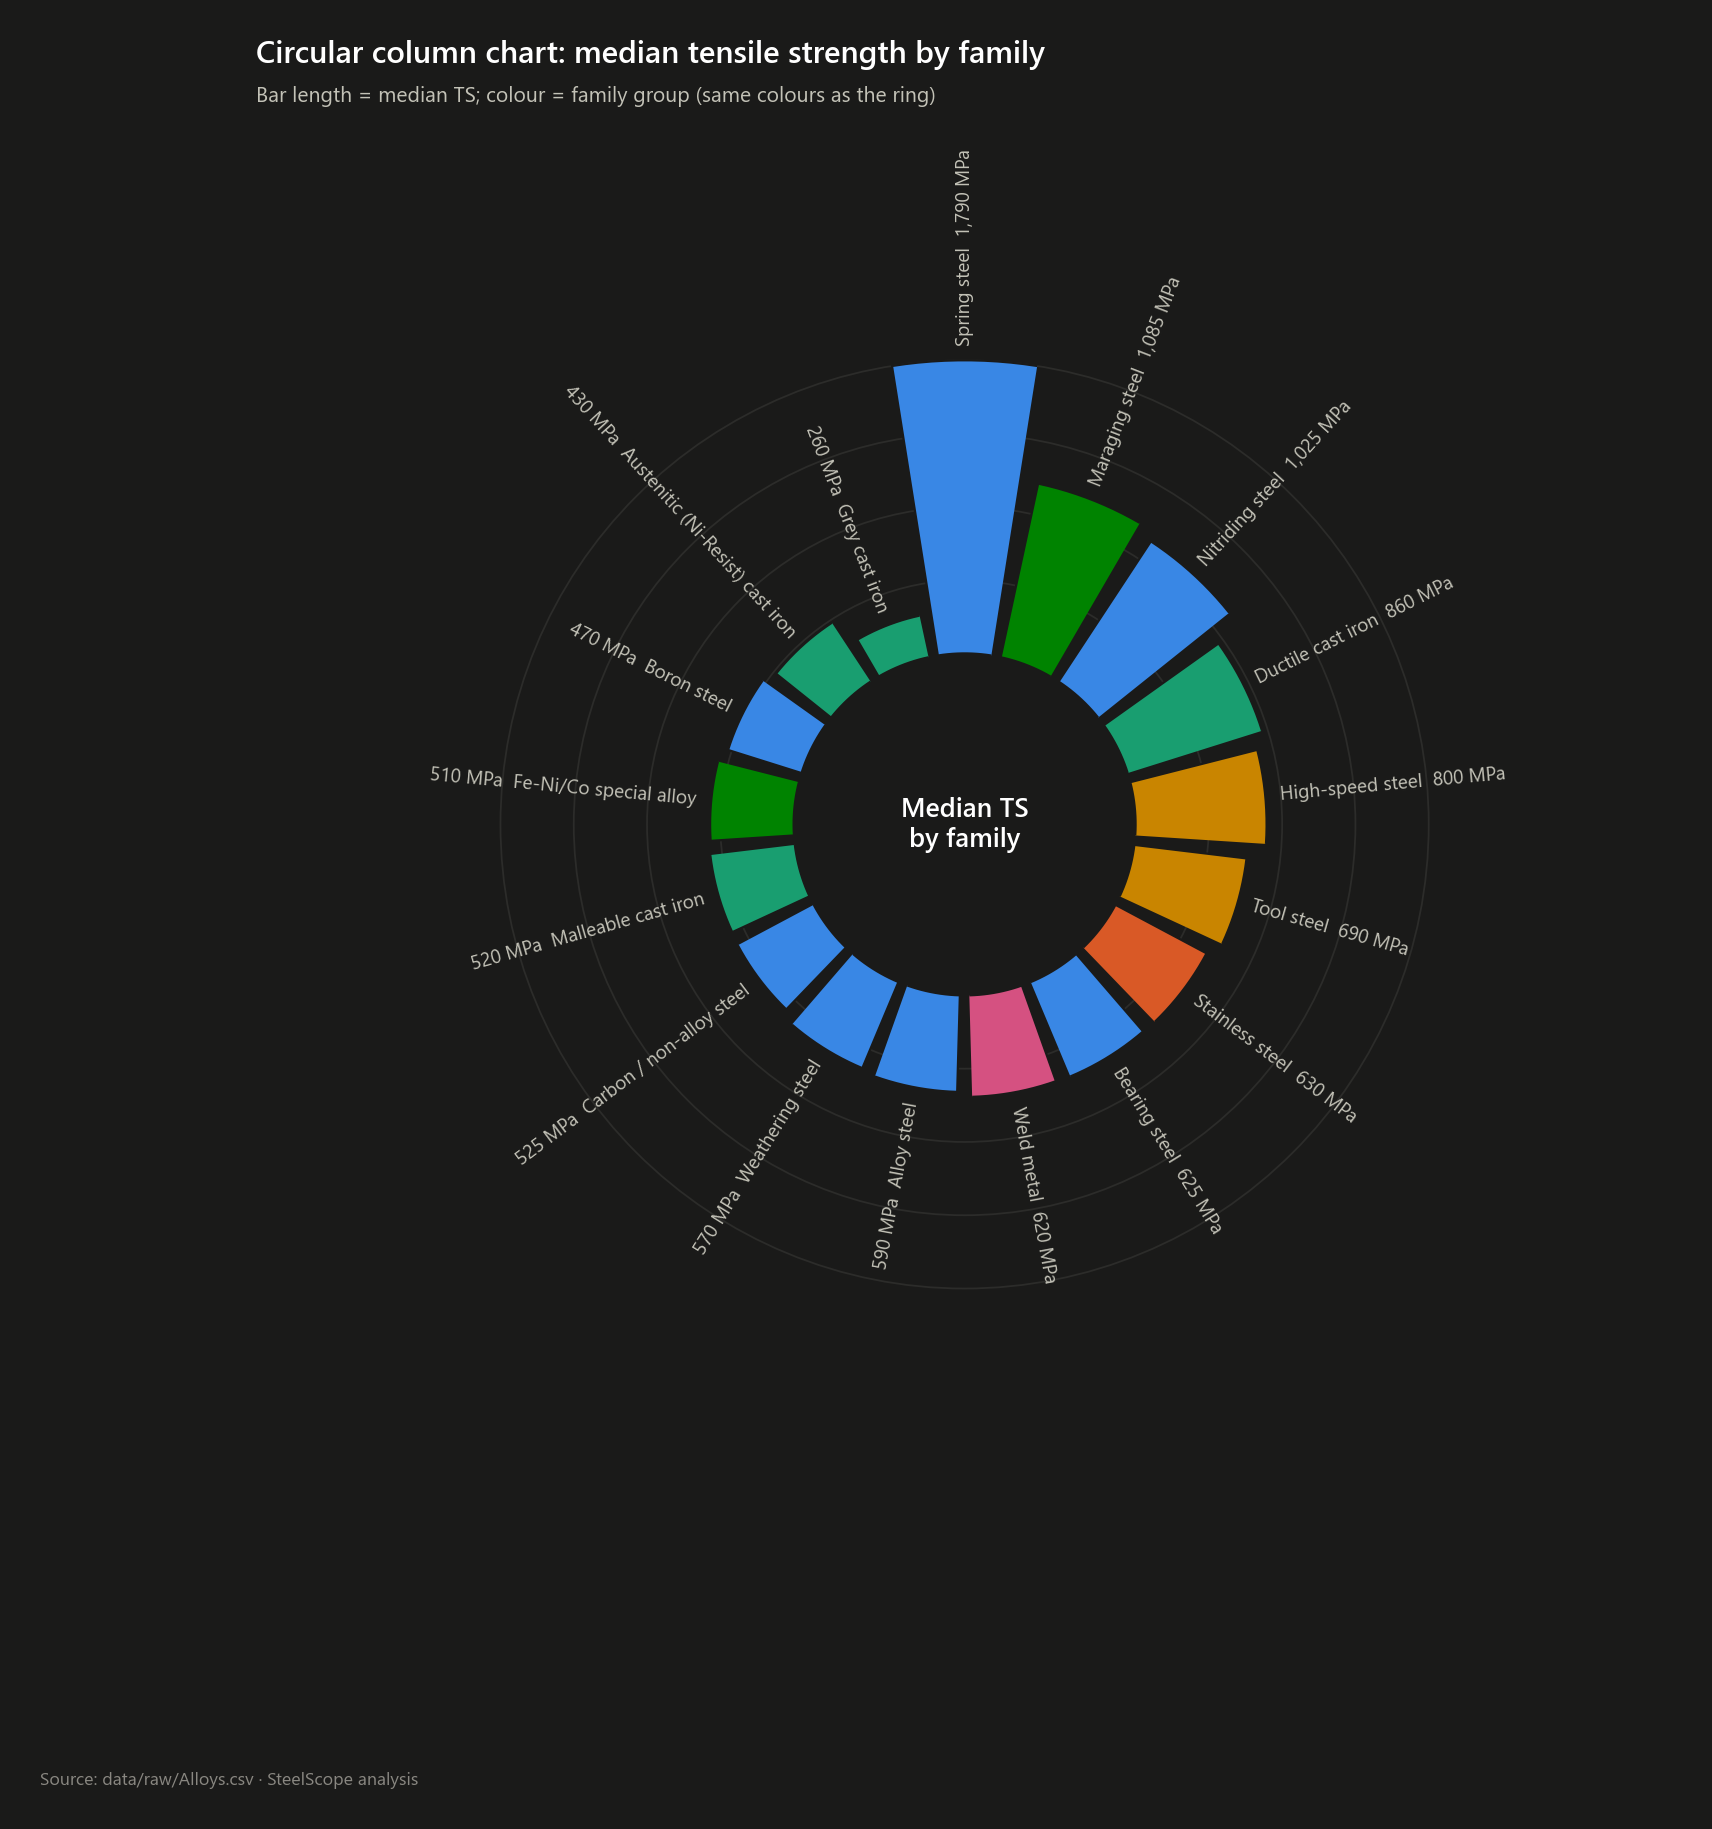

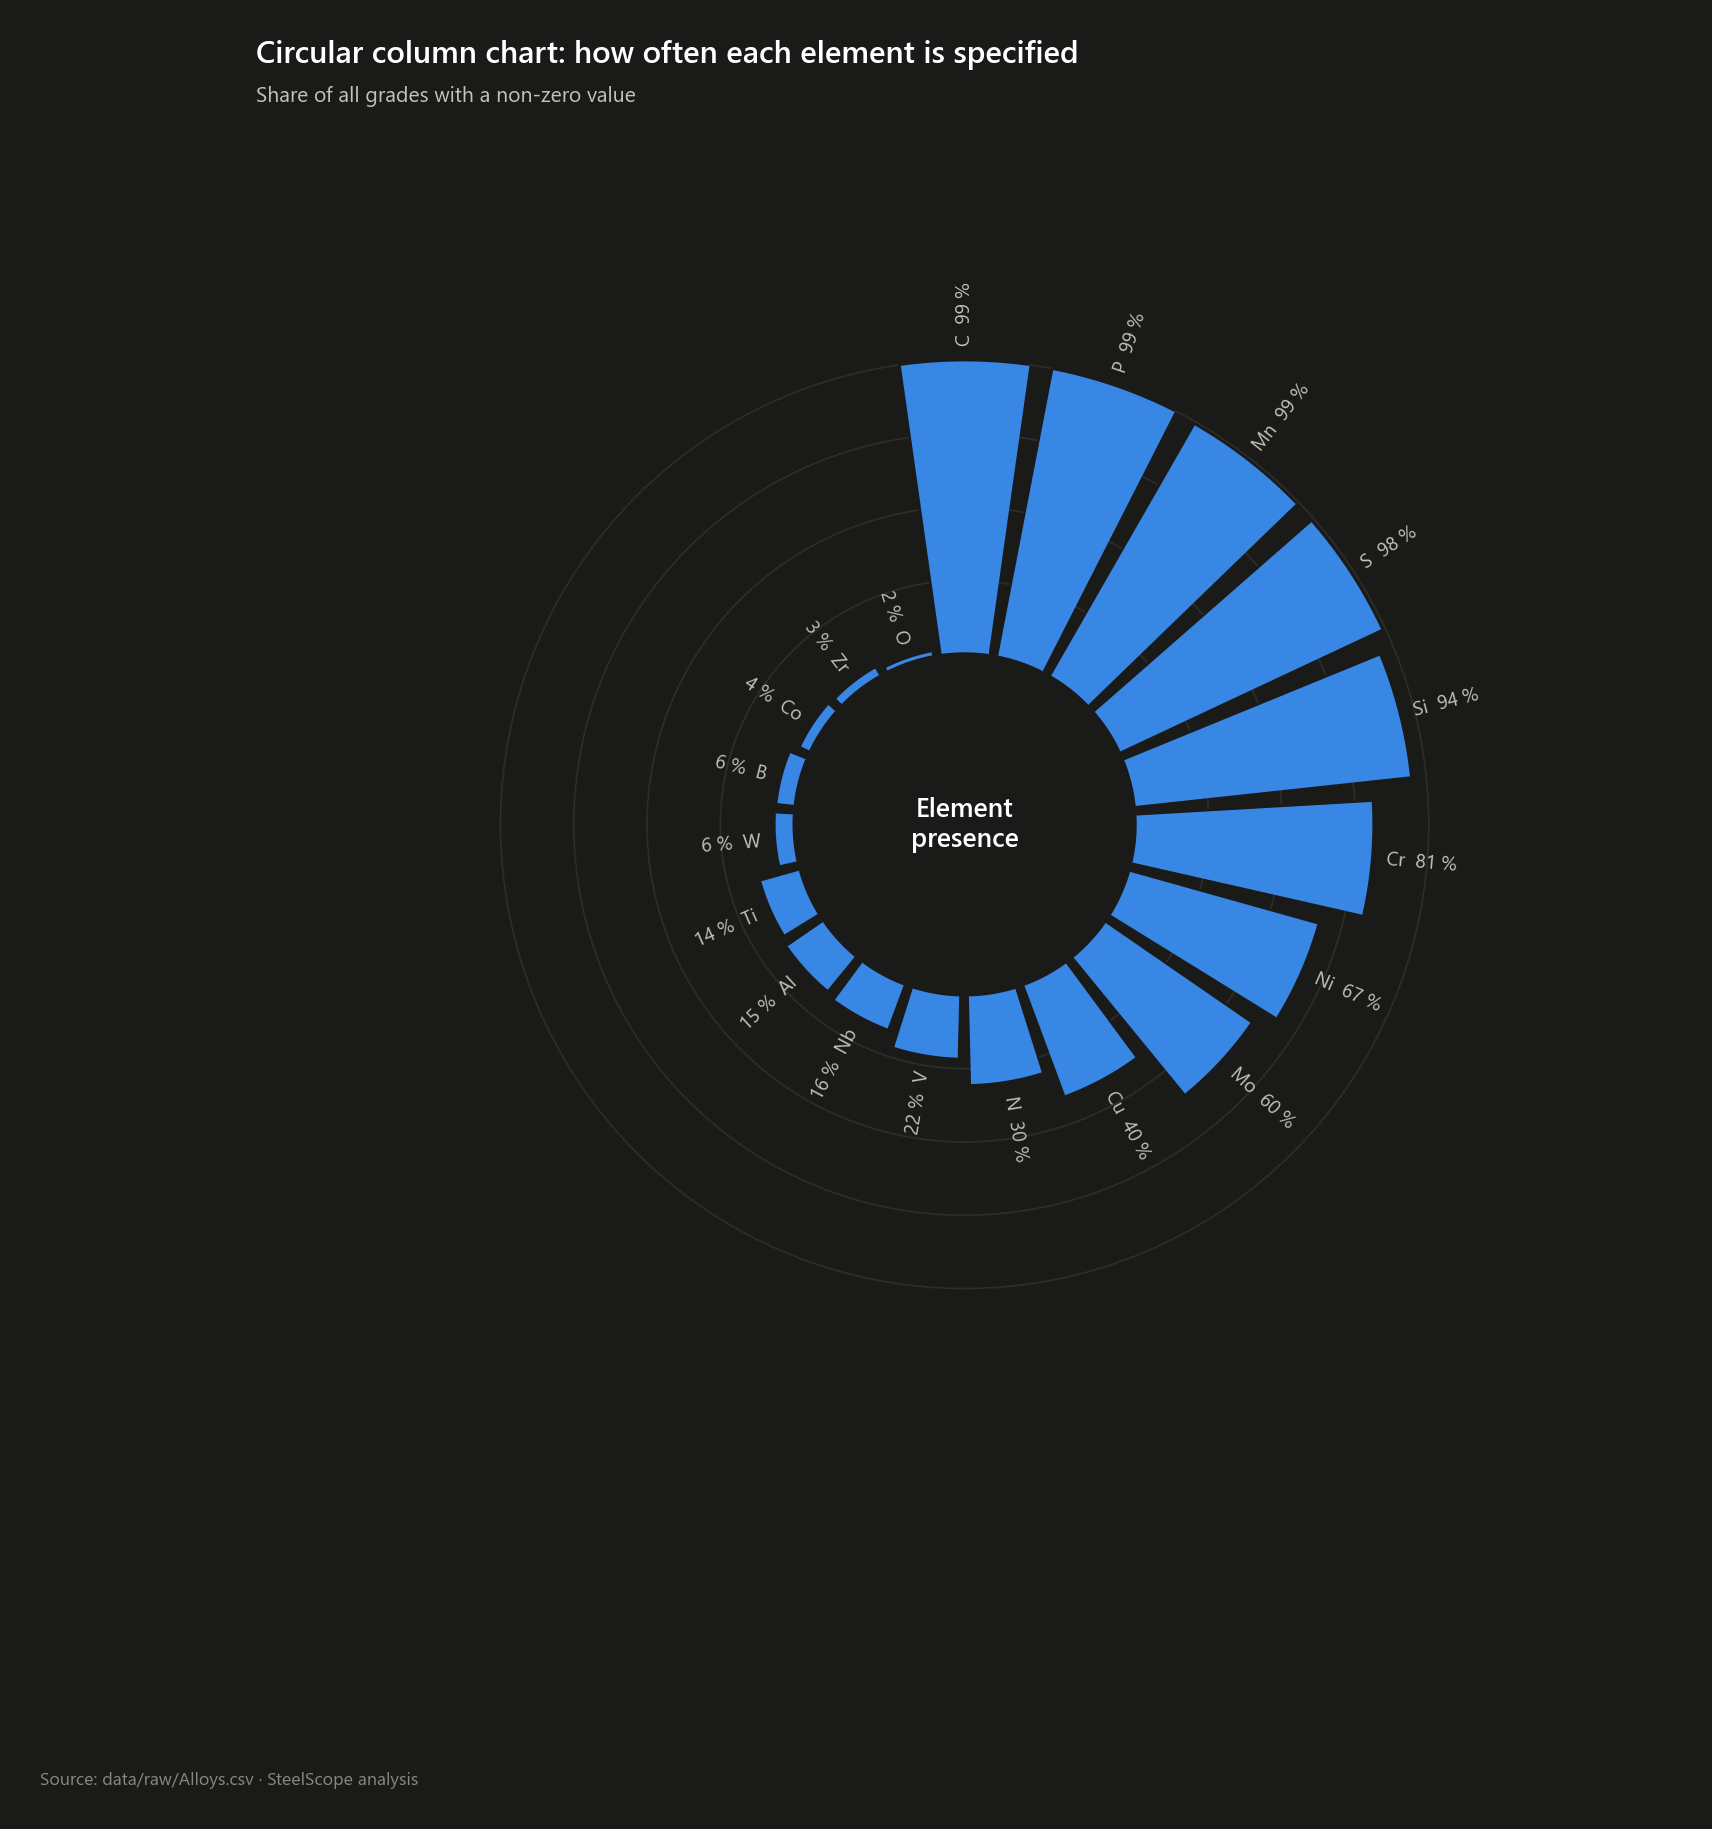

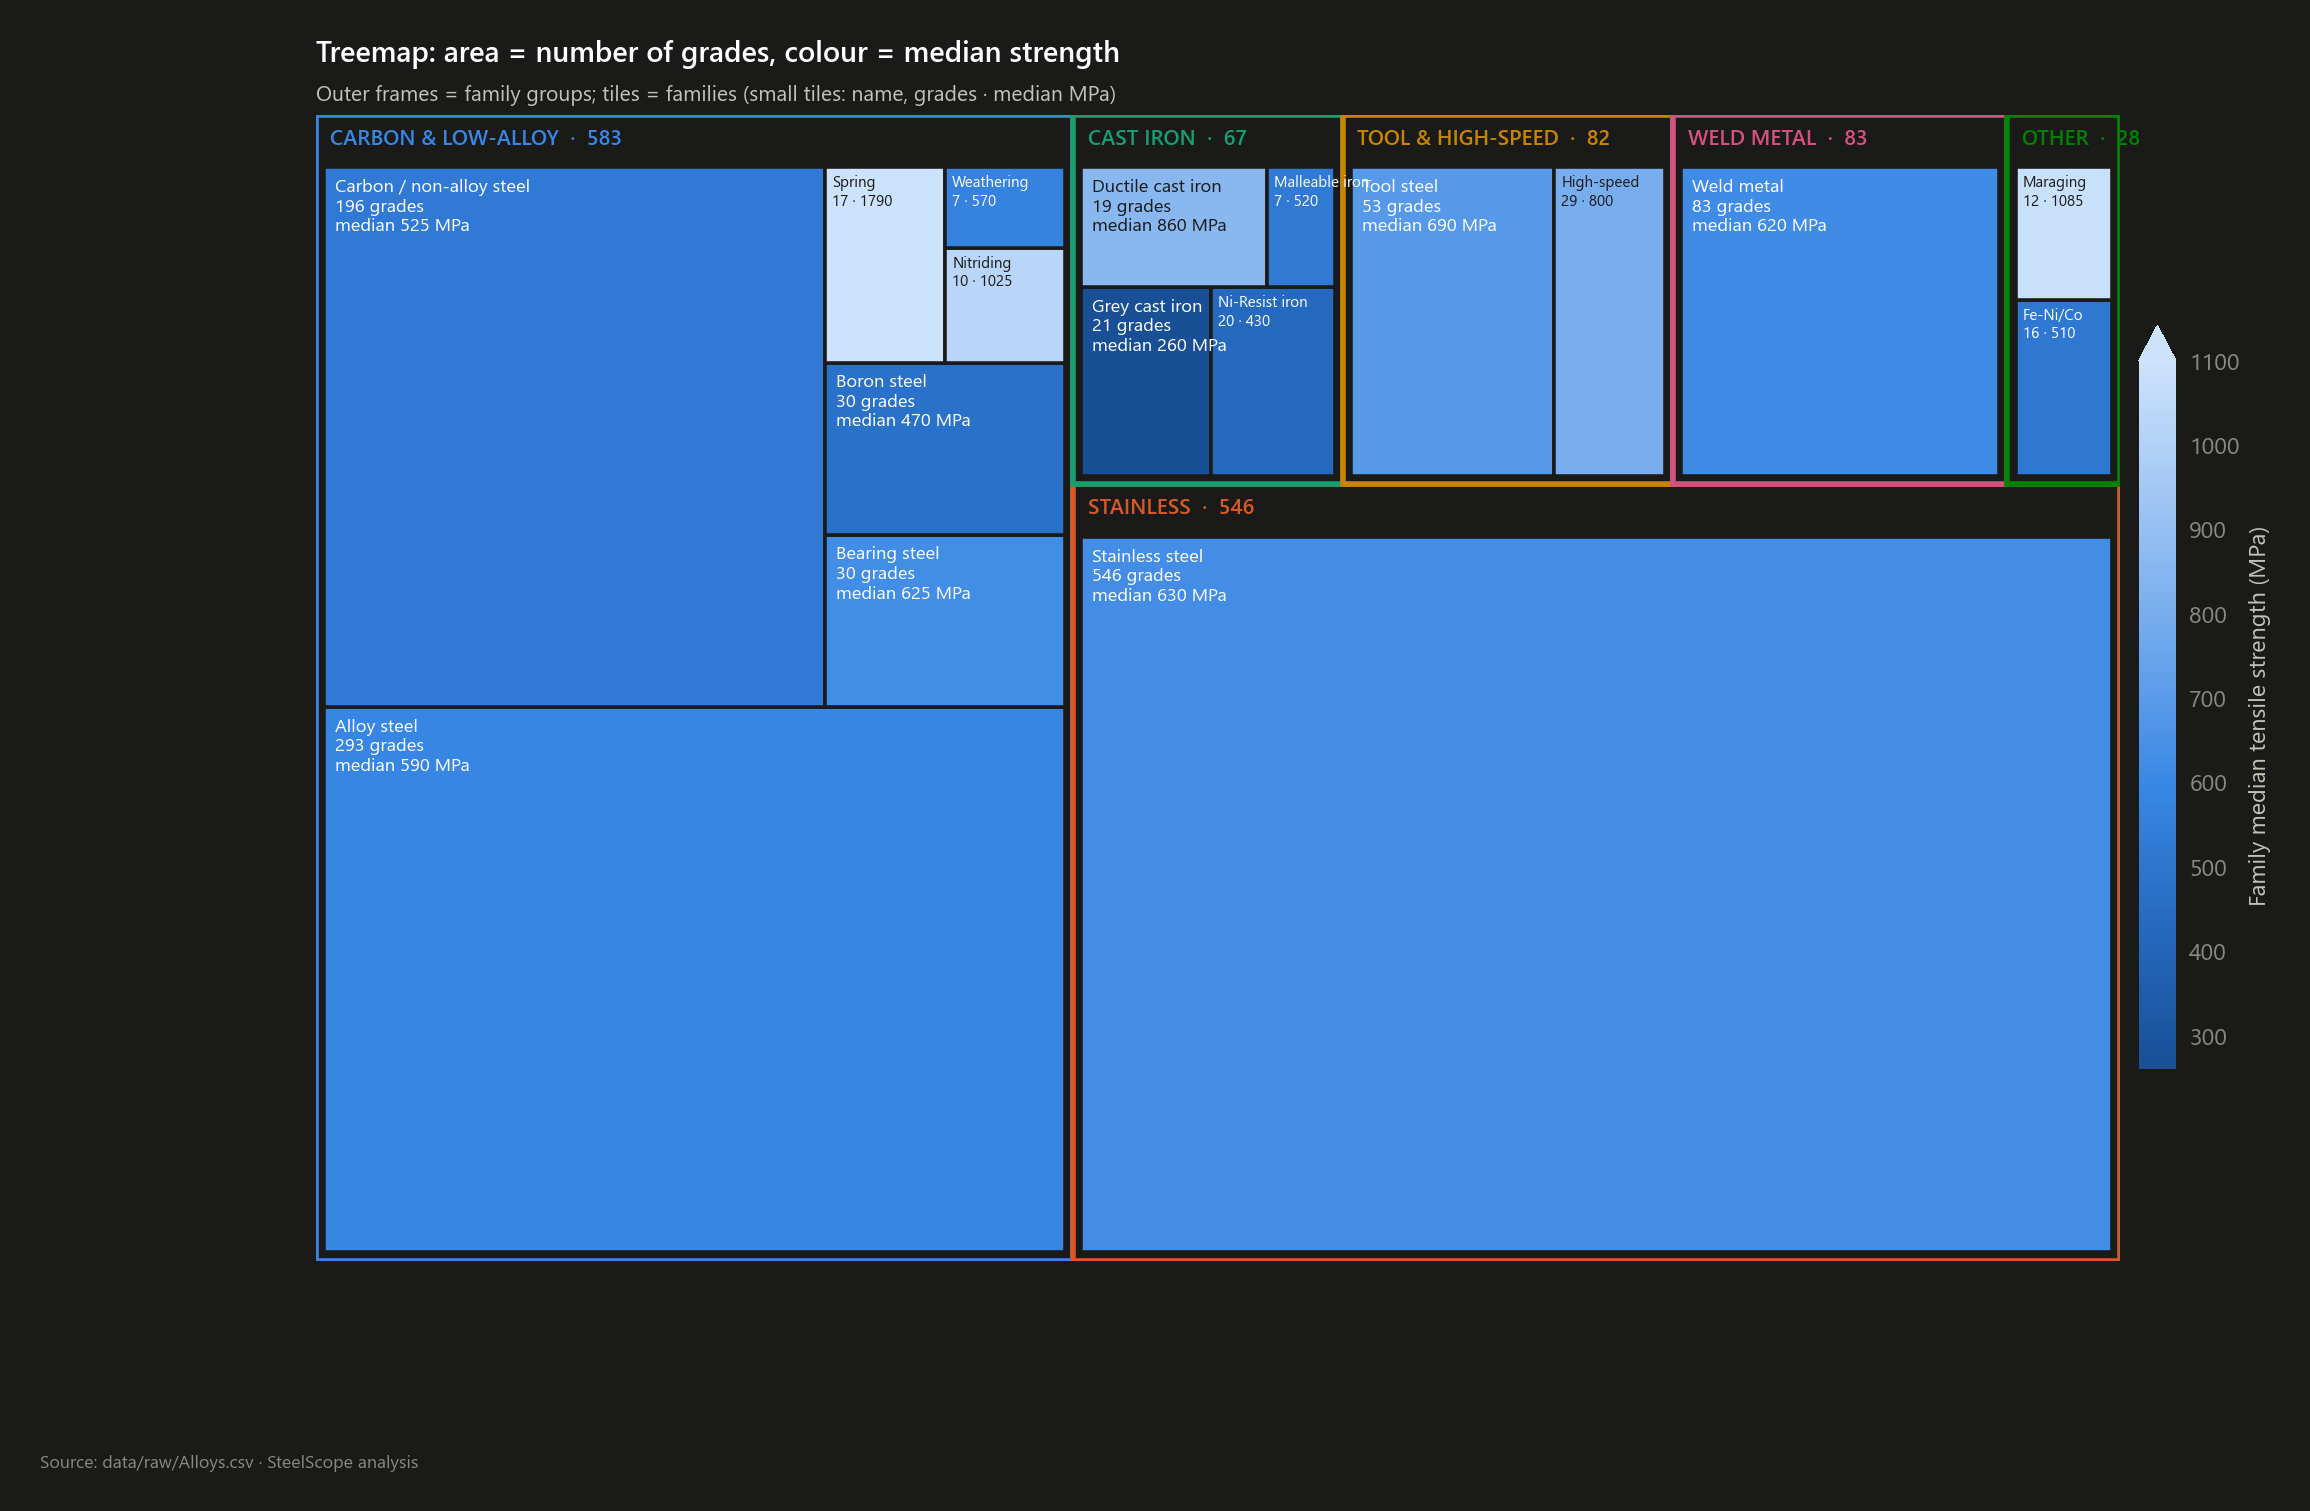

In [13]:
show(VS.ring_chart(g), "04_24_ring_families")
fam_med = m.groupby("family_label")[V.TS].median().sort_values(ascending=False)
grp_of = g.drop_duplicates("family_label").set_index("family_label")["family_group"]
show(VS.circular_columns(fam_med, [VS.GROUP_COLOR[grp_of[f]] for f in fam_med.index],
                         "Circular column chart: median tensile strength by family",
                         "Bar length = median TS; colour = family group (same colours as the ring)", " MPa", "Median TS\nby family"),
     "04_25_circular_columns_strength")
presence = (g[["C","Mn","Si","P","S","Cr","Ni","Mo","Cu","N","V","Nb","Ti","Al","W","Co","B","Zr","O"]] > 0).mean().sort_values(ascending=False) * 100
show(VS.circular_columns(presence, [P.BLUE] * len(presence), "Circular column chart: how often each element is specified",
                         "Share of all grades with a non-zero value", " %", "Element\npresence"), "04_26_circular_columns_elements")
show(VS.treemap(g), "04_27_treemap_families")

**Takeaway.** Stainless steel alone is about four in ten grades. The circular columns rank families by strength
at a glance (spring, maraging and nitriding steels at the top; grey cast iron at the bottom), and the element
ring shows that C, Mn, Si, P and S are specified for nearly every grade while W, Co, B and Zr are rare specialists.

## 9 · Radar charts

,C,Mn,Si,Cr,Ni,Mo,V,W,Co,Cu
family_group,,,,,,,,,,
Carbon & low-alloy,0.180,0.750,0.225,0.200,0.000,0.050,0.000,0.000,0.000,0.000
Stainless,0.035,0.750,0.500,18.250,7.000,0.250,0.000,0.000,0.000,0.000
Cast iron,3.250,0.600,2.150,0.000,0.000,0.000,0.000,0.000,0.000,0.000
Tool & high-speed,0.830,0.300,0.312,3.900,0.150,0.950,0.525,1.300,0.000,0.125
Weld metal,0.050,1.500,0.500,16.500,6.250,0.525,0.000,0.000,0.000,0.375
Other,0.018,0.250,0.150,0.125,24.875,3.250,0.000,0.000,7.750,0.000


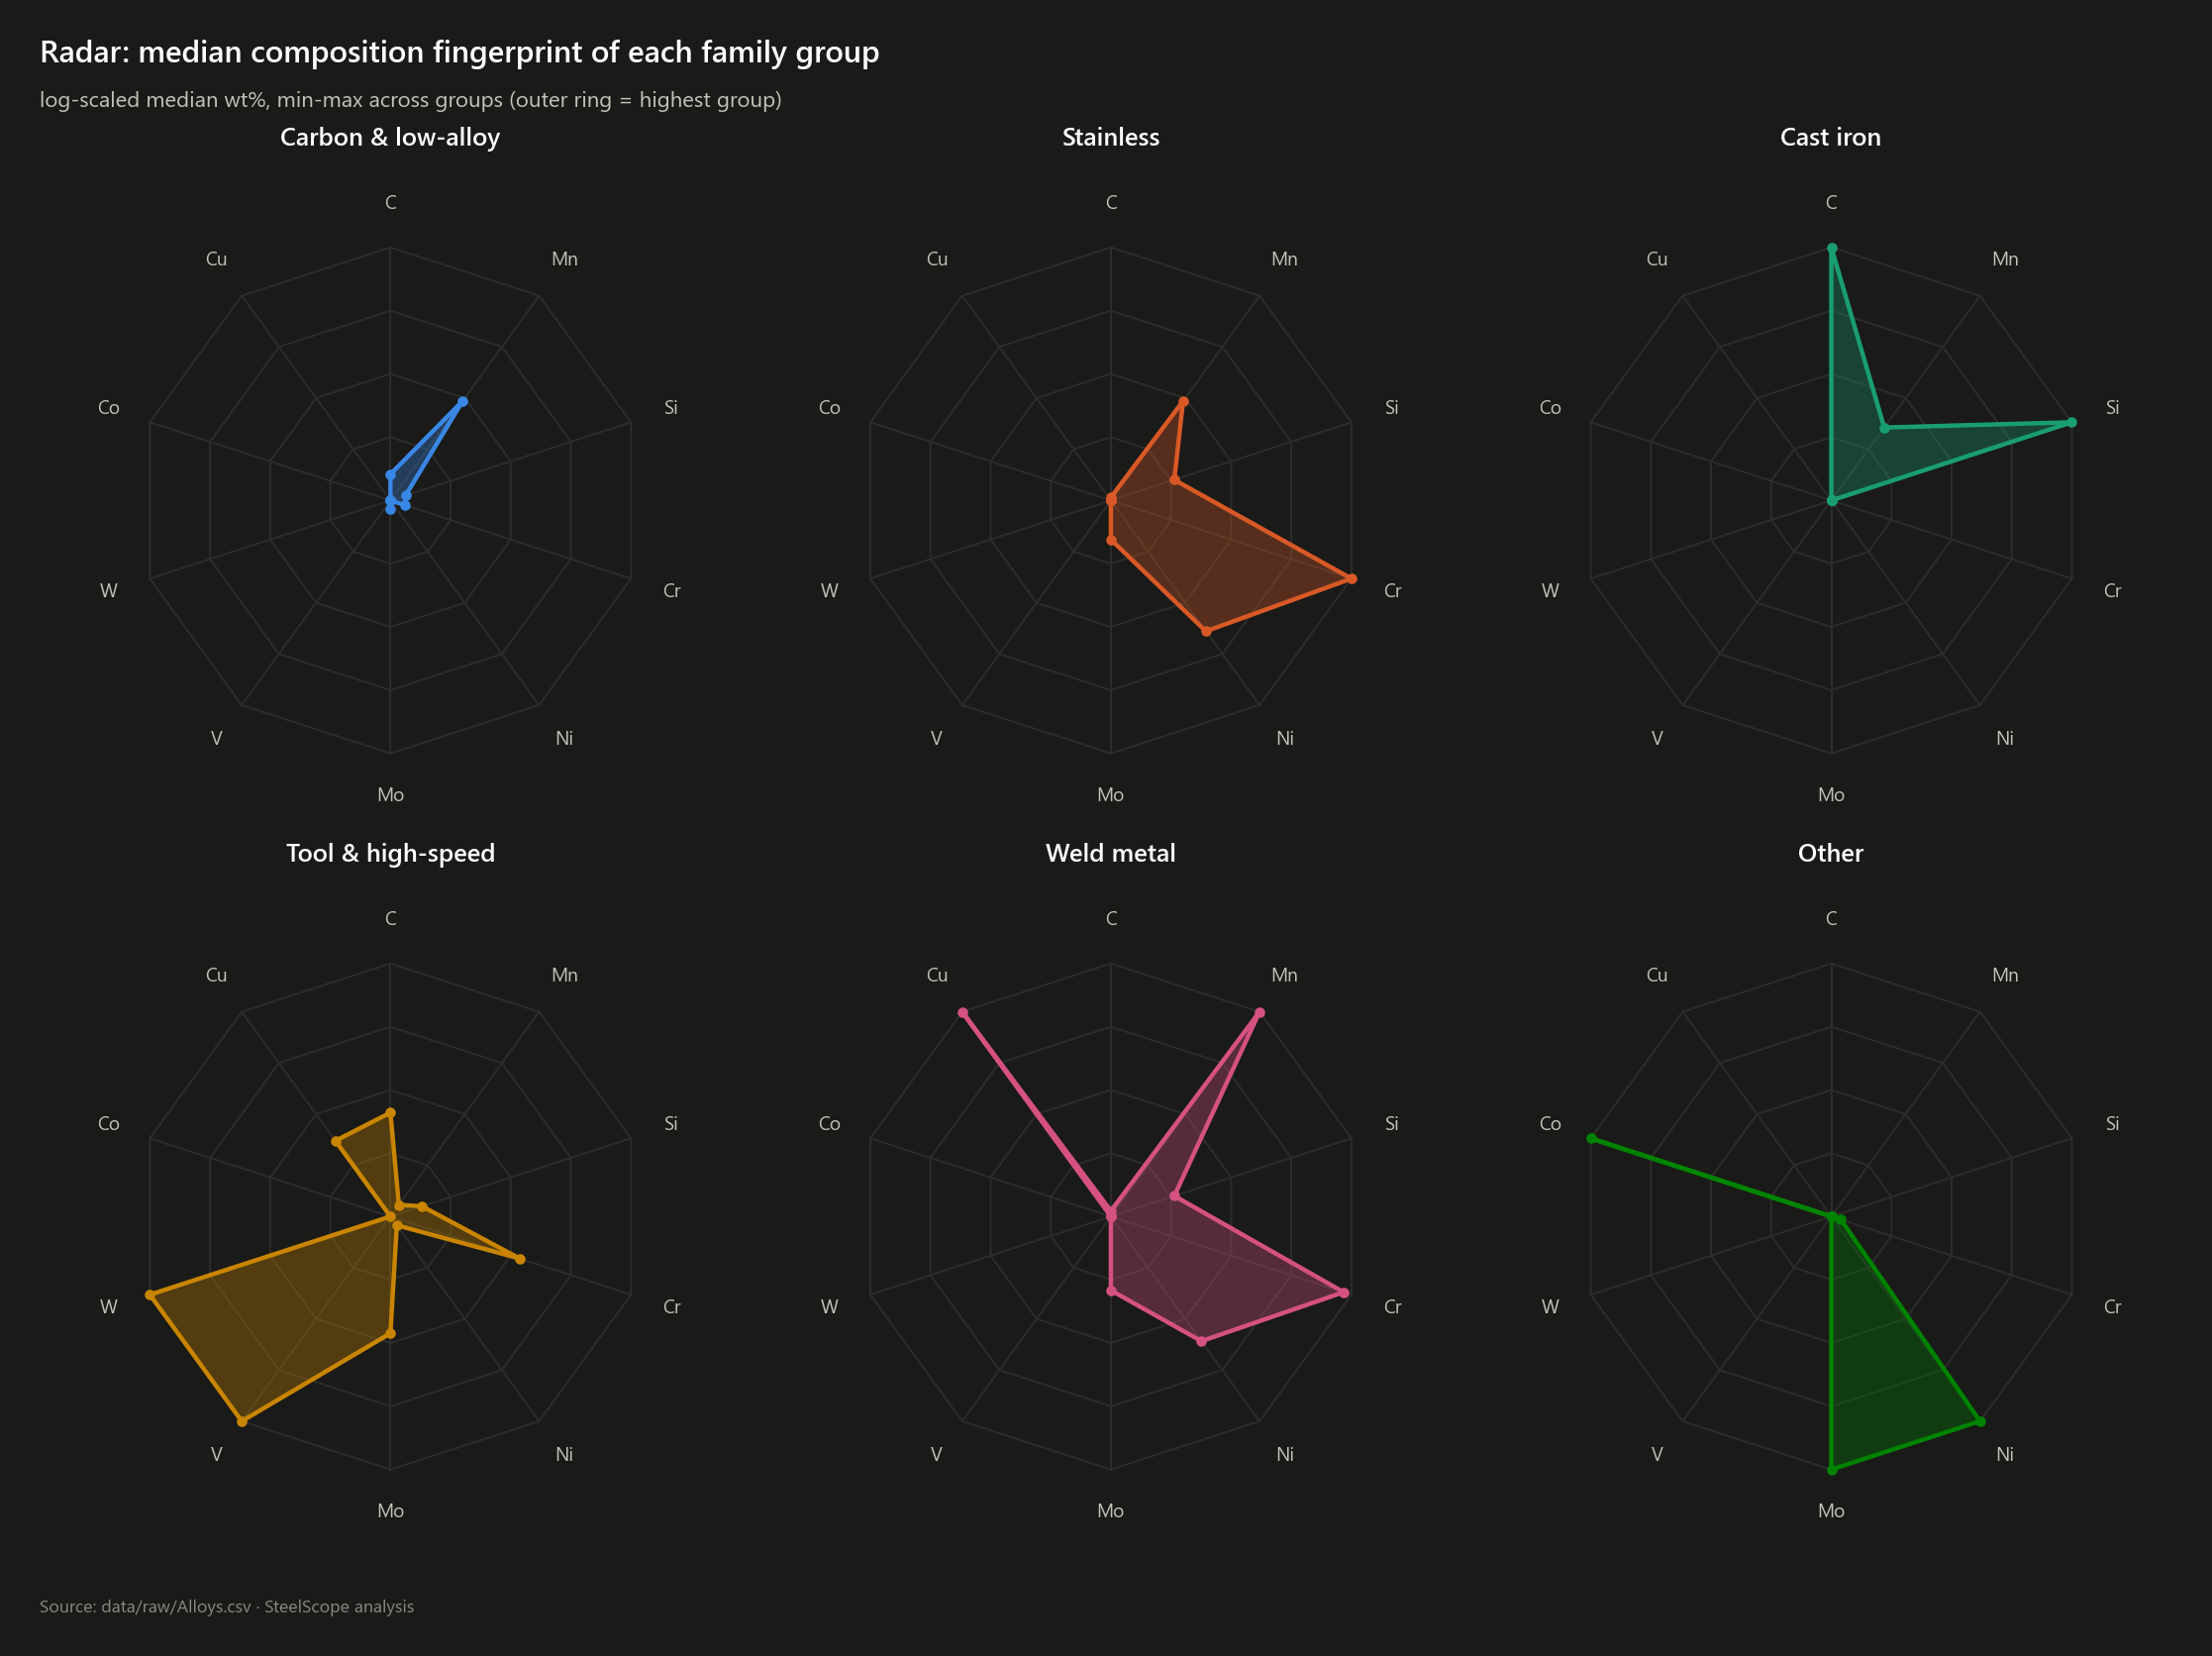

,short_name,display_name,tensile_strength_mpa,liquidus_c,carbon_equivalent
0,AISI 1018,SAE-AISI 1018 (G10180) Carbon Steel,430.000,"1,460.000",0.300
1,AISI 1045,"SAE-AISI 1045 (S45C,G10450) Carbon Steel",620.000,"1,460.000",0.590
2,AISI 4140,"SAE-AISI 4140 (SCM440,G41400) Cr-Mo Steel",690.000,"1,460.000",0.781
3,AISI 304,AISI 304 (S30400) Stainless Steel,580.000,"1,450.000",4.623
4,AISI 316,AISI 316 (S31600) Stainless Steel,520.000,"1,400.000",4.907
5,17-4 PH,"UNS S17400 (17-4 PH,Alloy 630) Stainless Steel",910.000,"1,440.000",3.852
6,M2 high-speed,SAE-AISI M2 (T11302) Molybdenum High-Speed Steel,760.000,"1,610.000",3.234
7,Grey iron 250,"ASTM Grade 35 or 250 (ISO 250, EN-JL 1040, F12401) Grey Cast Iron",250.000,"1,380.000",3.350
8,Maraging 300 (aged),Aged Grade 300 Maraging Steel,"2,030.000","1,480.000",2.237


,Tensile strength,Liquidus,Carbon eq.,Alloy content,C,Cr,Ni,Mo
AISI 1018,8.000,89.000,8.000,3.000,63.000,19.000,33.000,40.000
AISI 1045,55.000,89.000,25.000,6.000,83.000,19.000,33.000,40.000
AISI 4140,70.000,89.000,33.000,27.000,80.000,40.000,33.000,53.000
AISI 304,44.000,51.000,73.000,71.000,29.000,81.000,78.000,40.000
AISI 316,27.000,11.000,77.000,77.000,29.000,72.000,84.000,89.000
17-4 PH,93.000,39.000,65.000,65.000,24.000,67.000,66.000,40.000
M2 high-speed,81.000,99.000,56.000,59.000,92.000,53.000,42.000,97.000
Grey iron 250,1.000,5.000,58.000,47.000,99.000,19.000,33.000,40.000
Maraging 300 (aged),100.000,96.000,48.000,78.000,16.000,19.000,90.000,97.000


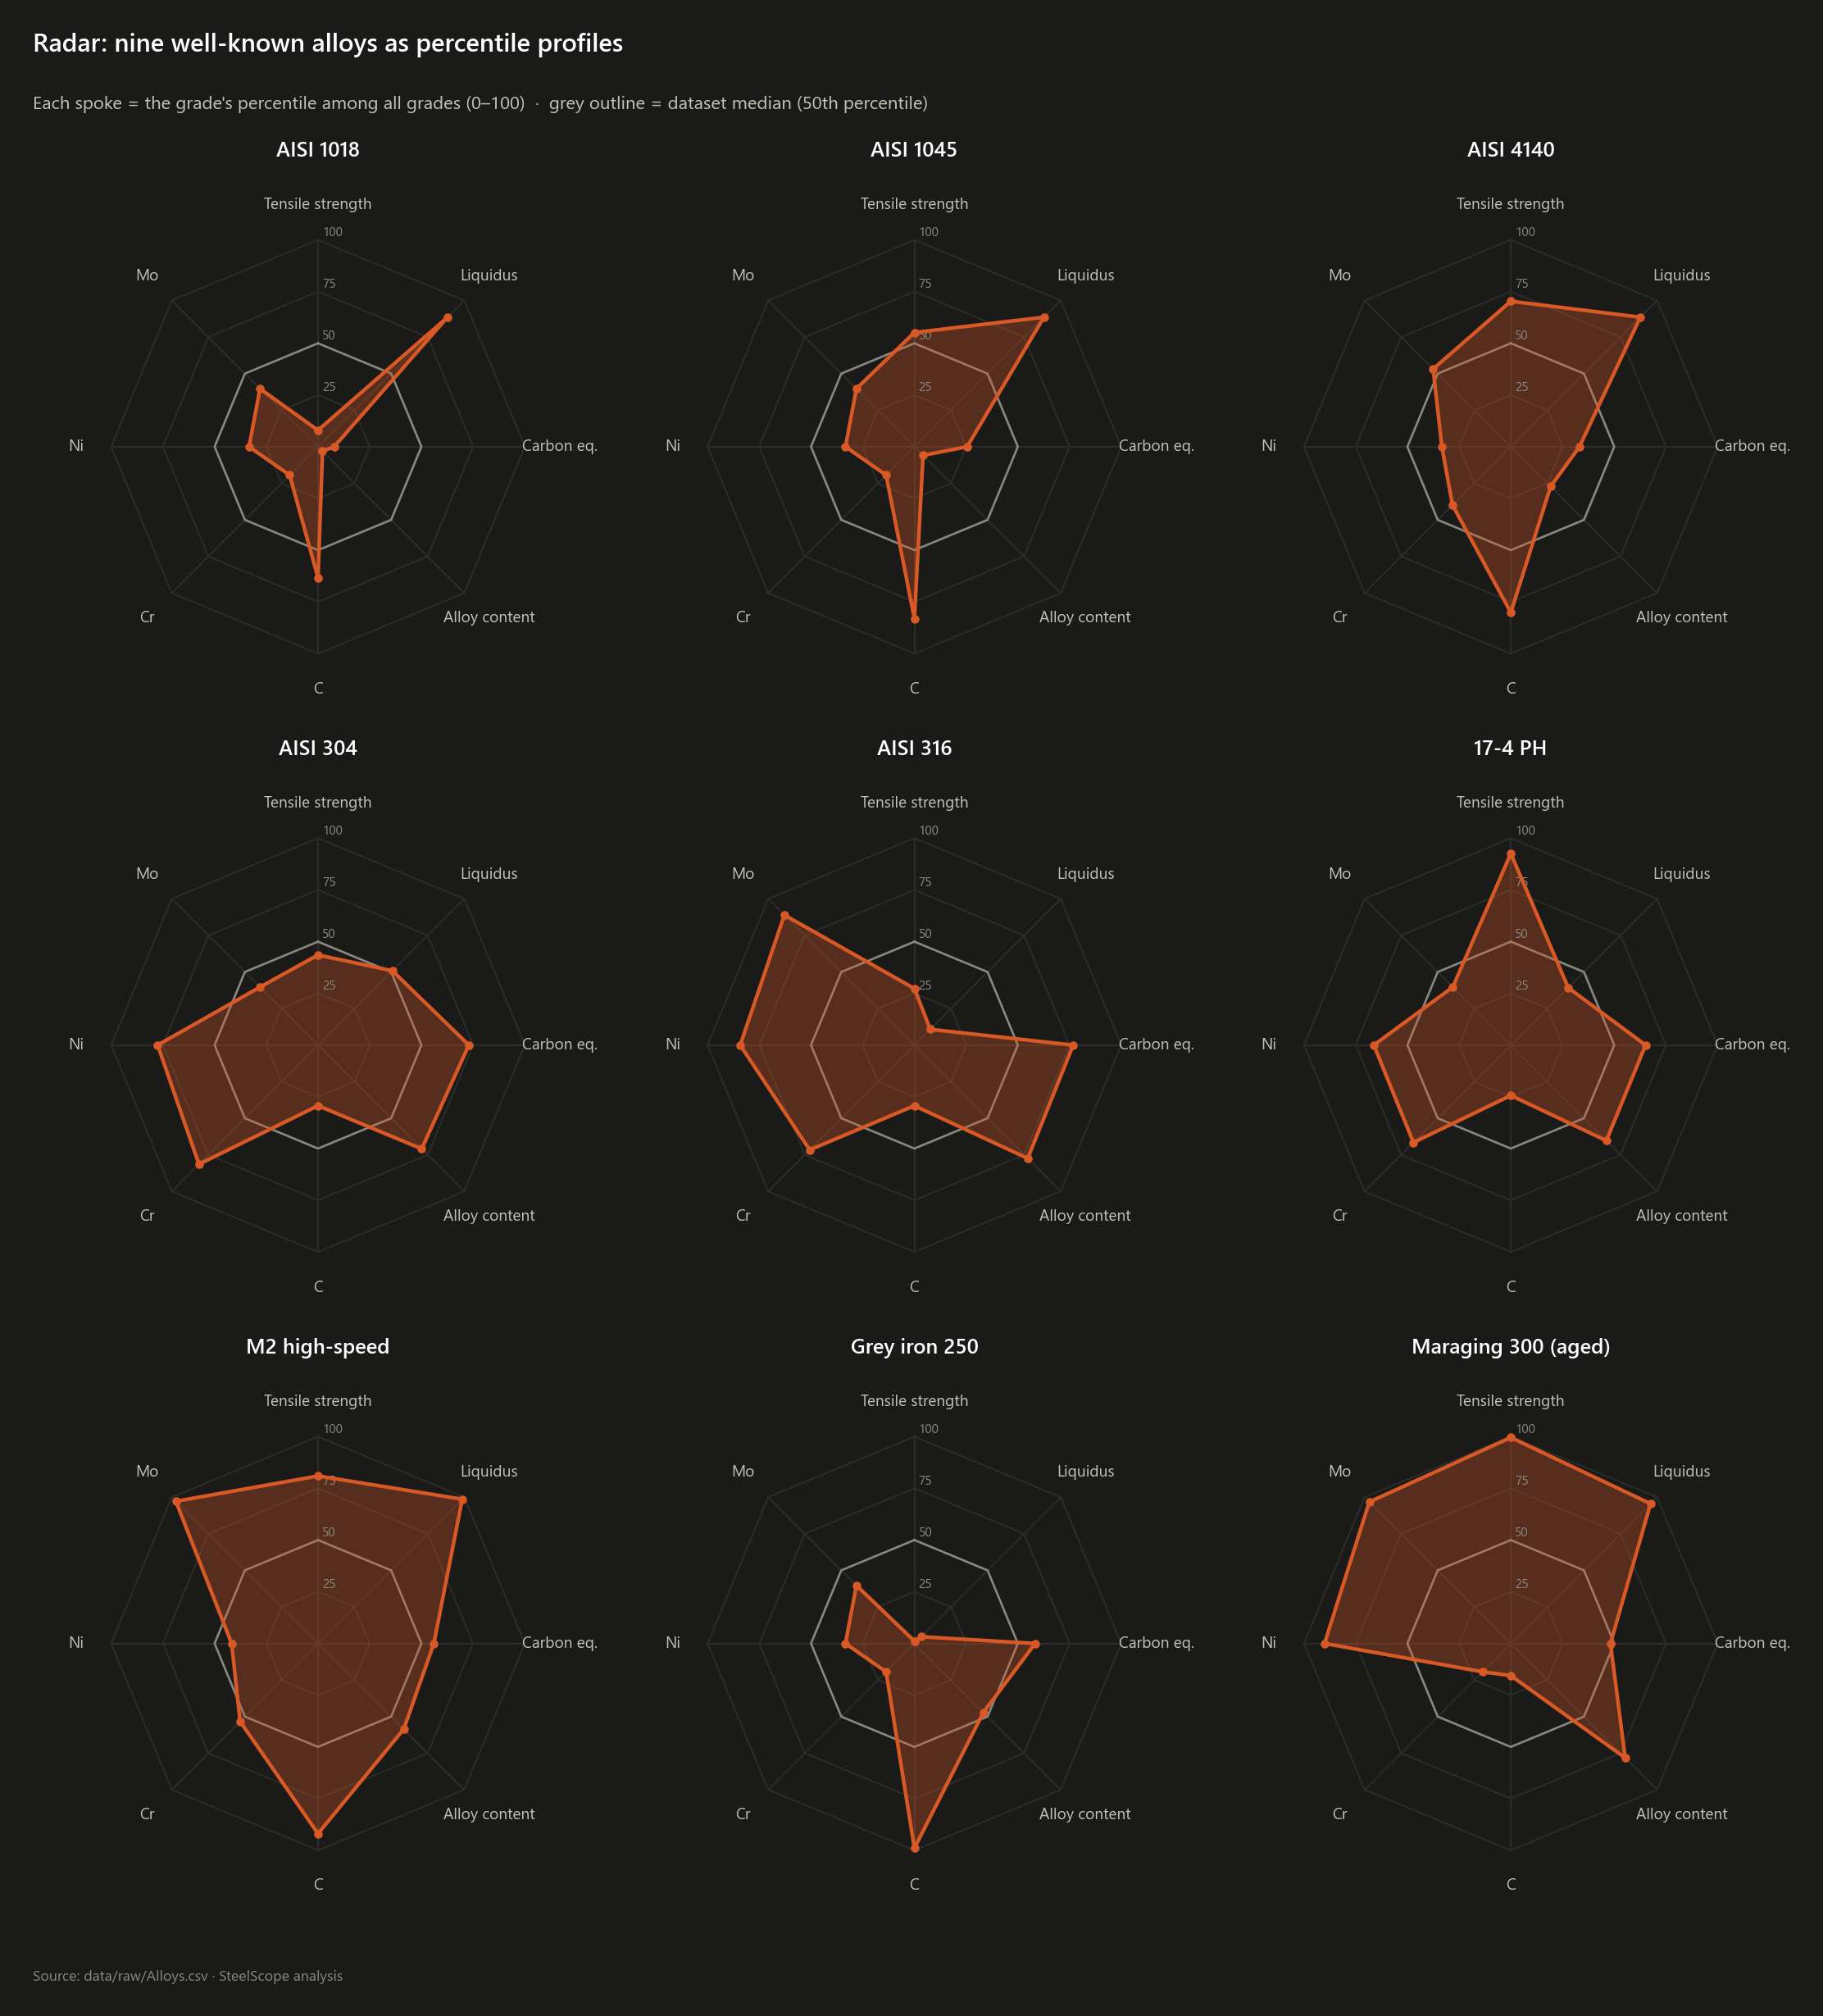

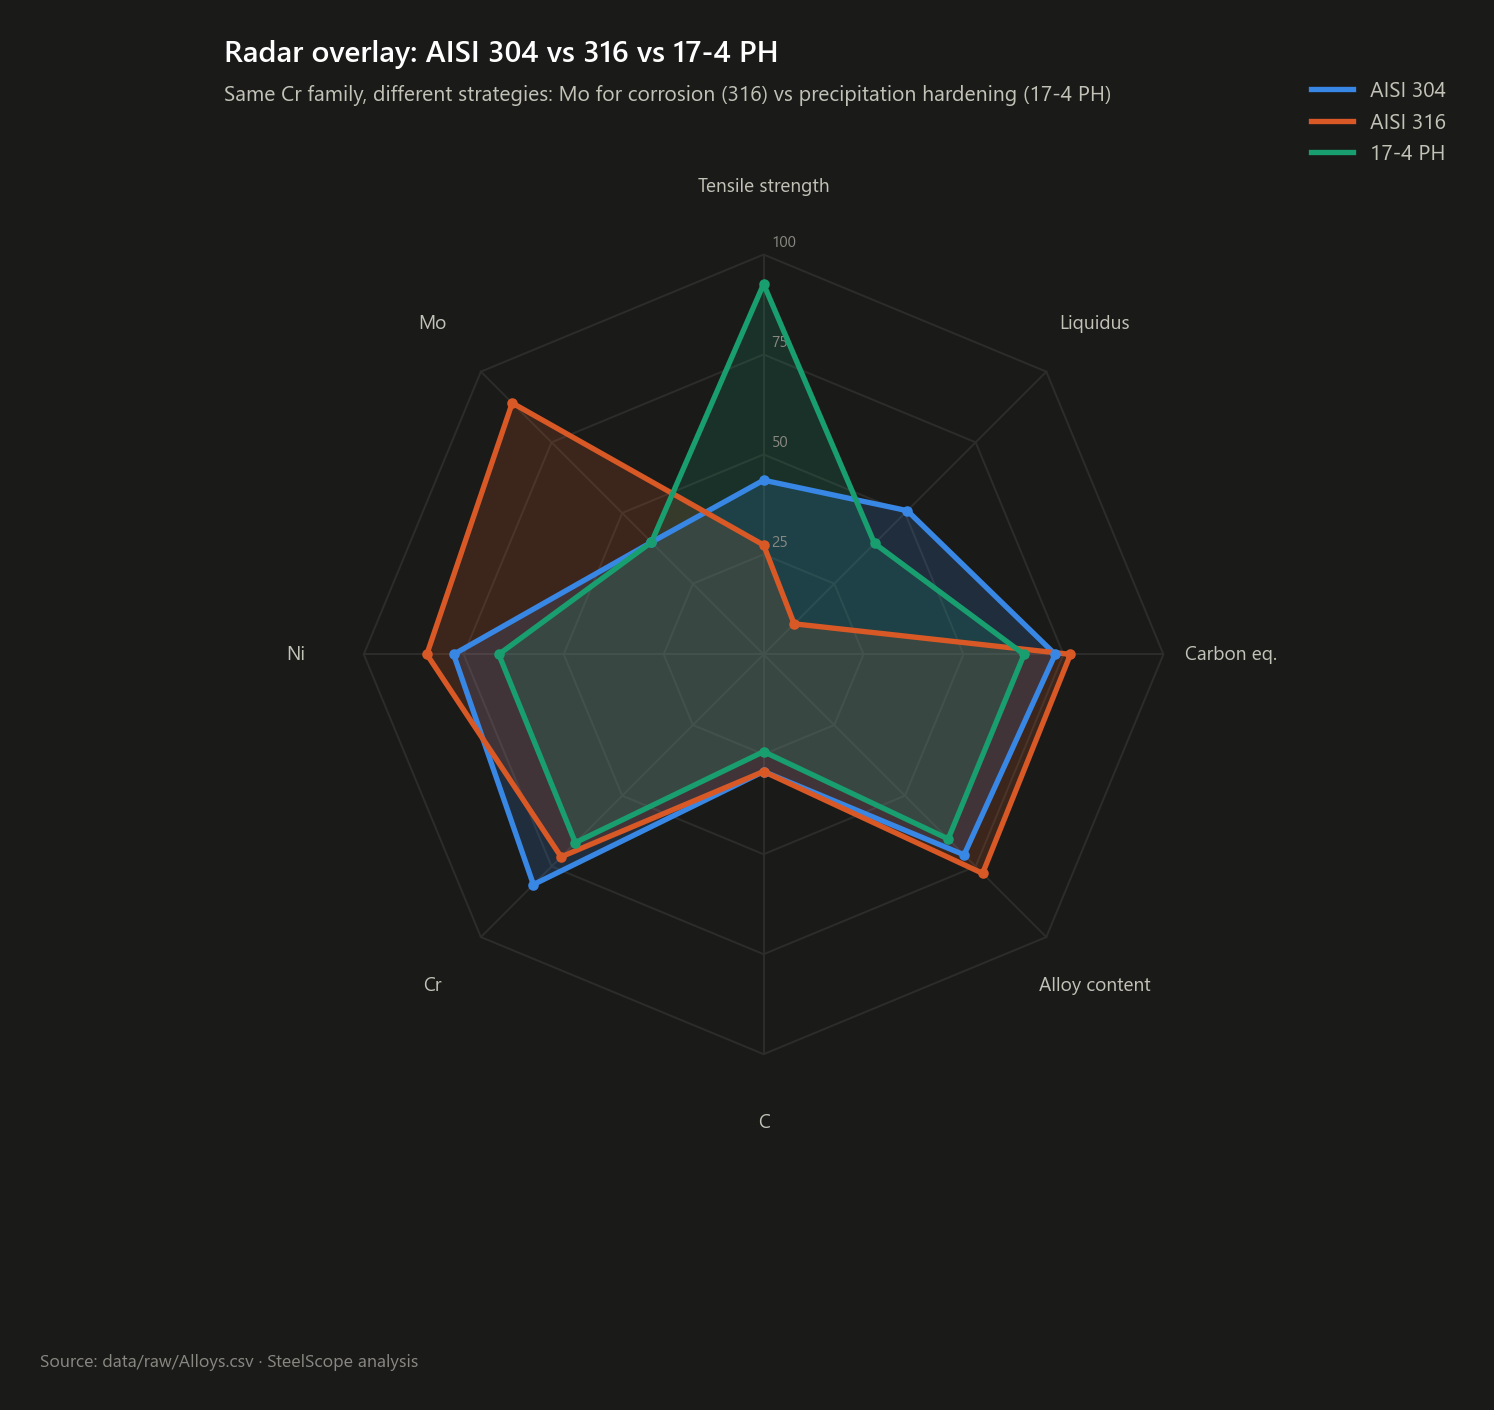

In [14]:
comp_scaled, comp_raw = V.radar_family_composition(grades)
display(comp_raw.round(3))
show(VS.radar_small_multiples(comp_scaled, VS.GROUP_COLOR, "Radar: median composition fingerprint of each family group",
                              "log-scaled median wt%, min-max across groups (outer ring = highest group)", cols=3),
     "04_28_radar_family_composition")
picks = V.showcase_grades(grades)
pct = V.radar_grade_percentiles(grades, picks)
display(picks[["short_name", "display_name", "tensile_strength_mpa", "liquidus_c", "carbon_equivalent"]]); display(pct.round(0))
median_ref = pd.Series(50.0, index=pct.columns)
show(VS.radar_small_multiples(pct, P.ORANGE, "Radar: nine well-known alloys as percentile profiles",
                              "Each spoke = the grade's percentile among all grades (0–100)", scale_max=100.0,
                              reference=median_ref, ref_label="dataset median (50th percentile)",
                              ring_labels=["25", "50", "75", "100"]), "04_29_radar_showcase_alloys")
show(VS.radar_overlay(pct.loc[["AISI 304", "AISI 316", "17-4 PH"]], [P.BLUE, P.ORANGE, P.AQUA],
                      "Radar overlay: AISI 304 vs 316 vs 17-4 PH",
                      "Same Cr family, different strategies: Mo for corrosion (316) vs precipitation hardening (17-4 PH)",
                      ring_labels=["25", "50", "75", "100"]), "04_30_radar_overlay_stainless")

**Takeaway.** The radars turn a 30-column composition table into shapes you can compare at a glance: high-speed
steels max out the W/V/Co/Mo spokes, stainless the Cr/Ni spokes, cast iron the C/Si spokes. Among the stainless
trio, 316 extends the Mo spoke (corrosion resistance), while 17-4 PH reaches far higher strength with *less* nickel:
strength comes from precipitation hardening, not alloy quantity.

## 10 · Waterfall charts

,step,value,kind,start,end,running_total
0,Raw rows,2672,total,0.000,2672,2672
1,Exact duplicates,-62,delta,"2,672.000",2610,2610
2,Twin listings merged,-1221,delta,"2,610.000",1389,1389
3,Canonical grades,1389,total,0.000,1389,1389
4,No measured TS,-7,delta,"1,389.000",1382,1382
5,Modelled grades,1382,total,0.000,1382,1382


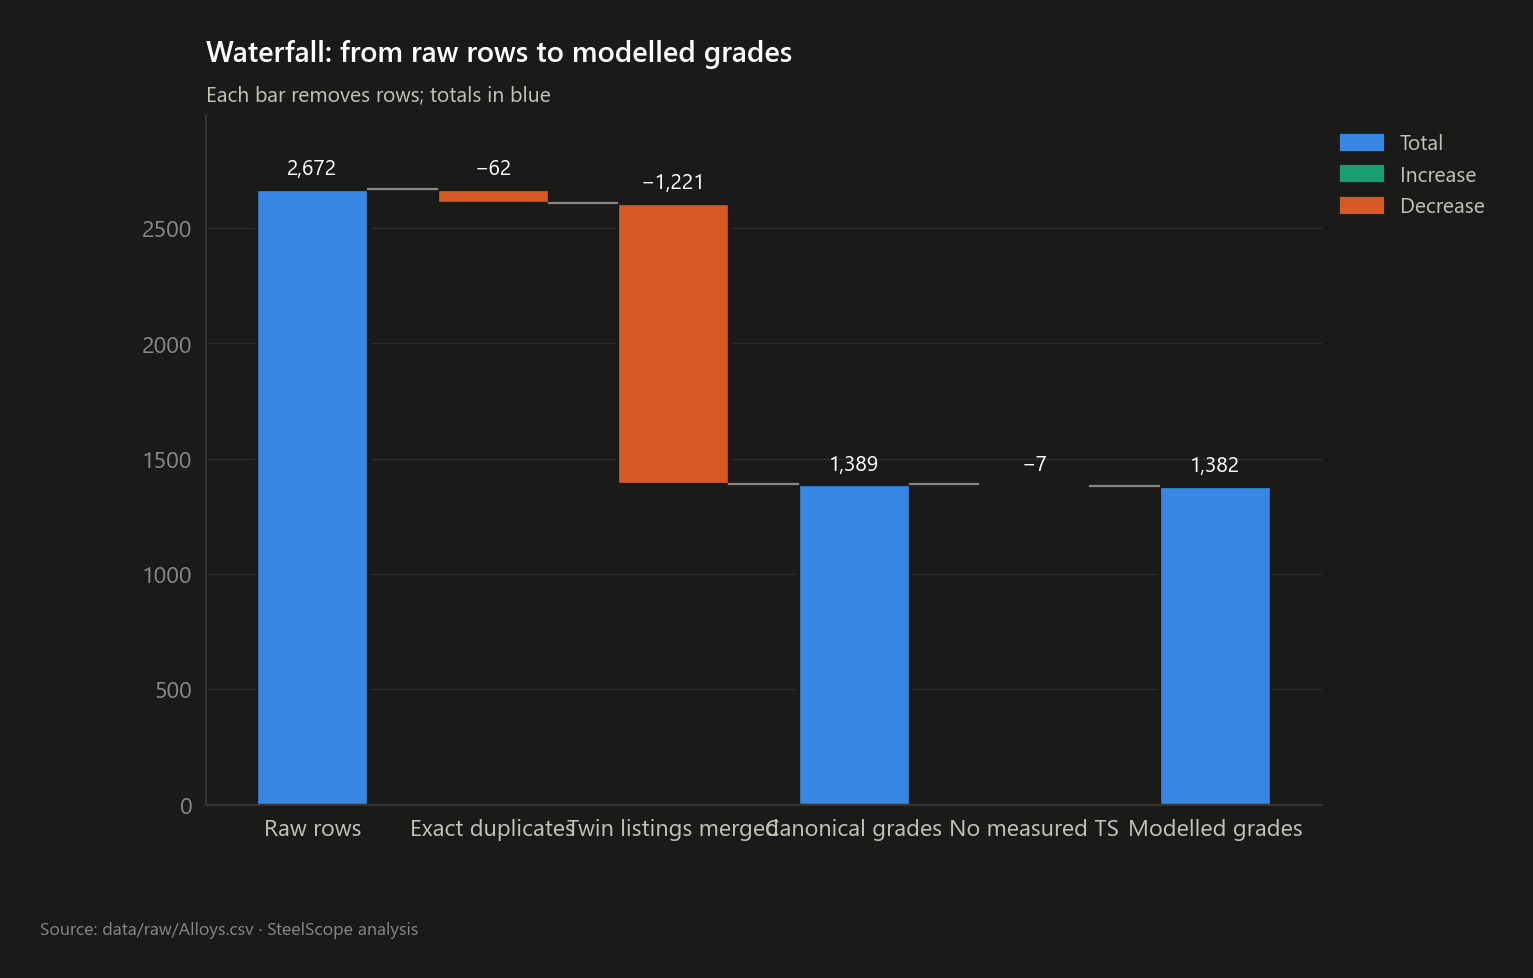

,step,value,kind
0,C,0.405,delta
1,Mn / 6,0.146,delta
2,Cr / 5,0.190,delta
3,Mo / 5,0.040,delta
4,V / 5,0.000,delta
5,Ni / 15,0.000,delta
6,Cu / 15,0.000,delta
7,Carbon equivalent,0.781,total


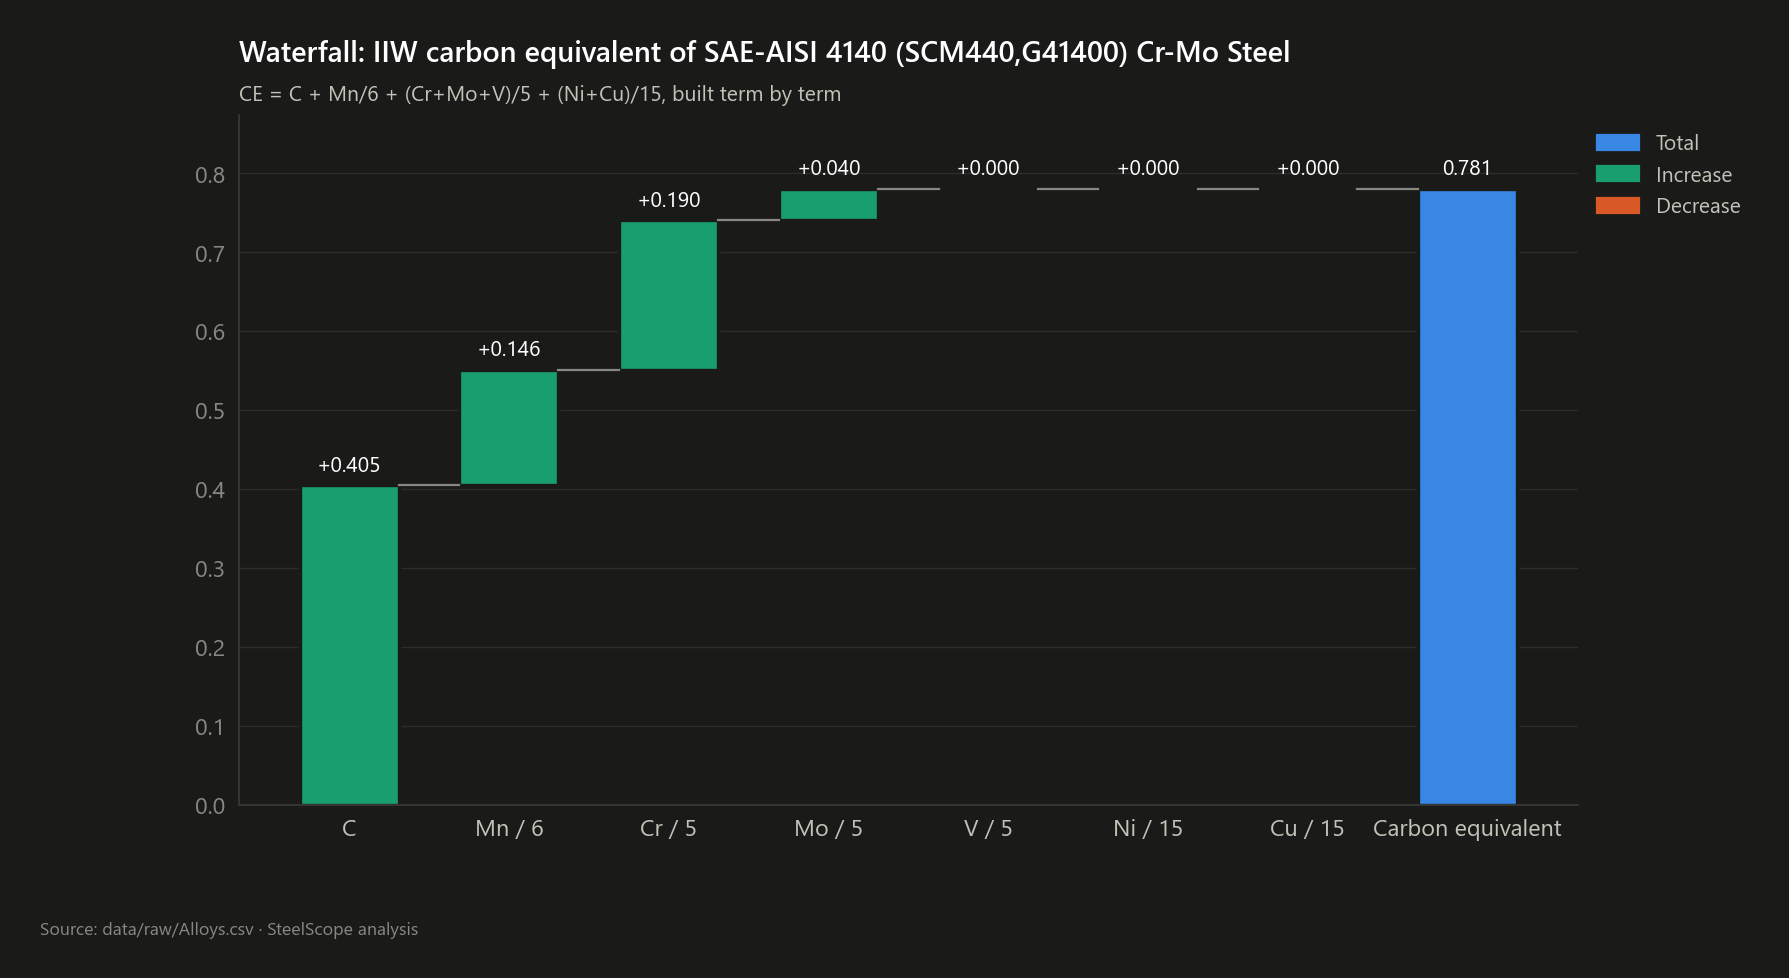

,step,value,kind
0,Average prediction,612.400,total
1,carbon equivalent = 0.781,40.700,delta
2,Ni equivalent = 12.6,23.200,delta
3,Cr equivalent = 1.52,-17.000,delta
4,C = 0.405,14.300,delta
5,Ni = 0,-10.700,delta
6,family = alloy,-9.100,delta
7,N = 0,-7.200,delta
8,19 other features,-19.000,delta
9,Predicted TS,627.600,total


{'grade': 'SAE-AISI 4140 (SCM440,G41400) Cr-Mo Steel', 'measured': 690.0, 'predicted': 627.6362930136912, 'model_predict': 627.6362930136926}


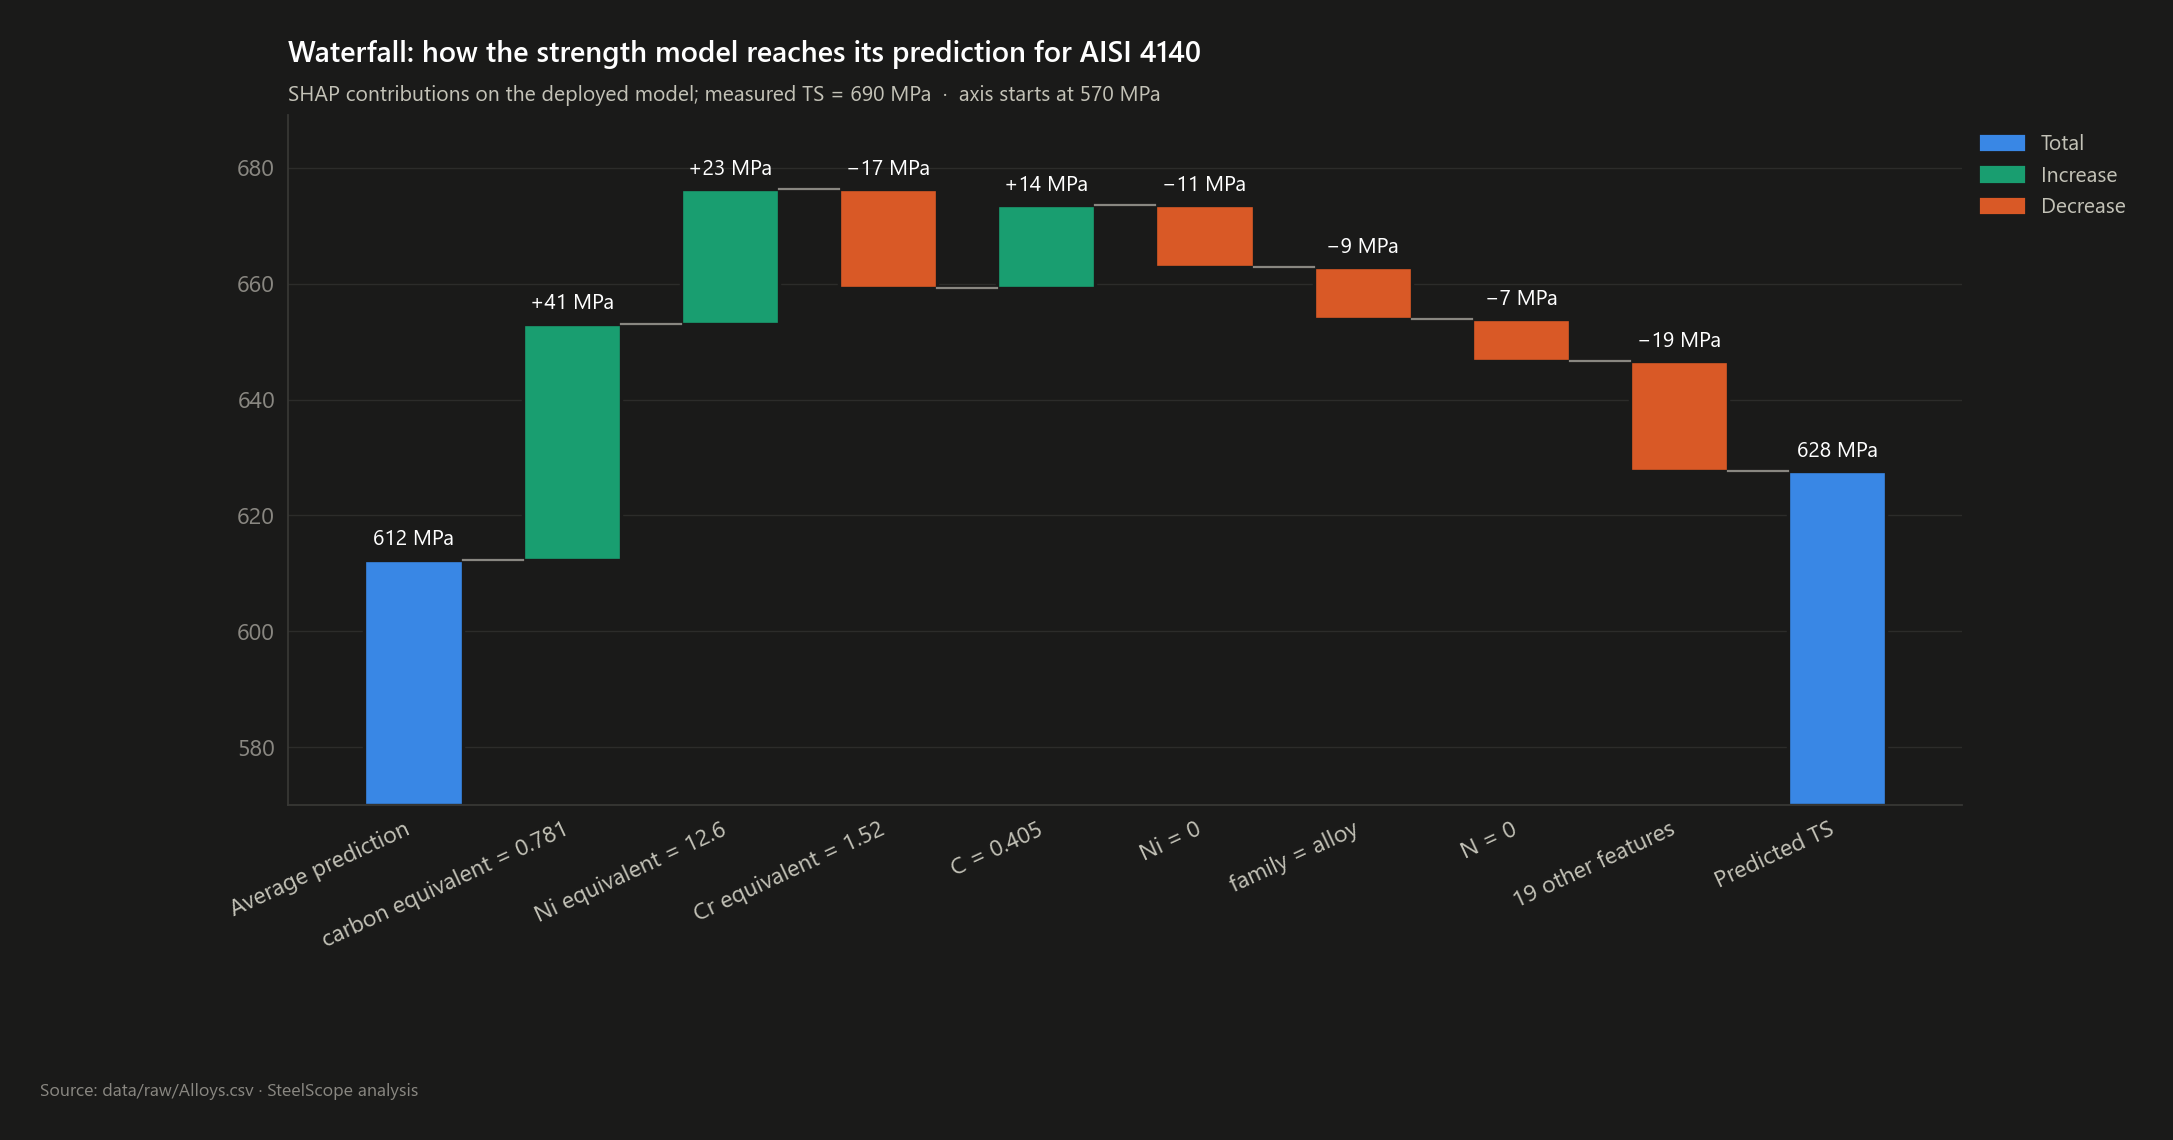

In [15]:
counts = {"raw": len(raw), "duplicates": int(raw.duplicated().sum()), "twins": int(len(listings) - len(grades)),
          "grades": len(grades), "unmeasured": int(grades[V.TS].isna().sum()), "measured": int(grades[V.TS].notna().sum())}
wf1 = V.waterfall_cleaning(counts); display(V.waterfall_layout(wf1))
show(VS.waterfall(wf1, "Waterfall: from raw rows to modelled grades", "Each bar removes rows; totals in blue", xlabel_rot=0),
     "04_31_waterfall_cleaning")
r4140 = grades[grades.display_name.str.startswith(V.SHOWCASE_GRADES["AISI 4140"])].iloc[0]
wf2 = V.waterfall_ce(r4140); display(wf2.round(4))
show(VS.waterfall(wf2, f"Waterfall: IIW carbon equivalent of {r4140.display_name}",
                  "CE = C + Mn/6 + (Cr+Mo+V)/5 + (Ni+Cu)/15, built term by term", fmt="{:.3f}"), "04_32_waterfall_ce_4140")
wf3, info = V.prediction_waterfall(grades, V.SHOWCASE_GRADES["AISI 4140"])
display(wf3.round(1)); print(info)
show(VS.waterfall(wf3, "Waterfall: how the strength model reaches its prediction for AISI 4140",
                  f"SHAP contributions on the deployed model; measured TS = {info['measured']:.0f} MPa", unit=" MPa",
                  xlabel_rot=25, zero_based=False), "04_33_waterfall_prediction_4140")

**Takeaway.** Waterfalls make additive stories obvious. The cleaning waterfall shows that twin listings, not
duplicates or missing values, are the dominant data issue. The CE waterfall shows that for 4140 carbon and
chromium contribute most of the weldability index, and the total lands in the 'difficult' band (CE > 0.60): preheat
and controlled welding procedures are needed. The SHAP waterfall decomposes one model
prediction into feature pushes that sum exactly to the prediction.

## 11 · Parallel coordinates

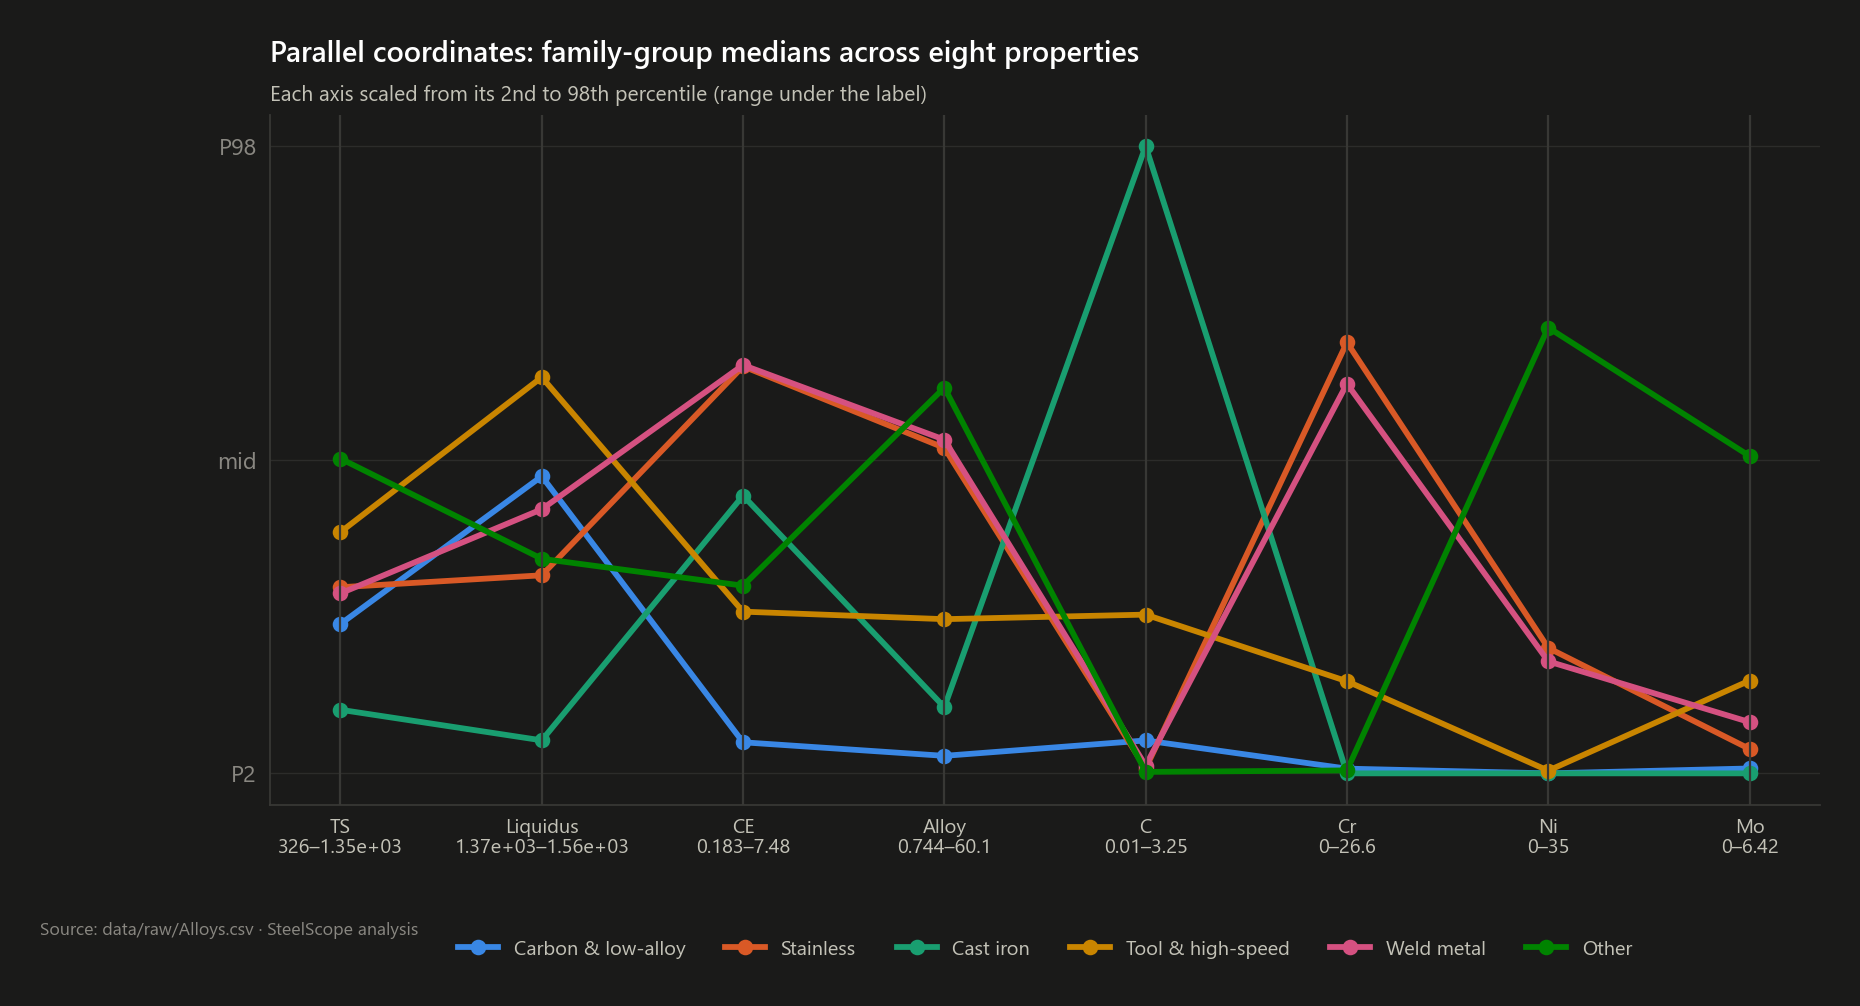

In [16]:
show(VS.parallel_coordinates(g), "04_34_parallel_coordinates")

## 12 · Export helper files for Tableau and expected values for KNIME

In [17]:
from src.analysis import viz_exports as VX
res = VX.build_viz_exports(grades); VX.save(res)
print(sorted(res["tableau"]))
res["knime"].head(12)

['binned_grades.csv', 'binning_comparison.csv', 'chi_square_cells.csv', 'chi_square_tests.csv', 'chord_family_to_cluster.csv', 'chord_raw_class_migration.csv', 'descriptive_stats.csv', 'five_number_summary.csv', 'flows_family_to_cluster.csv', 'flows_raw_class_migration.csv', 'kmeans_scan.csv', 'pca_explained.csv', 'pca_kmeans_scores.csv', 'pca_loadings.csv', 'radar_family_composition.csv', 'radar_showcase_grades.csv', 'radial_bars_family_ts.csv', 'regression_coefficients.csv', 'regression_simple_band.csv', 'waterfall_ce_aisi4140.csv', 'waterfall_cleaning.csv', 'waterfall_prediction_aisi4140.csv']


,section,item,value
0,Five-number summary,tensile_strength_mpa | n,1382
1,Five-number summary,tensile_strength_mpa | min,140.000
2,Five-number summary,tensile_strength_mpa | Q1,510.000
3,Five-number summary,tensile_strength_mpa | median,610.000
4,Five-number summary,tensile_strength_mpa | Q3,720.000
5,Five-number summary,tensile_strength_mpa | max,"2,450.000"
6,Five-number summary,tensile_strength_mpa | IQR,210.000
7,Five-number summary,tensile_strength_mpa | n_outliers,75
8,Five-number summary,liquidus_c | n,1389
9,Five-number summary,liquidus_c | min,"1,160.000"
